# Formula 1 Podium Prediction Companion — Milestone 1

## Overview and prediction cutoff

The goal is binary classification: predict whether a Formula 1 driver will finish in the top three (`podium = 1`) or outside the podium (`podium = 0`). The unit of analysis is **one driver–race entry** identified by `(raceId, driverId)`. Predictions are made **after qualifying and before the main race begins**.

The project uses the Formula 1 World Championship relational dataset (1950–2024), comprising 14 CSV tables. The workflow covers data auditing, cleaning, exploratory analysis, three data-engineering questions, leakage-aware feature engineering, chronological splitting, three classifiers, controlled experiments, explainable AI, and inference.

**Leakage rule:** current-race finishing position, points, status, laps, pit stops, and post-race standings may be used to define historical labels or retrospective analyses but **must not be used as predictors for that same race**. Features measuring past performance must use earlier races only.

**Execution and verification status:** The corrected notebook completed a clean Save & Run All as Version 13 (scriptVersionId 359134370) on 16 October 2026 (127.6 seconds). All 125 Python cells executed in order; all 14 primary-key and 23 foreign-key checks passed; the final audit passed; and 42 output figures were present and loaded in the saved viewer. Numerical Markdown was reconciled against those actual outputs. The subsequent final release preserves the Python source and refreshes this explanatory text. No assignment submission, sharing change or GitHub modification is part of this validation.


In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

sns.set_theme(style="whitegrid")

print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("Libraries imported successfully!")

/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/races.csv
/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/constructor_results.csv
/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/drivers.csv
/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/constructors.csv
/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/lap_times.csv
/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/status.csv
/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/driver_standings.csv
/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/seasons.csv
/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/pit_stops.csv
/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/sprint_results.csv
/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/constructor_standings.csv
/kaggle/input/datasets/rohanrao/formula

In [2]:
import tensorflow as tf

gpus = tf.config.list_physical_devices("GPU")
print("Available GPUs:", gpus)

if not gpus:
    print("No GPU detected. Using CPU.")

Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


## Phase 1 — Dataset Loading and Relational Inspection

**Verification status:** Numerical statements were reconciled with the successful clean saved execution (Version 13, 16 October 2026). Audit results, statistical tables and plotted outputs provide the evidence; predictive associations do not establish causation.

The 14 CSV files are loaded into the `tables` dictionary, with the missing-value sentinel `\\N` treated as missing during import. We inspect table sizes, schema, candidate primary keys, cross-table foreign keys, and driver–race duplicates before modeling.

The dataset includes approximately **1,125 races, 861 drivers, 212 constructors, and 26,759 raw result rows**. These are descriptive dataset counts, not training-set sizes. Foreign-key checks identify broken references, while primary-key checks test uniqueness and null values. A separate driver–race uniqueness check is necessary even if `resultId` itself is unique.

**Why this matters:** joins from incompatible grains can multiply records and produce falsely optimistic statistics. The eventual modeling grain must be unique by `(raceId, driverId)`.


In [3]:
data_root = Path("/kaggle/input")

csv_files = sorted(data_root.rglob("*.csv"))

print("Total CSV files found:", len(csv_files))

for file in csv_files:
    print(file)

Total CSV files found: 14
/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/circuits.csv
/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/constructor_results.csv
/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/constructor_standings.csv
/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/constructors.csv
/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/driver_standings.csv
/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/drivers.csv
/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/lap_times.csv
/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/pit_stops.csv
/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/qualifying.csv
/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/races.csv
/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/results.csv
/kaggle/input/d

In [4]:
required_tables = [
    "circuits",
    "constructors",
    "constructor_results",
    "constructor_standings",
    "drivers",
    "driver_standings",
    "races",
    "results",
    "qualifying",
    "lap_times",
    "pit_stops",
    "sprint_results",
    "seasons",
    "status"
]

tables = {}

for name in required_tables:
    matches = [
        file for file in csv_files
        if file.name == f"{name}.csv"
    ]

    if len(matches) != 1:
        raise ValueError(
            f"Expected one {name}.csv, found {len(matches)}"
        )

    tables[name] = pd.read_csv(
        matches[0],
        na_values=[r"\N"]
    )

    print(
        f"{name}: {tables[name].shape[0]} rows, "
        f"{tables[name].shape[1]} columns"
    )

circuits: 77 rows, 9 columns
constructors: 212 rows, 5 columns
constructor_results: 12625 rows, 5 columns
constructor_standings: 13391 rows, 7 columns
drivers: 861 rows, 9 columns
driver_standings: 34863 rows, 7 columns
races: 1125 rows, 18 columns
results: 26759 rows, 18 columns
qualifying: 10494 rows, 9 columns
lap_times: 589081 rows, 6 columns
pit_stops: 11371 rows, 7 columns
sprint_results: 360 rows, 16 columns
seasons: 75 rows, 2 columns
status: 139 rows, 2 columns


In [5]:
summary = []

for name, df in tables.items():
    summary.append({
        "Table": name,
        "Rows": df.shape[0],
        "Columns": df.shape[1],
        "Missing Cells": df.isna().sum().sum(),
        "Duplicate Rows": df.duplicated().sum()
    })

summary_df = pd.DataFrame(summary)

display(summary_df)

,Table,Rows,Columns,Missing Cells,Duplicate Rows
0,circuits,77,9,0,0
1,constructors,212,5,0,0
2,constructor_results,12625,5,12608,0
3,constructor_standings,13391,7,0,0
4,drivers,861,9,1559,0
5,driver_standings,34863,7,0,0
6,races,1125,18,11349,0
7,results,26759,18,122887,0
8,qualifying,10494,9,11668,0
9,lap_times,589081,6,0,0


In [6]:
for name, df in tables.items():
    print(f"\n===== {name.upper()} =====")

    display(pd.DataFrame({
        "Column": df.columns,
        "Data Type": df.dtypes.astype(str).values,
        "Missing": df.isna().sum().values
    }))


===== CIRCUITS =====


,Column,Data Type,Missing
0,circuitId,int64,0
1,circuitRef,object,0
2,name,object,0
3,location,object,0
4,country,object,0
5,lat,float64,0
6,lng,float64,0
7,alt,int64,0
8,url,object,0



===== CONSTRUCTORS =====


,Column,Data Type,Missing
0,constructorId,int64,0
1,constructorRef,object,0
2,name,object,0
3,nationality,object,0
4,url,object,0



===== CONSTRUCTOR_RESULTS =====


...

,Column,Data Type,Missing
0,resultId,int64,0
1,raceId,int64,0
2,driverId,int64,0
3,constructorId,int64,0
4,number,int64,0
5,grid,int64,0
6,position,float64,15
7,positionText,object,0
8,positionOrder,int64,0
9,points,int64,0



===== SEASONS =====


,Column,Data Type,Missing
0,year,int64,0
1,url,object,0



===== STATUS =====


,Column,Data Type,Missing
0,statusId,int64,0
1,status,object,0


In [7]:
# Primary keys for all 14 source tables; composite keys preserve table grain.
primary_keys = {
    "circuits": "circuitId", "constructors": "constructorId",
    "drivers": "driverId", "races": "raceId", "results": "resultId",
    "qualifying": "qualifyId", "status": "statusId",
    "constructor_results": "constructorResultsId",
    "constructor_standings": "constructorStandingsId",
    "driver_standings": "driverStandingsId", "seasons": "year",
    "lap_times": ["raceId", "driverId", "lap"],
    "pit_stops": ["raceId", "driverId", "stop"],
    "sprint_results": "resultId"
}
assert set(primary_keys) == set(required_tables)
pk_rows = []
for name, key in primary_keys.items():
    cols = [key] if isinstance(key, str) else list(key)
    df = tables[name]
    pk_rows.append({"Table": name, "Key": ", ".join(cols),
                    "Duplicate keys": int(df.duplicated(cols).sum()),
                    "Rows with null key": int(df[cols].isna().any(axis=1).sum())})
pk_report = pd.DataFrame(pk_rows)
display(pk_report)
assert pk_report[["Duplicate keys", "Rows with null key"]].eq(0).all().all(), "Raw primary-key validation failed"


,Table,Key,Duplicate keys,Rows with null key
0,circuits,circuitId,0,0
1,constructors,constructorId,0,0
2,drivers,driverId,0,0
3,races,raceId,0,0
4,results,resultId,0,0
5,qualifying,qualifyId,0,0
6,status,statusId,0,0
7,constructor_results,constructorResultsId,0,0
8,constructor_standings,constructorStandingsId,0,0
9,driver_standings,driverStandingsId,0,0


In [8]:
results = tables["results"]

duplicate_driver_races = results[
    results.duplicated(
        subset=["raceId", "driverId"],
        keep=False
    )
].sort_values(["raceId", "driverId"])

print(
    "Rows involved in duplicate driver-race pairs:",
    len(duplicate_driver_races)
)

display(duplicate_driver_races.head(20))

Rows involved in duplicate driver-race pairs: 176


,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId
13188,13189,540,229,54,10.0,0,NaN,F,26,0.0,0,NaN,NaN,NaN,NaN,NaN,NaN,81
13191,13192,540,229,57,23.0,0,NaN,F,29,0.0,0,NaN,NaN,NaN,NaN,NaN,NaN,97
17362,17363,717,373,172,1.0,1,7.0,7,7,0.0,102,NaN,NaN,NaN,NaN,NaN,NaN,60
24298,24304,717,373,172,2.0,1,NaN,R,12,0.0,54,NaN,NaN,NaN,NaN,NaN,NaN,98
17740,17741,733,465,172,48.0,0,NaN,W,22,0.0,0,NaN,NaN,NaN,NaN,NaN,NaN,54
17743,17744,733,465,97,50.0,0,NaN,W,25,0.0,0,NaN,NaN,NaN,NaN,NaN,NaN,54
17961,17962,742,475,102,26.0,20,NaN,D,19,0.0,56,NaN,NaN,NaN,NaN,NaN,NaN,2
17963,17964,742,475,172,28.0,5,NaN,R,21,0.0,44,NaN,NaN,NaN,NaN,NaN,NaN,23
18062,18063,745,418,172,22.0,11,NaN,R,17,0.0,23,NaN,NaN,NaN,NaN,NaN,NaN,6
24297,24303,745,418,172,21.0,15,11.0,11,11,0.0,92,NaN,NaN,NaN,NaN,NaN,NaN,18


In [9]:
missing_summary = []

for name, df in tables.items():
    for column in df.columns:
        missing_summary.append({
            "Table": name,
            "Column": column,
            "Missing Count": df[column].isna().sum(),
            "Missing %": round(
                df[column].isna().mean() * 100, 2
            )
        })

missing_df = pd.DataFrame(missing_summary)

display(
    missing_df.sort_values(
        "Missing %",
        ascending=False
    ).head(20)
)

,Table,Column,Missing Count,Missing %
18,constructor_results,status,12608,99.87
59,races,sprint_time,1110,98.67
58,races,sprint_date,1107,98.40
55,races,fp3_time,1072,95.29
51,races,fp1_time,1057,93.96
57,races,quali_time,1057,93.96
53,races,fp2_time,1057,93.96
54,races,fp3_date,1053,93.60
28,drivers,number,802,93.15
56,races,quali_date,1035,92.00


In [10]:
races = tables["races"]

print("Earliest season:", races["year"].min())
print("Latest season:", races["year"].max())
print("Total races:", len(races))
print("Total seasons:", races["year"].nunique())

Earliest season: 1950
Latest season: 2024
Total races: 1125
Total seasons: 75


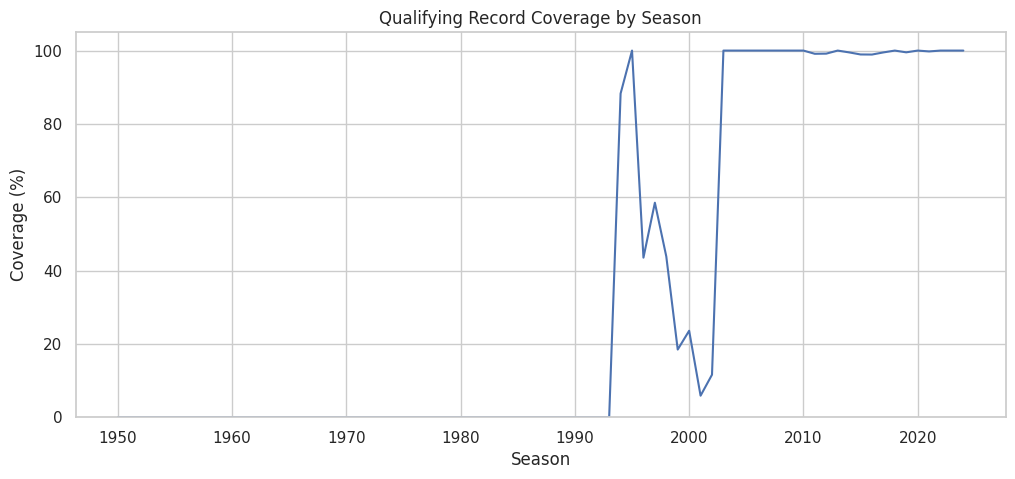

In [11]:
qualifying = tables["qualifying"]

qualifying_pairs = qualifying[
    ["raceId", "driverId"]
].drop_duplicates()

race_entries = results[
    ["raceId", "driverId"]
].drop_duplicates()

coverage = race_entries.merge(
    races[["raceId", "year"]],
    on="raceId",
    how="left",
    validate="many_to_one"
)

coverage = coverage.merge(
    qualifying_pairs.assign(has_qualifying=1),
    on=["raceId", "driverId"],
    how="left",
    validate="one_to_one"
)

qualifying_coverage = (
    coverage.groupby("year")["has_qualifying"]
    .apply(lambda s: s.notna().mean() * 100)
)

qualifying_coverage.plot(
    figsize=(12, 5),
    title="Qualifying Record Coverage by Season"
)

plt.xlabel("Season")
plt.ylabel("Coverage (%)")
plt.ylim(0, 105)
plt.show()

## Phase 2 — Exploratory Data Analysis (Before Cleaning)

**Verification status:** Numerical statements were reconciled with the successful clean saved execution (Version 13, 16 October 2026). Audit results, statistical tables and plotted outputs provide the evidence; predictive associations do not establish causation.

Exploration covers seasonal race counts, class balance, grid position, qualifying coverage, driver and constructor historical performance, missingness, duplicate driver–race entries, and historical eras. Plots are used to motivate the later cleaning rules and feature choices rather than relying on manual inspection alone.

**Main observations:** The raw podium class is relatively rare (approximately **12.69%**), so accuracy alone would be misleading. Starting grid positions one and two have much higher podium conversion rates than later grid positions. Qualifying-record coverage differs sharply by era, which supports a more recent primary training window. These are historical **associations**, not evidence that a specific grid slot or rule change causes a podium.


In [12]:
# Check 1: Historical coverage
print("Earliest season:", tables["races"]["year"].min())
print("Latest season:", tables["races"]["year"].max())

# Check 2: Duplicate driver-race combinations
results = tables["results"]

duplicate_pairs = results.duplicated(
    subset=["raceId", "driverId"],
    keep=False
)

print(
    "Rows in duplicate driver-race groups:",
    duplicate_pairs.sum()
)

# Check 3: Primary key uniqueness
for name, key in primary_keys.items():
    df = tables[name]
    cols = [key] if isinstance(key, str) else list(key)

    print(
        f"{name}:",
        "Duplicate keys =", df.duplicated(cols).sum(),
        "| Missing keys =", df[cols].isna().any(axis=1).sum()
    )

# Check 4: Foreign key relationships
relationships = [
    ("results", "raceId", "races", "raceId"),
    ("results", "driverId", "drivers", "driverId"),
    ("results", "constructorId", "constructors", "constructorId"),
    ("results", "statusId", "status", "statusId"),
    ("races", "circuitId", "circuits", "circuitId"),
    ("qualifying", "raceId", "races", "raceId"),
    ("qualifying", "driverId", "drivers", "driverId"),
]

for child, fk, parent, pk in relationships:
    missing_references = (
        ~tables[child][fk].dropna().isin(tables[parent][pk])
    ).sum()

    print(
        f"{child}.{fk} -> {parent}.{pk}:",
        missing_references,
        "invalid references"
    )


Earliest season: 1950
Latest season: 2024
Rows in duplicate driver-race groups: 176
circuits: Duplicate keys = 0 | Missing keys = 0
constructors: Duplicate keys = 0 | Missing keys = 0
drivers: Duplicate keys = 0 | Missing keys = 0
races: Duplicate keys = 0 | Missing keys = 0
results: Duplicate keys = 0 | Missing keys = 0
qualifying: Duplicate keys = 0 | Missing keys = 0
status: Duplicate keys = 0 | Missing keys = 0
constructor_results: Duplicate keys = 0 | Missing keys = 0
constructor_standings: Duplicate keys = 0 | Missing keys = 0
driver_standings: Duplicate keys = 0 | Missing keys = 0
seasons: Duplicate keys = 0 | Missing keys = 0
lap_times: Duplicate keys = 0 | Missing keys = 0
pit_stops: Duplicate keys = 0 | Missing keys = 0
sprint_results: Duplicate keys = 0 | Missing keys = 0
results.raceId -> races.raceId: 0 invalid references
results.driverId -> drivers.driverId: 0 invalid references
results.constructorId -> constructors.constructorId: 0 invalid references
results.statusId -> 

In [13]:
races = tables["races"]
results = tables["results"]
drivers = tables["drivers"]
constructors = tables["constructors"]

# Calculate basic dataset statistics
total_races = races["raceId"].nunique()
total_drivers = drivers["driverId"].nunique()
total_constructors = constructors["constructorId"].nunique()
total_seasons = races["year"].nunique()

print("Total races:", total_races)
print("Total drivers:", total_drivers)
print("Total constructors:", total_constructors)
print("Total seasons:", total_seasons)
print("Total result records:", len(results))

Total races: 1125
Total drivers: 861
Total constructors: 212
Total seasons: 75
Total result records: 26759


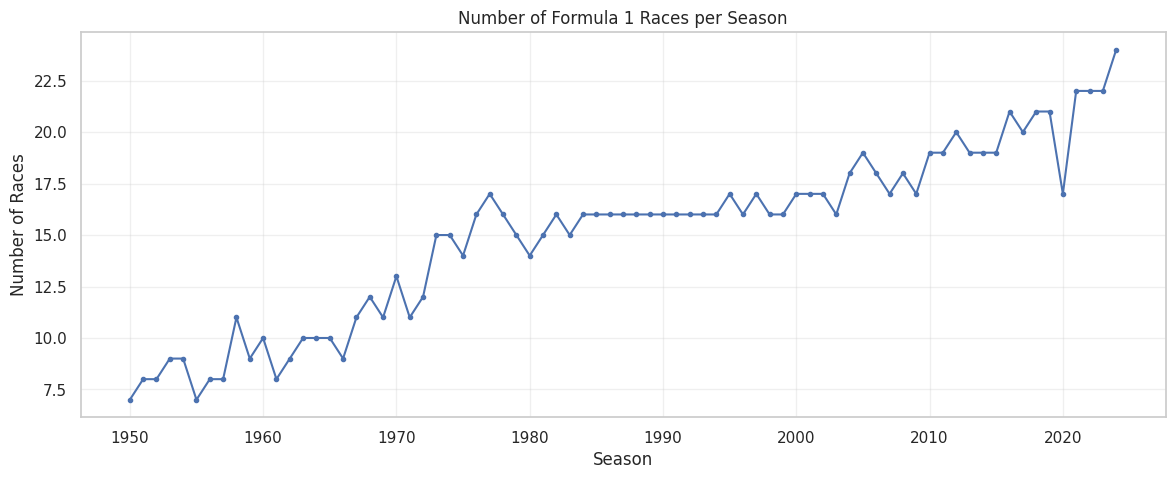

In [14]:
races_per_season = (
    races.groupby("year")["raceId"]
    .nunique()
)

plt.figure(figsize=(14, 5))

plt.plot(
    races_per_season.index,
    races_per_season.values,
    marker="o",
    markersize=3
)

plt.title("Number of Formula 1 Races per Season")
plt.xlabel("Season")
plt.ylabel("Number of Races")
plt.grid(alpha=0.3)

plt.show()

podium
0    23362
1     3397
Name: count, dtype: int64

Podium percentage: 12.69 %


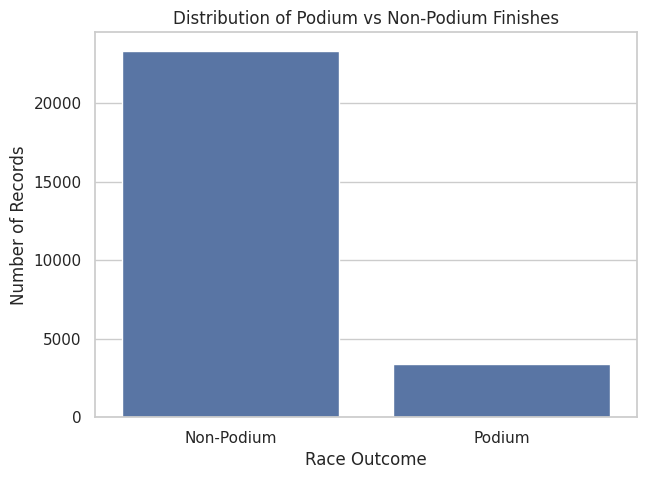

In [15]:
# Create a temporary target for exploratory analysis
eda_results = results.copy()

eda_results["podium"] = (
    eda_results["positionOrder"] <= 3
).astype(int)

podium_counts = (
    eda_results["podium"]
    .value_counts()
    .sort_index()
)

print(podium_counts)

print(
    "\nPodium percentage:",
    round(eda_results["podium"].mean() * 100, 2),
    "%"
)

plt.figure(figsize=(7, 5))

sns.countplot(
    data=eda_results,
    x="podium"
)

plt.xticks(
    [0, 1],
    ["Non-Podium", "Podium"]
)

plt.title("Distribution of Podium vs Non-Podium Finishes")
plt.xlabel("Race Outcome")
plt.ylabel("Number of Records")

plt.show()

### EDA Findings — Dataset Overview and Target Distribution

**Verification status:** Numerical statements were reconciled with the successful clean saved execution (Version 13, 16 October 2026). Audit results, statistical tables and plotted outputs provide the evidence; predictive associations do not establish causation.

**1. Dataset Overview**

The dataset contains 1,125 races across 75 seasons (1950–2024), with 861 registered drivers, 212 constructors, and 26,759 race-result records.

**2. Races per Season**

The races-per-season visualization shows an overall increase in the number of championship races over time, with fluctuations across different periods. This suggests that raw historical performance counts may not be directly comparable between seasons. Performance rates could provide more meaningful comparisons.

**3. Podium Class Distribution**

The target distribution contains 23,362 non-podium records (87.31%) and 3,397 podium records (12.69%).

This indicates a class imbalance. A majority-class classifier would achieve approximately 87.31% accuracy while failing to identify any podium finishers.

Therefore, accuracy alone is not an appropriate evaluation criterion. PR-AUC, ROC-AUC, and F1 score will be used to compare the predictive models, with PR-AUC proposed as the primary metric.

**4. Preliminary Limitations**

The current analysis uses raw race-result records. Historical shared-drive duplicates and other eligibility issues have not yet been resolved. The final target distribution must be recalculated after cleaning.


In [16]:
grid_eda = eda_results[
    eda_results["grid"] > 0
].copy()

print("Records used:", len(grid_eda))
print("Records excluded:", len(eda_results) - len(grid_eda))

Records used: 25121
Records excluded: 1638


In [17]:
grid_podium = (
    grid_eda.groupby("grid")
    .agg(
        Race_Entries=("podium", "size"),
        Podiums=("podium", "sum"),
        Podium_Rate=("podium", "mean")
    )
    .reset_index()
)

grid_podium["Podium_Rate"] *= 100

display(grid_podium.head(20))

,grid,Race_Entries,Podiums,Podium_Rate
0,1,1136,721,63.468310
1,2,1125,626,55.644444
2,3,1130,523,46.283186
3,4,1132,386,34.098940
4,5,1132,283,25.000000
5,6,1125,209,18.577778
6,7,1135,147,12.951542
7,8,1129,112,9.920283
8,9,1132,94,8.303887
9,10,1130,66,5.840708


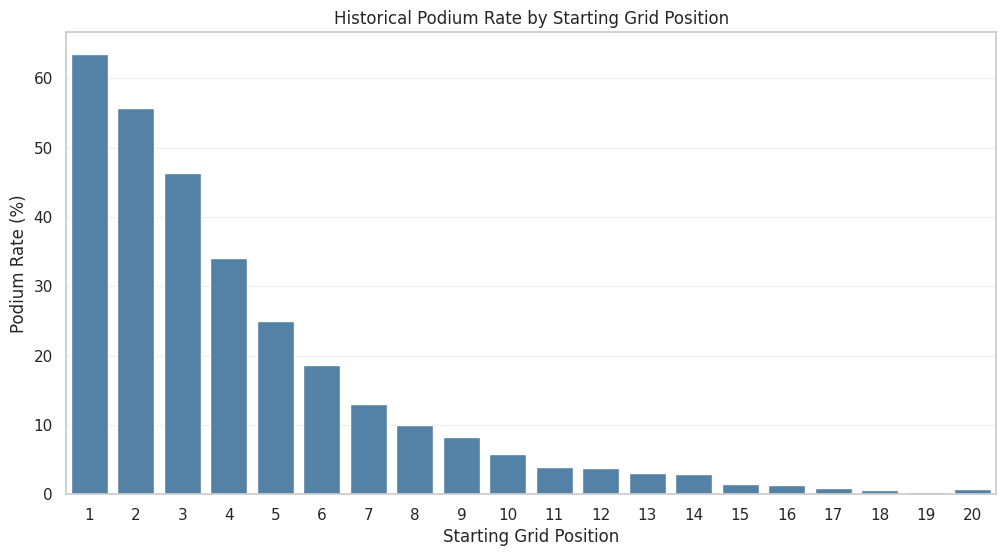

In [18]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=grid_podium[grid_podium["grid"] <= 20],
    x="grid",
    y="Podium_Rate",
    color="steelblue"
)

plt.title("Historical Podium Rate by Starting Grid Position")
plt.xlabel("Starting Grid Position")
plt.ylabel("Podium Rate (%)")
plt.grid(axis="y", alpha=0.3)

plt.show()

In [19]:
front_row = grid_eda[
    grid_eda["grid"].isin([1, 2])
]

other_positions = grid_eda[
    grid_eda["grid"] > 2
]

print(
    "Front-row podium rate:",
    round(front_row["podium"].mean() * 100, 2),
    "%"
)

print(
    "Other grid positions podium rate:",
    round(other_positions["podium"].mean() * 100, 2),
    "%"
)

Front-row podium rate: 59.58 %
Other grid positions podium rate: 8.97 %


### EDA Finding — Relationship Between Starting Grid Position and Podium Finishes

**Verification status:** Numerical statements were reconciled with the successful clean saved execution (Version 13, 16 October 2026). Audit results, statistical tables and plotted outputs provide the evidence; predictive associations do not establish causation.

The exploratory analysis demonstrates a strong association between starting grid position and podium finishes.

Drivers starting in position P1 achieved a historical podium rate of 63.47%, compared with 55.64% for P2, 46.28% for P3, and 5.84% for P10.

Drivers starting on the front row (P1–P2) achieved a combined podium rate of 59.58%, whereas drivers starting in positions P3 or lower achieved 8.97%.

This suggests that starting grid position is a potentially valuable predictive feature for podium classification.

The analysis used 25,121 records with positive grid positions, excluding 1,638 records with zero, missing, or otherwise non-positive grid values.

**Feature engineering decision:** Retain `grid` as a candidate predictive feature because it is available before the race starts and shows a strong historical relationship with the target.

**Limitation:** These observations are associations, not causal effects. The analysis uses raw historical records and may be influenced by constructor strength, driver performance, different racing eras, and historical duplicate records. The results will be reassessed after cleaning.


In [20]:
# Create unique driver-race combinations
race_entries = tables["results"][
    ["raceId", "driverId"]
].drop_duplicates()

# Add season information
race_entries = race_entries.merge(
    tables["races"][["raceId", "year"]],
    on="raceId",
    how="left",
    validate="many_to_one"
)

# Get unique qualifying records
qualifying_entries = tables["qualifying"][
    ["raceId", "driverId"]
].drop_duplicates()

qualifying_entries["has_qualifying"] = 1

# Connect results to qualifying records
coverage = race_entries.merge(
    qualifying_entries,
    on=["raceId", "driverId"],
    how="left",
    validate="one_to_one"
)

# Calculate qualifying coverage
qualifying_coverage = (
    coverage.groupby("year")["has_qualifying"]
    .apply(lambda x: x.notna().mean() * 100)
)

display(qualifying_coverage.head(20))

year
1950    0.0
1951    0.0
1952    0.0
1953    0.0
1954    0.0
1955    0.0
1956    0.0
1957    0.0
1958    0.0
1959    0.0
1960    0.0
1961    0.0
1962    0.0
1963    0.0
1964    0.0
1965    0.0
1966    0.0
1967    0.0
1968    0.0
1969    0.0
Name: has_qualifying, dtype: float64

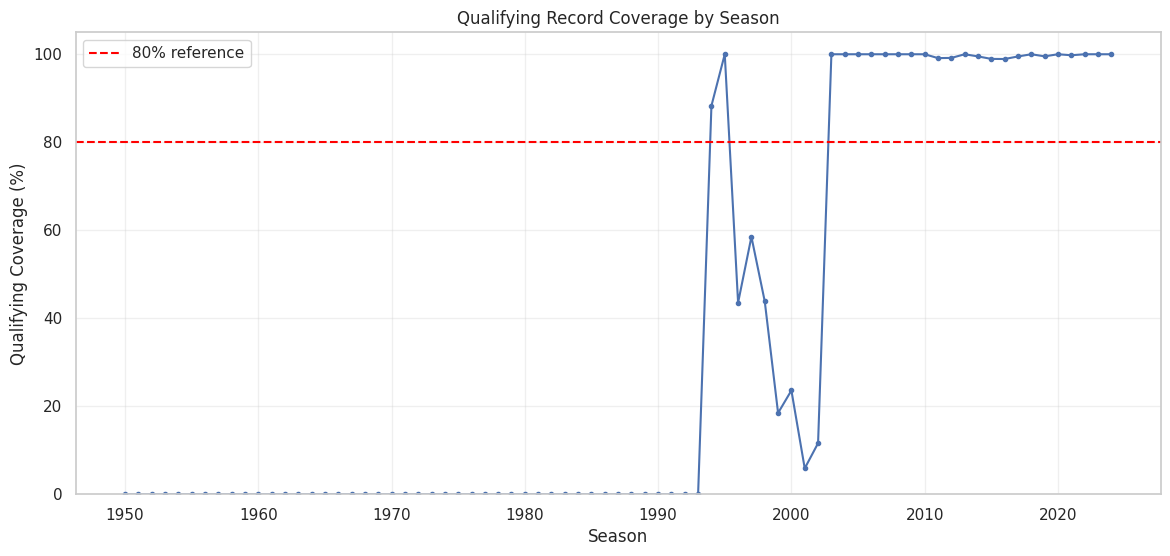

In [21]:
plt.figure(figsize=(14, 6))

plt.plot(
    qualifying_coverage.index,
    qualifying_coverage.values,
    marker="o",
    markersize=3
)

plt.axhline(
    y=80,
    color="red",
    linestyle="--",
    label="80% reference"
)

plt.title("Qualifying Record Coverage by Season")
plt.xlabel("Season")
plt.ylabel("Qualifying Coverage (%)")

plt.ylim(0, 105)
plt.grid(alpha=0.3)
plt.legend()

plt.show()

### EDA Finding — Historical Qualifying Coverage

**Verification status:** Numerical statements were reconciled with the successful clean saved execution (Version 13, 16 October 2026). Audit results, statistical tables and plotted outputs provide the evidence; predictive associations do not establish causation.

The qualifying coverage analysis reveals substantial variation in data availability across Formula 1 history.

Average annual qualifying-record coverage is 4.09% during 1950–1995, 50.54% during 1996–2005, 99.79% during 2006–2013, 99.52% during 2014–2021, and 100% during 2022–2024.

These findings indicate that qualifying-based features have significant historical missingness, particularly before 2006.

**Feature engineering hypothesis:** The period 2006–2024 is a promising candidate for model development because qualifying-record coverage is consistently high. The fixed primary training period is 2006–2019; no comparison against a broader training window is claimed.

**Preprocessing consideration:** Missing qualifying records and missing session times within existing qualifying records should be examined separately.

**Limitation:** These figures represent the unweighted average of annual driver–race qualifying-record coverage within each period. They do not measure the completeness of individual qualifying lap-time fields.


In [22]:
coverage_summary = pd.DataFrame({
    "Season": qualifying_coverage.index,
    "Coverage (%)": qualifying_coverage.values
})

coverage_summary["Period"] = pd.cut(
    coverage_summary["Season"],
    bins=[1949, 1995, 2005, 2013, 2021, 2024],
    labels=[
        "1950–1995",
        "1996–2005",
        "2006–2013",
        "2014–2021",
        "2022–2024"
    ]
)

period_coverage = (
    coverage_summary.groupby(
        "Period",
        observed=True
    )["Coverage (%)"].mean()
)

display(period_coverage)

Period
1950–1995      4.093224
1996–2005     50.542256
2006–2013     99.786184
2014–2021     99.520586
2022–2024    100.000000
Name: Coverage (%), dtype: float64

In [23]:
performance_eda = eda_results.merge(
    tables["drivers"][
        ["driverId", "forename", "surname"]
    ],
    on="driverId",
    how="left",
    validate="many_to_one"
)

performance_eda = performance_eda.merge(
    tables["constructors"][
        ["constructorId", "name"]
    ],
    on="constructorId",
    how="left",
    validate="many_to_one"
)

performance_eda["Driver"] = (
    performance_eda["forename"] + " " +
    performance_eda["surname"]
)

performance_eda.rename(
    columns={"name": "Constructor"},
    inplace=True
)

performance_eda.head()

,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId,podium,forename,surname,Constructor,Driver
0,1,18,1,1,22.0,1,1.0,1,1,10.0,58,1:34:50.616,5690616.0,39.0,2.0,1:27.452,218.300,1,1,Lewis,Hamilton,McLaren,Lewis Hamilton
1,2,18,2,2,3.0,5,2.0,2,2,8.0,58,+5.478,5696094.0,41.0,3.0,1:27.739,217.586,1,1,Nick,Heidfeld,BMW Sauber,Nick Heidfeld
2,3,18,3,3,7.0,7,3.0,3,3,6.0,58,+8.163,5698779.0,41.0,5.0,1:28.090,216.719,1,1,Nico,Rosberg,Williams,Nico Rosberg
3,4,18,4,4,5.0,11,4.0,4,4,5.0,58,+17.181,5707797.0,58.0,7.0,1:28.603,215.464,1,0,Fernando,Alonso,Renault,Fernando Alonso
4,5,18,5,1,23.0,3,5.0,5,5,4.0,58,+18.014,5708630.0,43.0,1.0,1:27.418,218.385,1,0,Heikki,Kovalainen,McLaren,Heikki Kovalainen


In [24]:
driver_performance = (
    performance_eda.groupby(
        ["driverId", "Driver"]
    )
    .agg(
        Race_Entries=("raceId", "nunique"),
        Podiums=("podium", "sum")
    )
    .reset_index()
)

driver_performance["Podium_Rate"] = (
    driver_performance["Podiums"] /
    driver_performance["Race_Entries"] * 100
)

# Restrict to drivers with enough race history
experienced_drivers = driver_performance[
    driver_performance["Race_Entries"] >= 30
]

top_drivers = experienced_drivers.nlargest(
    10,
    "Podium_Rate"
)

display(top_drivers)

,driverId,Driver,Race_Entries,Podiums,Podium_Rate
578,579,Juan Fangio,51,35,68.627451
641,642,Nino Farina,34,20,58.823529
0,1,Lewis Hamilton,356,202,56.741573
828,830,Max Verstappen,209,112,53.588517
646,647,Alberto Ascari,32,17,53.125000
116,117,Alain Prost,202,106,52.475248
29,30,Michael Schumacher,308,155,50.324675
101,102,Ayrton Senna,162,80,49.382716
372,373,Jim Clark,72,32,44.444444
327,328,Jackie Stewart,100,43,43.000000


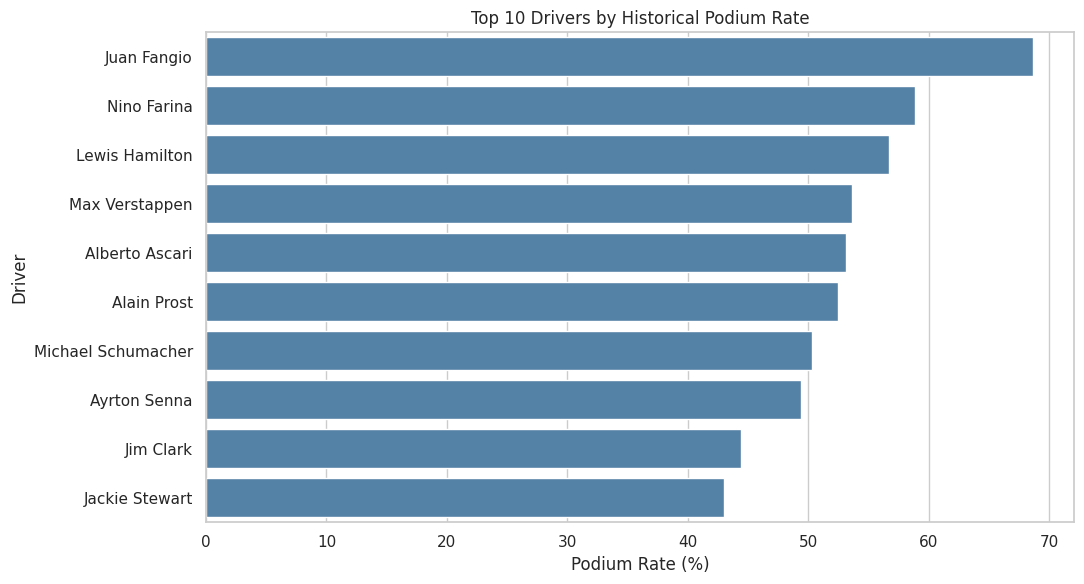

In [25]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=top_drivers,
    x="Podium_Rate",
    y="Driver",
    color="steelblue"
)

plt.title("Top 10 Drivers by Historical Podium Rate")
plt.xlabel("Podium Rate (%)")
plt.ylabel("Driver")

plt.tight_layout()
plt.show()

In [26]:
constructor_performance = (
    performance_eda.groupby(
        ["constructorId", "Constructor"]
    )
    .agg(
        Race_Entries=("driverId", "size"),
        Podiums=("podium", "sum")
    )
    .reset_index()
)

constructor_performance["Podium_Rate"] = (
    constructor_performance["Podiums"] /
    constructor_performance["Race_Entries"] * 100
)

experienced_constructors = constructor_performance[
    constructor_performance["Race_Entries"] >= 30
]

top_constructors = experienced_constructors.nlargest(
    10,
    "Podium_Rate"
)

display(top_constructors)

,constructorId,Constructor,Race_Entries,Podiums,Podium_Rate
128,131,Mercedes,652,298,45.705521
22,23,Brawn,34,15,44.117647
192,196,Matra-Ford,40,15,37.500000
8,9,Red Bull,788,282,35.786802
5,6,Ferrari,2439,841,34.481345
187,191,Brabham-Repco,77,25,32.467532
0,1,McLaren,1923,508,26.417057
115,118,Vanwall,71,14,19.718310
21,22,Benetton,520,102,19.615385
176,180,Lotus-Ford,128,25,19.531250


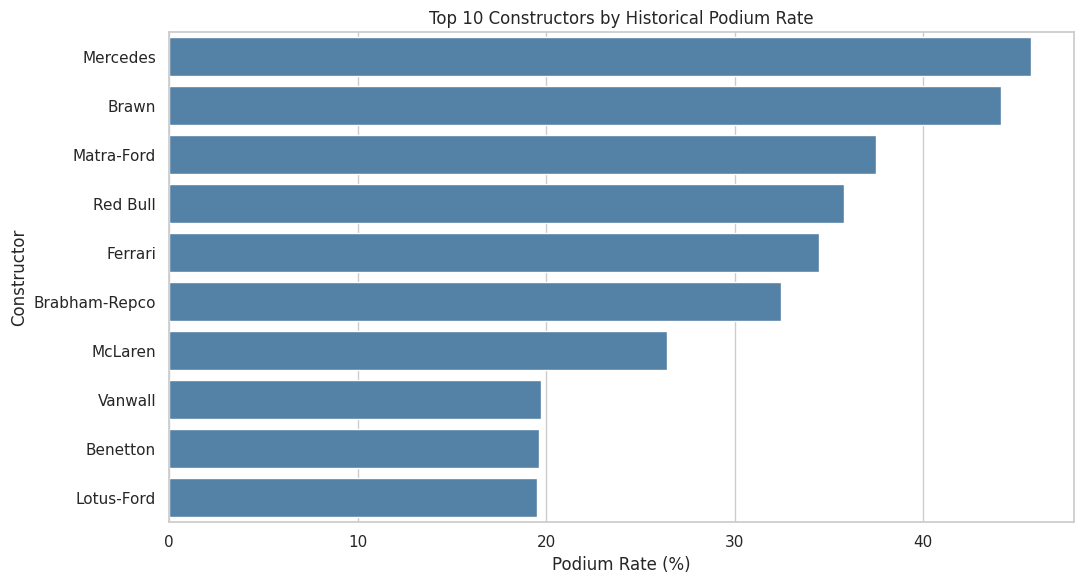

In [27]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=top_constructors,
    x="Podium_Rate",
    y="Constructor",
    color="steelblue"
)

plt.title("Top 10 Constructors by Historical Podium Rate")
plt.xlabel("Podium Rate (%)")
plt.ylabel("Constructor")

plt.tight_layout()
plt.show()

### EDA Finding — Historical Driver and Constructor Performance

**Verification status:** Numerical statements were reconciled with the successful clean saved execution (Version 13, 16 October 2026). Audit results, statistical tables and plotted outputs provide the evidence; predictive associations do not establish causation.

The analysis reveals substantial variation in podium rates across drivers and constructors.

Among drivers with at least 30 distinct race entries, Juan Fangio has the highest observed podium rate (68.63%), followed by Nino Farina (58.82%) and Lewis Hamilton (56.74%).

Among constructors with at least 30 driver-entry records, Mercedes has the highest observed podium rate (45.71%), followed by Brawn (44.12%) and Matra-Ford (37.50%).

These differences suggest that historical driver performance and constructor strength may provide useful predictive information beyond starting grid position.

**Feature engineering hypothesis:** Rolling driver and constructor performance features summarize only races completed before the prediction date; this motivates the past-only features implemented in Phase 5.

**Limitations:** The current calculations use raw historical results, which may contain shared-drive duplicates. Driver podium rates also use distinct races as the denominator and result rows as the numerator. Historical eras and team identities differ, so these descriptive results should not be interpreted as causal effects or direct measures of driver skill.


In [28]:
missing_report = []

for name, df in tables.items():
    for column in df.columns:
        missing_count = df[column].isna().sum()

        missing_report.append({
            "Table": name,
            "Column": column,
            "Missing_Count": missing_count,
            "Missing_Percent": round(
                missing_count / len(df) * 100, 2
            )
        })

missing_report = pd.DataFrame(missing_report)

missing_top20 = (
    missing_report
    .sort_values("Missing_Percent", ascending=False)
    .head(20)
)

display(missing_top20)

,Table,Column,Missing_Count,Missing_Percent
18,constructor_results,status,12608,99.87
59,races,sprint_time,1110,98.67
58,races,sprint_date,1107,98.40
55,races,fp3_time,1072,95.29
51,races,fp1_time,1057,93.96
57,races,quali_time,1057,93.96
53,races,fp2_time,1057,93.96
54,races,fp3_date,1053,93.60
28,drivers,number,802,93.15
56,races,quali_date,1035,92.00


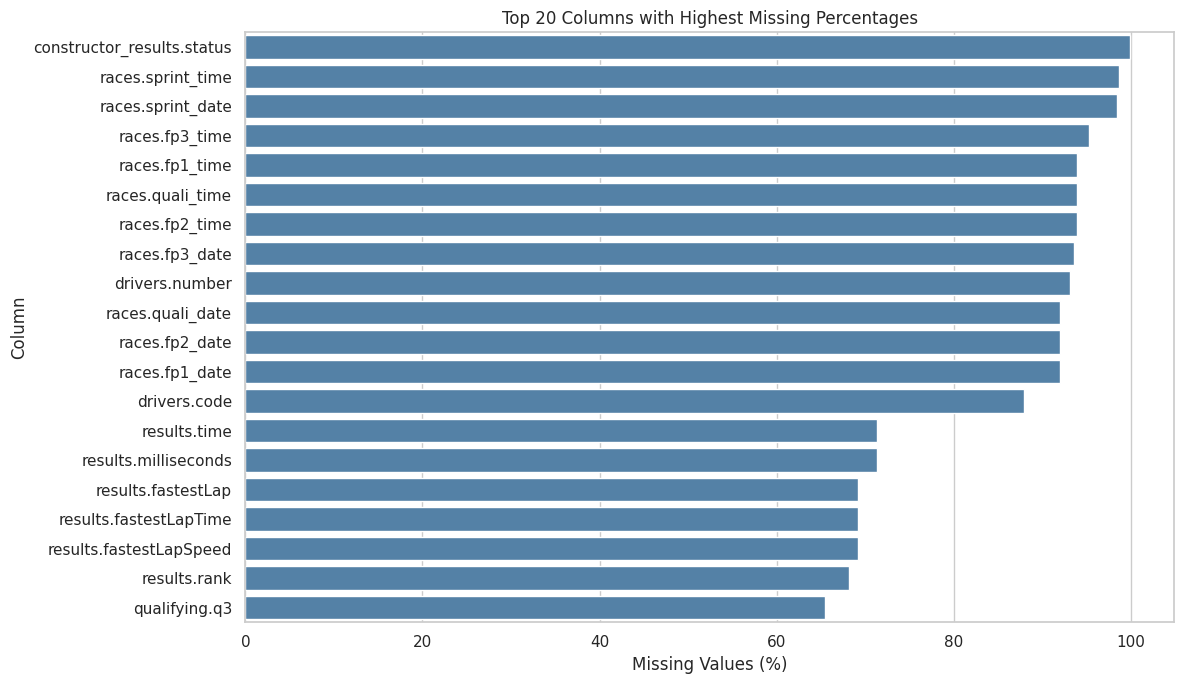

In [29]:
missing_top20 = missing_top20.copy()

missing_top20["Feature"] = (
    missing_top20["Table"] + "." +
    missing_top20["Column"]
)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=missing_top20,
    x="Missing_Percent",
    y="Feature",
    color="steelblue"
)

plt.title("Top 20 Columns with Highest Missing Percentages")
plt.xlabel("Missing Values (%)")
plt.ylabel("Column")

plt.tight_layout()
plt.show()

In [30]:
duplicate_rows = results[
    results.duplicated(
        ["raceId", "driverId"],
        keep=False
    )
].copy()

duplicate_rows = duplicate_rows.merge(
    races[["raceId", "year", "name"]],
    on="raceId",
    how="left",
    validate="many_to_one"
)

print("Duplicate rows:", len(duplicate_rows))

display(
    duplicate_rows[
        [
            "year",
            "name",
            "raceId",
            "driverId",
            "resultId",
            "grid",
            "positionOrder"
        ]
    ].head(20)
)

Duplicate rows: 176


,year,name,raceId,driverId,resultId,grid,positionOrder
0,1978,Italian Grand Prix,540,229,13189,0,26
1,1978,Italian Grand Prix,540,229,13192,0,29
2,1964,United States Grand Prix,717,373,17363,1,7
3,1962,British Grand Prix,733,465,17741,0,22
4,1962,British Grand Prix,733,465,17744,0,25
5,1961,British Grand Prix,742,475,17962,20,19
6,1961,British Grand Prix,742,475,17964,5,21
7,1961,United States Grand Prix,745,418,18063,11,17
8,1960,Argentine Grand Prix,746,475,18083,1,17
9,1958,Monaco Grand Prix,766,541,18510,0,17


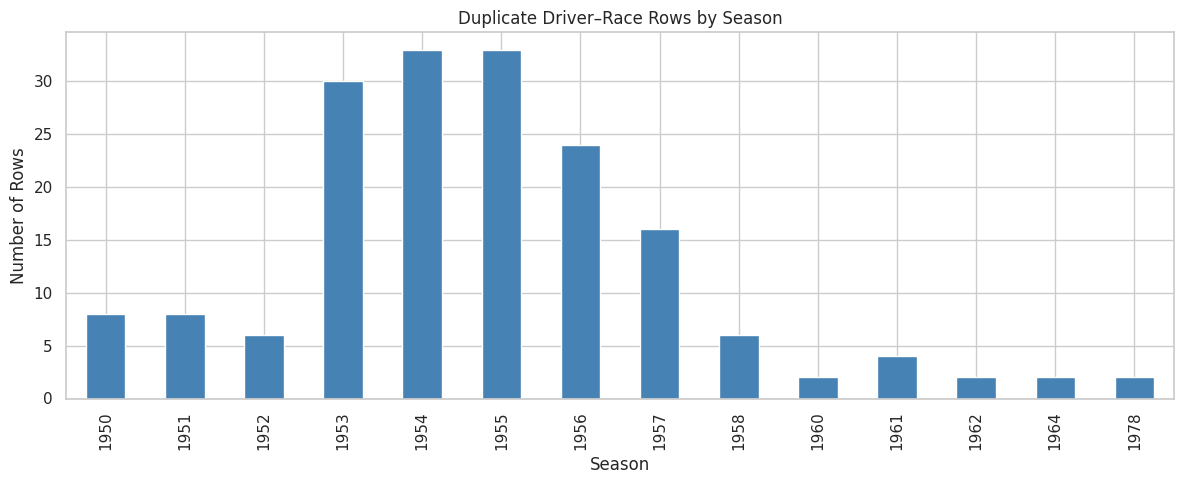

In [31]:
duplicates_by_year = (
    duplicate_rows.groupby("year")
    .size()
    .sort_index()
)

plt.figure(figsize=(12, 5))

duplicates_by_year.plot(
    kind="bar",
    color="steelblue"
)

plt.title("Duplicate Driver–Race Rows by Season")
plt.xlabel("Season")
plt.ylabel("Number of Rows")

plt.tight_layout()
plt.show()

In [32]:
era_eda = eda_results.merge(
    races[["raceId", "year"]],
    on="raceId",
    how="left",
    validate="many_to_one"
)

era_eda["Era"] = pd.cut(
    era_eda["year"],
    bins=[1949, 2005, 2021, 2024],
    labels=[
        "1950–2005",
        "2006–2021",
        "2022–2024"
    ]
)

,Era,Entries,Podiums,Podium_Rate
0,1950–2005,18845,2272,12.056248
1,2006–2021,6555,921,14.050343
2,2022–2024,1359,204,15.011038


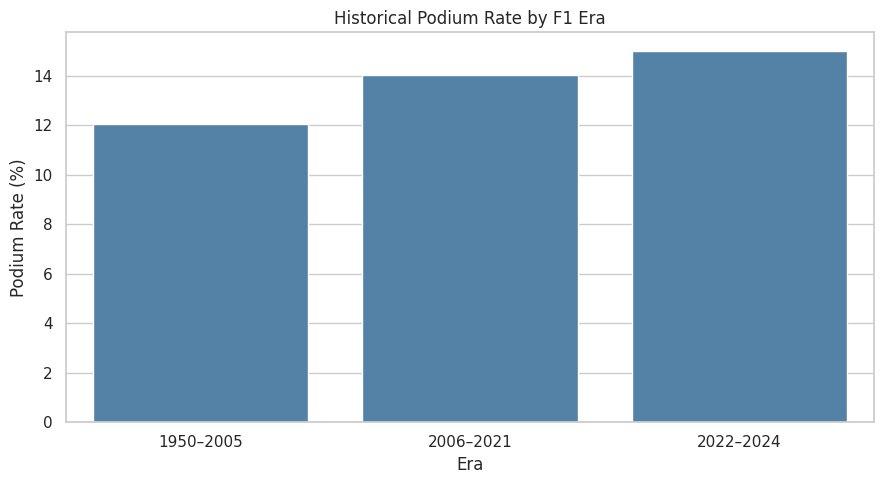

In [33]:
era_summary = (
    era_eda.groupby("Era", observed=True)
    .agg(
        Entries=("podium", "size"),
        Podiums=("podium", "sum"),
        Podium_Rate=("podium", "mean")
    )
    .reset_index()
)

era_summary["Podium_Rate"] *= 100

display(era_summary)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=era_summary,
    x="Era",
    y="Podium_Rate",
    color="steelblue"
)

plt.title("Historical Podium Rate by F1 Era")
plt.xlabel("Era")
plt.ylabel("Podium Rate (%)")

plt.tight_layout()
plt.show()

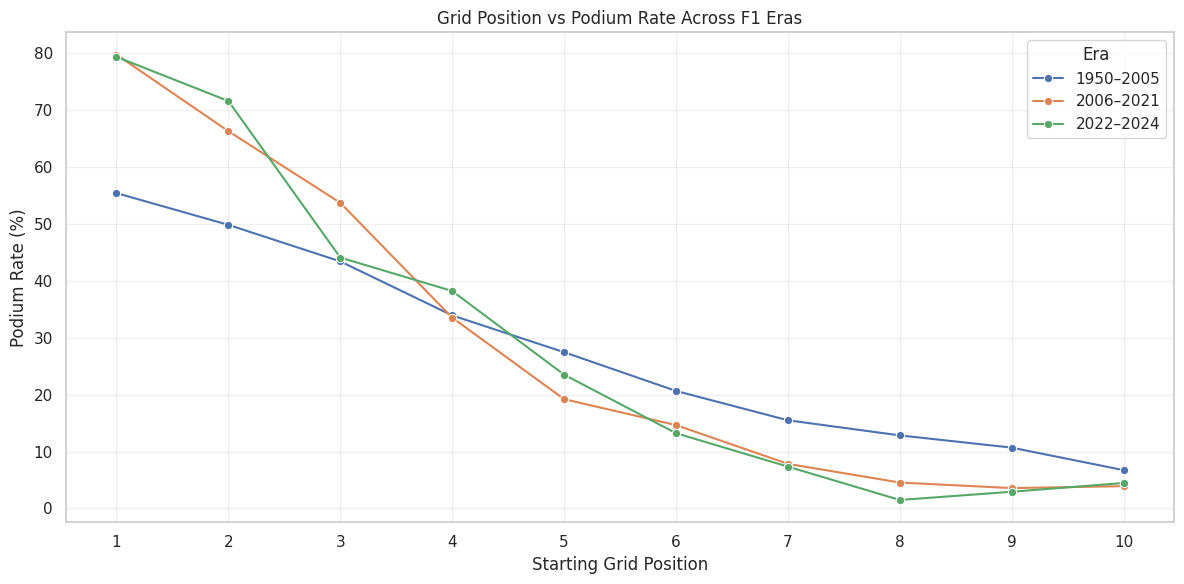

In [34]:
grid_era_eda = era_eda[
    era_eda["grid"].between(1, 10)
].copy()

grid_era_summary = (
    grid_era_eda.groupby(
        ["Era", "grid"],
        observed=True
    )["podium"]
    .mean()
    .mul(100)
    .reset_index(name="Podium_Rate")
)

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=grid_era_summary,
    x="grid",
    y="Podium_Rate",
    hue="Era",
    marker="o"
)

plt.title("Grid Position vs Podium Rate Across F1 Eras")
plt.xlabel("Starting Grid Position")
plt.ylabel("Podium Rate (%)")

plt.xticks(range(1, 11))
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### EDA Findings and Implications

**Verification status:** Numerical statements were reconciled with the successful clean saved execution (Version 13, 16 October 2026). Audit results, statistical tables and plotted outputs provide the evidence; predictive associations do not establish causation.

- **Outcome imbalance:** Only about 12.69% of raw result entries were podiums. Consequently, we prioritize **average precision / PR-AUC**, with ROC-AUC and threshold-dependent F1 as supporting measures.
- **Grid strength:** Grid P1 and P2 had historical podium rates of approximately **63.47% and 55.64%**, respectively. The pooled front-row rate was about **59.58%**, versus **8.97%** for other positive grid positions. We therefore include starting grid as a predictive feature.
- **Qualifying missingness:** Qualifying data are much less complete in early seasons (around 4.09% coverage in 1950–1995) and nearly complete in recent years. We add missingness indicators, impute using training-only statistics, and use 2006–2019 as the primary model-training period.
- **Duplicates and historical change:** Shared drives in early Formula 1 and differences in participation across eras mean that counts, denominators, and historical comparisons require explicit rules.

These observations support feature selection and experimental design; they do not establish causal claims.


## Phase 3 — Cleaning, Typing, and Validation

**Verification status:** Numerical statements were reconciled with the successful clean saved execution (Version 13, 16 October 2026). Audit results, statistical tables and plotted outputs provide the evidence; predictive associations do not establish causation.

Cleaning is performed on **deep copies** of the original tables (`clean_tables`), preserving the raw dataset for auditability. Race dates are parsed as datetimes; Q1/Q2/Q3 lap times are converted into numerical seconds; specified numerical fields are converted with safe coercion. Missing sentinels are handled at import.

The raw results contain **176 records in 85 duplicated driver–race groups** (91 excess rows). The deterministic resolution prefers positive grid positions, then the lowest `resultId`. This produces **26,668 cleaned result rows**, with exactly one record per `(raceId, driverId)`. Historical shared drives mean some detail is irretrievably simplified; we disclose this rather than claim a unique historical truth.

We compare podium distributions before and after deduplication (approximately 12.69% before versus 12.67% after), check primary and foreign keys, and verify cleaned-file exports. Data cleaning must not introduce information from races that have not yet occurred.


In [35]:
# Create independent copies of all raw tables
clean_tables = {
    name: df.copy(deep=True)
    for name, df in tables.items()
}

print("Original tables:", len(tables))
print("Working copies:", len(clean_tables))

Original tables: 14
Working copies: 14


In [36]:
races_clean = clean_tables["races"]

races_clean["date"] = pd.to_datetime(
    races_clean["date"],
    errors="coerce"
)

date_columns = [
    "fp1_date", "fp2_date", "fp3_date",
    "quali_date", "sprint_date"
]

for column in date_columns:
    if column in races_clean.columns:
        races_clean[column] = pd.to_datetime(
            races_clean[column],
            errors="coerce"
        )

print(races_clean["date"].dtype)
print("Missing main race dates:",
      races_clean["date"].isna().sum())

datetime64[ns]
Missing main race dates: 0


In [37]:
qualifying_clean = clean_tables["qualifying"]

def lap_time_to_seconds(value):
    if pd.isna(value):
        return np.nan

    try:
        minutes, seconds = str(value).split(":")
        return int(minutes) * 60 + float(seconds)
    except (ValueError, TypeError):
        return np.nan

for column in ["q1", "q2", "q3"]:
    qualifying_clean[column + "_seconds"] = (
        qualifying_clean[column]
        .apply(lap_time_to_seconds)
    )

display(
    qualifying_clean[
        ["q1", "q1_seconds",
         "q2", "q2_seconds",
         "q3", "q3_seconds"]
    ].head(10)
)

,q1,q1_seconds,q2,q2_seconds,q3,q3_seconds
0,1:26.572,86.572,1:25.187,85.187,1:26.714,86.714
1,1:26.103,86.103,1:25.315,85.315,1:26.869,86.869
2,1:25.664,85.664,1:25.452,85.452,1:27.079,87.079
3,1:25.994,85.994,1:25.691,85.691,1:27.178,87.178
4,1:25.960,85.960,1:25.518,85.518,1:27.236,87.236
5,1:26.427,86.427,1:26.101,86.101,1:28.527,88.527
6,1:26.295,86.295,1:26.059,86.059,1:28.687,88.687
7,1:26.381,86.381,1:26.063,86.063,1:29.041,89.041
8,1:26.919,86.919,1:26.164,86.164,1:29.593,89.593
9,1:26.702,86.702,1:25.842,85.842,NaN,NaN


In [38]:
numeric_columns = {
    "results": [
        "grid", "positionOrder",
        "points", "laps"
    ],
    "qualifying": ["position"],
    "driver_standings": [
        "points", "position", "wins"
    ],
    "constructor_standings": [
        "points", "position", "wins"
    ]
}

for table_name, columns in numeric_columns.items():
    df = clean_tables[table_name]

    for column in columns:
        df[column] = pd.to_numeric(
            df[column],
            errors="coerce"
        )

    print(f"{table_name}: numerical conversion completed")

results: numerical conversion completed
qualifying: numerical conversion completed
driver_standings: numerical conversion completed
constructor_standings: numerical conversion completed


In [39]:
results_clean = clean_tables["results"]

duplicate_mask = results_clean.duplicated(
    ["raceId", "driverId"],
    keep=False
)

duplicate_details = results_clean.loc[
    duplicate_mask,
    [
        "resultId", "raceId", "driverId",
        "constructorId", "grid",
        "positionOrder", "statusId"
    ]
].sort_values(
    ["raceId", "driverId", "resultId"]
)

print("Rows in duplicate groups:",
      len(duplicate_details))

print(
    "Number of affected driver-race groups:",
    duplicate_details[
        ["raceId", "driverId"]
    ].drop_duplicates().shape[0]
)

print(
    "Excess rows:",
    len(results_clean) -
    len(results_clean.drop_duplicates(
        ["raceId", "driverId"]
    ))
)

display(duplicate_details.head(30))

Rows in duplicate groups: 176
Number of affected driver-race groups: 85
Excess rows: 91


,resultId,raceId,driverId,constructorId,grid,positionOrder,statusId
13188,13189,540,229,54,0,26,81
13191,13192,540,229,57,0,29,97
17362,17363,717,373,172,1,7,60
24298,24304,717,373,172,1,12,98
17740,17741,733,465,172,0,22,54
17743,17744,733,465,97,0,25,54
17961,17962,742,475,102,20,19,2
17963,17964,742,475,172,5,21,23
18062,18063,745,418,172,11,17,6
24297,24303,745,418,172,15,11,18


In [40]:
duplicate_start_analysis = (
    duplicate_details.assign(
        positive_grid=lambda df: df["grid"] > 0
    )
    .groupby(["raceId", "driverId"])
    .agg(
        Rows=("resultId", "size"),
        Positive_Grid_Rows=("positive_grid", "sum"),
        Podium_Rows=(
            "positionOrder",
            lambda x: (x <= 3).sum()
        )
    )
    .reset_index()
)

display(
    duplicate_start_analysis[
        "Positive_Grid_Rows"
    ].value_counts().sort_index()
)

display(
    duplicate_start_analysis[
        duplicate_start_analysis[
            "Positive_Grid_Rows"
        ] != 1
    ].head(20)
)

Positive_Grid_Rows
0     3
2    76
3     6
Name: count, dtype: int64

,raceId,driverId,Rows,Positive_Grid_Rows,Podium_Rows
0,540,229,2,0,0
1,717,373,2,2,0
2,733,465,2,0,0
3,742,475,2,2,0
4,745,418,2,2,0
5,746,475,2,2,1
6,766,541,2,0,0
7,770,479,2,2,0
8,774,566,2,2,0
9,776,581,2,2,0


In [41]:
# Work on the clean results table
results_clean = clean_tables["results"].copy()

# Identify duplicate records before cleaning
duplicate_audit = results_clean[
    results_clean.duplicated(
        ["raceId", "driverId"],
        keep=False
    )
].copy()

# Prefer a positive grid position
results_clean["positive_grid"] = (
    results_clean["grid"] > 0
).astype(int)

# Sort to make the selection rule deterministic
results_clean = results_clean.sort_values(
    by=[
        "raceId",
        "driverId",
        "positive_grid",
        "resultId"
    ],
    ascending=[True, True, False, True]
)

# Keep one record per driver and race
results_clean = results_clean.drop_duplicates(
    subset=["raceId", "driverId"],
    keep="first"
)

# Remove temporary helper column
results_clean = results_clean.drop(
    columns=["positive_grid"]
)

# Update our cleaning dictionary
clean_tables["results"] = results_clean

print("Original rows:", len(tables["results"]))
print("Cleaned rows:", len(results_clean))
print(
    "Rows removed:",
    len(tables["results"]) - len(results_clean)
)

print(
    "Remaining duplicate driver-race rows:",
    results_clean.duplicated(
        ["raceId", "driverId"]
    ).sum()
)

Original rows: 26759
Cleaned rows: 26668
Rows removed: 91
Remaining duplicate driver-race rows: 0


In [42]:
# Version-aware validation derives the expected cleaned grain from this input snapshot.
# The former 26,668 count described one dataset version, not a schema invariant.
expected_driver_races = len(tables["results"][["raceId", "driverId"]].drop_duplicates())
assert not clean_tables["results"][["raceId", "driverId"]].isna().any().any()
assert not clean_tables["results"].duplicated(["raceId", "driverId"]).any()
assert len(clean_tables["results"]) == expected_driver_races
assert len(tables["results"]) - len(clean_tables["results"]) == tables["results"].duplicated(["raceId", "driverId"]).sum()

# Fingerprints identify the CSV snapshot without modifying any source file.
import hashlib
source_manifest = pd.DataFrame([
    {"Table": name, "Rows": len(tables[name]),
     "SHA256": hashlib.sha256(next(p for p in csv_files if p.name == name + ".csv").read_bytes()).hexdigest()}
    for name in required_tables
])
display(source_manifest)
print("Driver-race grain validated against this source snapshot:", expected_driver_races)


,Table,Rows,SHA256
0,circuits,77,8a2ac67a0946ac238ddeaa4a212a1f3969f0108527b021...
1,constructors,212,ae423f6f2d6cd74d5cd594eac0bdec7e1e9be2cda3097e...
2,constructor_results,12625,8f1ebc0ce822bc02326b9bf13616f22a81514a6d35e5b7...
3,constructor_standings,13391,9f07b1b9f235625165f62c6fcd6b1938cd7daa6f7e4a58...
4,drivers,861,6a894569cb031dd65fb5f113f57b235100966653eaedd9...
5,driver_standings,34863,58397ed38d29f71316ba272a2ffd5bd00b6174774d919c...
6,races,1125,4839d035abc603fa88fa08fa976a86d76cff35f3e94cb7...
7,results,26759,a2392658044286800a0a946138067d9823f39e59147eee...
8,qualifying,10494,49c4ff9ae0be93d5f850f56c553d5e264914c7ba0c4d58...
9,lap_times,589081,70a772924f67682701acf1a6f26e8225ffd1b9f50844b2...


Driver-race grain validated against this source snapshot: 26668


In [43]:
# Validate primary keys
for table_name, key in primary_keys.items():
    df = clean_tables[table_name]

    cols = [key] if isinstance(key, str) else list(key)
    assert df[cols].notna().all().all(), f"{table_name}: null primary key"
    assert not df.duplicated(cols).any(), f"{table_name}: duplicate primary key"

print("All listed primary keys passed.")

# Validate foreign key relationships
for child, fk, parent, pk in relationships:
    invalid = (
        ~clean_tables[child][fk].dropna()
        .isin(clean_tables[parent][pk])
    ).sum()

    assert invalid == 0, (
        f"{child}.{fk} has {invalid} invalid references"
    )

print("All seven tested foreign key relationships passed.")


All listed primary keys passed.
All seven tested foreign key relationships passed.


In [44]:
before = tables["results"]
after = clean_tables["results"]

comparison = pd.DataFrame({
    "Metric": [
        "Total Records",
        "Duplicate Driver-Race Records",
        "Podium Rate (%)"
    ],
    "Before Cleaning": [
        len(before),
        before.duplicated(
            ["raceId", "driverId"]
        ).sum(),
        (before["positionOrder"] <= 3).mean() * 100
    ],
    "After Cleaning": [
        len(after),
        after.duplicated(
            ["raceId", "driverId"]
        ).sum(),
        (after["positionOrder"] <= 3).mean() * 100
    ]
})

display(comparison.round(2))

,Metric,Before Cleaning,After Cleaning
0,Total Records,26759.00,26668.00
1,Duplicate Driver-Race Records,91.00,0.00
2,Podium Rate (%),12.69,12.67


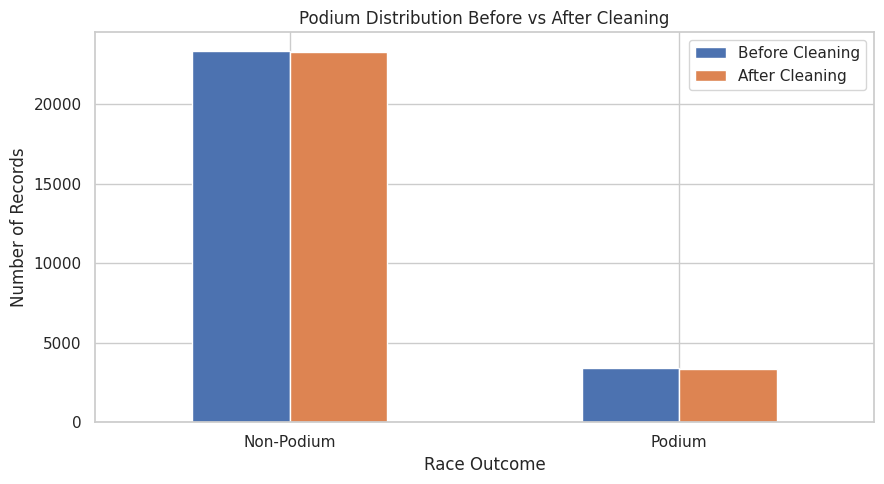

In [45]:
before_counts = (
    before["positionOrder"] <= 3
).value_counts().reindex([False, True], fill_value=0)

after_counts = (
    after["positionOrder"] <= 3
).value_counts().reindex([False, True], fill_value=0)

target_comparison = pd.DataFrame({
    "Before Cleaning": before_counts,
    "After Cleaning": after_counts
})

target_comparison.index = [
    "Non-Podium", "Podium"
]

target_comparison.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Podium Distribution Before vs After Cleaning")
plt.xlabel("Race Outcome")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

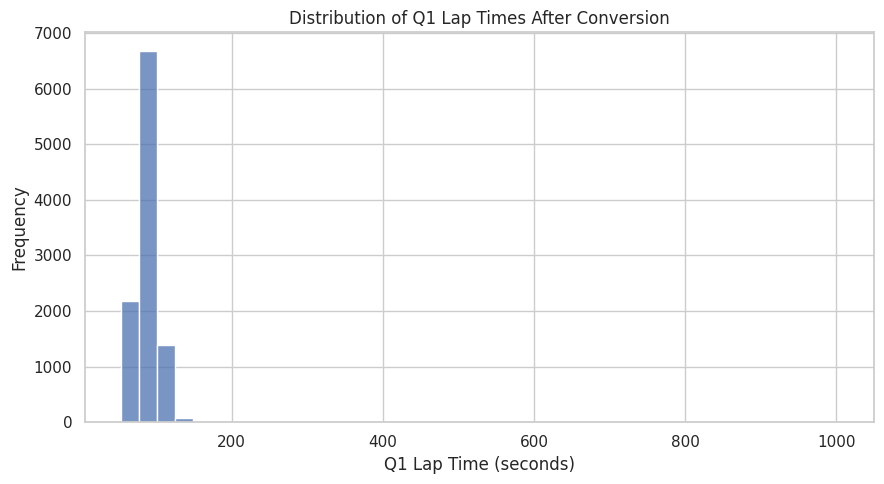

In [46]:
plt.figure(figsize=(9, 5))

sns.histplot(
    clean_tables["qualifying"]["q1_seconds"].dropna(),
    bins=40
)

plt.title("Distribution of Q1 Lap Times After Conversion")
plt.xlabel("Q1 Lap Time (seconds)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

In [47]:
from pathlib import Path

output_dir = Path("/kaggle/working/cleaned_data")
output_dir.mkdir(parents=True, exist_ok=True)

# Execute only after all cleaning checks pass
for name, df in clean_tables.items():
    df.to_csv(
        output_dir / f"{name}_clean.csv",
        index=False
    )

print("Cleaned tables saved.")

Cleaned tables saved.


In [48]:
import pandas as pd
import numpy as np

# Child table, foreign-key column, parent table, primary-key column
foreign_key_relationships = [
    ("races", "circuitId", "circuits", "circuitId"),
    ("results", "raceId", "races", "raceId"),
    ("results", "driverId", "drivers", "driverId"),
    ("results", "constructorId", "constructors", "constructorId"),
    ("results", "statusId", "status", "statusId"),

    ("qualifying", "raceId", "races", "raceId"),
    ("qualifying", "driverId", "drivers", "driverId"),
    ("qualifying", "constructorId", "constructors", "constructorId"),

    ("driver_standings", "raceId", "races", "raceId"),
    ("driver_standings", "driverId", "drivers", "driverId"),

    ("constructor_standings", "raceId", "races", "raceId"),
    ("constructor_standings", "constructorId", "constructors", "constructorId"),

    ("constructor_results", "raceId", "races", "raceId"),
    ("constructor_results", "constructorId", "constructors", "constructorId"),

    ("lap_times", "raceId", "races", "raceId"),
    ("lap_times", "driverId", "drivers", "driverId"),

    ("pit_stops", "raceId", "races", "raceId"),
    ("pit_stops", "driverId", "drivers", "driverId"),

    ("sprint_results", "raceId", "races", "raceId"),
    ("sprint_results", "driverId", "drivers", "driverId"),
    ("sprint_results", "constructorId", "constructors", "constructorId"),
    ("sprint_results", "statusId", "status", "statusId"),

    ("races", "year", "seasons", "year")
]

# Every relationship below is an identifying reference and is required.
# Nullable measurements (Q2/Q3, fastest-lap data, race session dates) are not FKs.
# There are no legitimate nullable FKs among these 23 declared relationships.
# Any future schema exception must be explicitly named and justified here.
nullable_foreign_keys = set()
fk_reports = []

for child, fk, parent, pk in foreign_key_relationships:
    child_df = clean_tables[child]
    parent_df = clean_tables[parent]

    values = child_df[fk]
    parent_values = parent_df[pk].dropna()

    missing = values.isna()
    invalid = values.notna() & ~values.isin(parent_values)

    fk_reports.append({
        "Child Table": child,
        "Foreign Key": fk,
        "Parent Table": parent,
        "Total Rows": len(child_df),
        "Missing FK": int(missing.sum()),
        "Invalid FK": int(invalid.sum()),
        "Nullable": (child, fk) in nullable_foreign_keys,
        "Status": "PASS" if not invalid.any() and ((child, fk) in nullable_foreign_keys or not missing.any()) else "FAIL"
    })

fk_report = pd.DataFrame(fk_reports)

display(fk_report)

print("Relationships checked:", len(fk_report))
print("Passed:", (fk_report["Status"] == "PASS").sum())
print("Failed:", (fk_report["Status"] == "FAIL").sum())


,Child Table,Foreign Key,Parent Table,Total Rows,Missing FK,Invalid FK,Nullable,Status
0,races,circuitId,circuits,1125,0,0,False,PASS
1,results,raceId,races,26668,0,0,False,PASS
2,results,driverId,drivers,26668,0,0,False,PASS
3,results,constructorId,constructors,26668,0,0,False,PASS
4,results,statusId,status,26668,0,0,False,PASS
5,qualifying,raceId,races,10494,0,0,False,PASS
6,qualifying,driverId,drivers,10494,0,0,False,PASS
7,qualifying,constructorId,constructors,10494,0,0,False,PASS
8,driver_standings,raceId,races,34863,0,0,False,PASS
9,driver_standings,driverId,drivers,34863,0,0,False,PASS


Relationships checked: 23
Passed: 23
Failed: 0


In [49]:
for child, fk, parent, pk in foreign_key_relationships:
    values = clean_tables[child][fk]
    valid_ids = clean_tables[parent][pk].dropna()

    invalid = values.notna() & ~values.isin(valid_ids)

    if invalid.any():
        print(f"\n{child}.{fk} -> {parent}.{pk}")
        print("Invalid rows:", invalid.sum())
        display(clean_tables[child].loc[invalid].head(10))

# Diagnostics above remain available; every required relationship must now pass.
assert fk_report["Status"].eq("PASS").all(), (
    "Foreign-key validation failed:\n" + fk_report.loc[fk_report["Status"].ne("PASS")].to_string(index=False)
)
print("All", len(fk_report), "declared foreign-key relationships passed.")


All 23 declared foreign-key relationships passed.


In [50]:

q = clean_tables["qualifying"].copy()

# Check the largest converted Q1 values
q1_extremes = (
    q[q["q1_seconds"].notna()]
    .sort_values("q1_seconds", ascending=False)
    .head(20)
)

# Add race and circuit context
race_info = clean_tables["races"][
    ["raceId", "year", "name", "circuitId"]
].rename(columns={"name": "raceName"})

circuit_info = clean_tables["circuits"][
    ["circuitId", "name"]
].rename(columns={"name": "circuitName"})

q1_extremes = (
    q1_extremes
    .merge(race_info, on="raceId", how="left")
    .merge(circuit_info, on="circuitId", how="left")
)

display(q1_extremes[
    [
        "year", "raceName", "circuitName",
        "driverId", "position", "q1", "q1_seconds"
    ]
])

print("Q1 summary statistics:")
display(q["q1_seconds"].describe(
    percentiles=[0.50, 0.90, 0.95, 0.99, 0.999]
))


,year,raceName,circuitName,driverId,position,q1,q1_seconds
0,1995,Japanese Grand Prix,Suzuka Circuit,87,24,16:42.640,1002.640
1,1994,Belgian Grand Prix,Circuit de Spa-Francorchamps,113,26,2:33.885,153.885
2,1994,Belgian Grand Prix,Circuit de Spa-Francorchamps,111,25,2:31.755,151.755
3,1994,Belgian Grand Prix,Circuit de Spa-Francorchamps,104,24,2:30.931,150.931
4,1994,Belgian Grand Prix,Circuit de Spa-Francorchamps,79,23,2:28.979,148.979
5,1994,Belgian Grand Prix,Circuit de Spa-Francorchamps,100,22,2:28.156,148.156
6,1994,Belgian Grand Prix,Circuit de Spa-Francorchamps,101,21,2:27.212,147.212
7,1994,Belgian Grand Prix,Circuit de Spa-Francorchamps,65,20,2:27.155,147.155
8,1994,Belgian Grand Prix,Circuit de Spa-Francorchamps,112,19,2:26.901,146.901
9,1994,Belgian Grand Prix,Circuit de Spa-Francorchamps,105,18,2:26.738,146.738


Q1 summary statistics:


count    10338.000000
mean        88.531251
std         15.392958
min         53.904000
50%         87.141000
90%        104.728300
95%        109.463900
99%        123.961160
99.9%      146.067205
max       1002.640000
Name: q1_seconds, dtype: float64

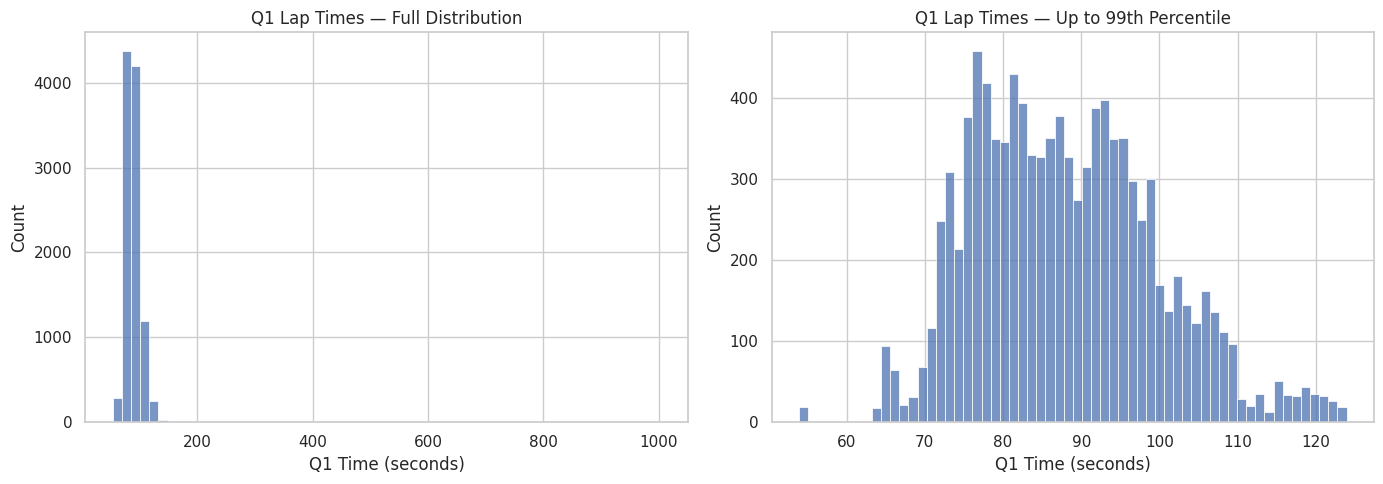

99th percentile: 123.96
Observations above 99th percentile: 104


In [51]:

import matplotlib.pyplot as plt
import seaborn as sns

q1 = q["q1_seconds"].dropna()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(q1, bins=60, ax=axes[0])
axes[0].set_title("Q1 Lap Times — Full Distribution")
axes[0].set_xlabel("Q1 Time (seconds)")

upper_limit = q1.quantile(0.99)

sns.histplot(
    q1[q1 <= upper_limit],
    bins=60,
    ax=axes[1]
)
axes[1].set_title("Q1 Lap Times — Up to 99th Percentile")
axes[1].set_xlabel("Q1 Time (seconds)")

plt.tight_layout()
plt.show()

print("99th percentile:", round(upper_limit, 2))
print("Observations above 99th percentile:",
      (q1 > upper_limit).sum())


In [52]:
from pathlib import Path

output_dir = Path("/kaggle/working/cleaned_data")

export_report = []

for name, original_df in clean_tables.items():
    file_path = output_dir / f"{name}_clean.csv"

    if not file_path.exists():
        export_report.append({
            "Table": name,
            "Status": "MISSING FILE"
        })
        continue

    exported_df = pd.read_csv(file_path)

    row_match = len(exported_df) == len(original_df)
    column_match = (
        exported_df.columns.tolist()
        == original_df.columns.tolist()
    )

    export_report.append({
        "Table": name,
        "Memory Rows": len(original_df),
        "Exported Rows": len(exported_df),
        "Rows Match": row_match,
        "Columns Match": column_match,
        "Status": (
            "PASS" if row_match and column_match
            else "FAIL"
        )
    })

export_report = pd.DataFrame(export_report)
display(export_report)

assert (export_report["Status"] == "PASS").all(), (
    "Some exported files failed validation."
)

# Verify the most important modeling-table constraint
exported_results = pd.read_csv(
    output_dir / "results_clean.csv"
)

assert len(exported_results) == expected_driver_races
assert not exported_results.duplicated(
    ["raceId", "driverId"]
).any()

print("Basic export validation passed.")


,Table,Memory Rows,Exported Rows,Rows Match,Columns Match,Status
0,circuits,77,77,True,True,PASS
1,constructors,212,212,True,True,PASS
2,constructor_results,12625,12625,True,True,PASS
3,constructor_standings,13391,13391,True,True,PASS
4,drivers,861,861,True,True,PASS
5,driver_standings,34863,34863,True,True,PASS
6,races,1125,1125,True,True,PASS
7,results,26668,26668,True,True,PASS
8,qualifying,10494,10494,True,True,PASS
9,lap_times,589081,589081,True,True,PASS


Basic export validation passed.


In [53]:

# Find the suspicious qualifying record
suspicious = clean_tables["qualifying"].loc[
    clean_tables["qualifying"]["q1_seconds"] > 300
].copy()

display(suspicious[
    ["raceId", "driverId", "position", "q1", "q1_seconds"]
])

# Compare against qualifying times from the same race
for race_id in suspicious["raceId"].unique():
    same_race = clean_tables["qualifying"].loc[
        clean_tables["qualifying"]["raceId"] == race_id,
        ["driverId", "position", "q1", "q1_seconds"]
    ].sort_values("position")

    print(f"\nRace ID: {race_id}")
    print("Qualifying times for the same race:")
    display(same_race)

    print("Median Q1 time:",
          same_race["q1_seconds"].median())


,raceId,driverId,position,q1,q1_seconds
2567,255,87,24,16:42.640,1002.64



Race ID: 255
Qualifying times for the same race:


,driverId,position,q1,q1_seconds
2544,30,1,1:38.023,98.023
2545,55,2,1:38.888,98.888
2546,57,3,1:38.954,98.954
2547,71,4,1:39.032,99.032
2548,77,5,1:39.040,99.040
2549,14,6,1:39.155,99.155
2550,56,7,1:39.621,99.621
2551,49,8,1:40.010,100.010
2552,65,9,1:40.349,100.349
2553,22,10,1:40.381,100.381


Median Q1 time: 101.4735


In [54]:

# Preserve the audited cleaned qualifying table
qualifying_model = clean_tables["qualifying"].copy()

# Flag the verified extreme observation
qualifying_model["q1_anomaly_flag"] = (
    (qualifying_model["raceId"] == 255) &
    (qualifying_model["driverId"] == 87) &
    (qualifying_model["q1_seconds"] > 300)
)

print("Flagged observations:",
      qualifying_model["q1_anomaly_flag"].sum())

# Retain original value for auditing
qualifying_model["q1_seconds_original"] = (
    qualifying_model["q1_seconds"]
)

# Set only this modeling value to missing
qualifying_model.loc[
    qualifying_model["q1_anomaly_flag"],
    "q1_seconds"
] = np.nan

# Verify no records were removed
assert len(qualifying_model) == len(clean_tables["qualifying"])
assert qualifying_model["q1_anomaly_flag"].sum() == 1

print("Original maximum:",
      clean_tables["qualifying"]["q1_seconds"].max())

print("Modeling maximum:",
      qualifying_model["q1_seconds"].max())

print("Original cleaned tables unchanged.")


Flagged observations: 1
Original maximum: 1002.64
Modeling maximum: 153.885
Original cleaned tables unchanged.


### Phase 3 — Final Cleaning Conclusions

**Verification status:** Numerical statements were reconciled with the successful clean saved execution (Version 13, 16 October 2026). Audit results, statistical tables and plotted outputs provide the evidence; predictive associations do not establish causation.

The corrected audit checks unique, non-null primary keys in all **14 tables**, including lap and pit-stop composite keys. It validates **23 required foreign-key relationships**, with `races.year → seasons.year`, and asserts on required nulls or orphan references. No nullable identifier reference is assumed: missing session dates, lap times and finishing positions are legitimate nullable measurements, not declared foreign keys. Driver–race uniqueness and export checks remain in place; all checks passed in the clean saved execution. The expected cleaned result count is derived from unique raw `(raceId, driverId)` pairs, and CSV SHA-256 fingerprints identify the dataset snapshot. Raw source CSVs remain immutable.

One conspicuous qualifying record was investigated at the **1995 Japanese Grand Prix**: `16:42.640`, correctly parsed as **1,002.640 seconds**, compared with a same-race median of about **101.474 seconds**. The record is an extreme outlier, but its cause could not be independently verified. We retain the original value in the audited data, flag it, and set its *modeling-copy* numerical Q1 value to missing; we do not invent a replacement lap time. Training-only imputation handles missingness later.

**Limitation:** passing structural checks proves neither all historical records are correct nor that every source record represents a confirmed race start.


## Phase 4 — Data-Engineering Question 1: Front-Row Podium Conversion

**Question:** Which circuits convert a front-row start into a podium most often, and did their ranking change after 2014?

We join **results → races → circuits** at the driver–race grain. A *front-row starter* is a driver with `grid` equal to 1 or 2; a *podium finish* has `positionOrder` from 1 to 3. Circuit conversion rate is `podium finishes from grid P1/P2 ÷ grid P1/P2 entries × 100`.

The overall ranking includes circuits with at least **10 front-row records**. Era comparisons require at least 10 such records **in each** period (before 2014 and 2014–2024), preventing extremely small samples from dominating. `qualifying.position` is analyzed separately from `results.grid`, since grid penalties, race-weekend procedures, and source conventions may make them differ. Outcome columns are used here for **retrospective analysis only**.

In [55]:

# Step 2: Join results, races, and circuits

front_row_df = (
    clean_tables["results"][
        ["raceId", "driverId", "grid", "positionOrder"]
    ]
    .merge(
        clean_tables["races"][
            ["raceId", "year", "circuitId", "name"]
        ].rename(columns={"name": "raceName"}),
        on="raceId",
        how="left",
        validate="many_to_one"
    )
    .merge(
        clean_tables["circuits"][
            ["circuitId", "name"]
        ].rename(columns={"name": "circuitName"}),
        on="circuitId",
        how="left",
        validate="many_to_one"
    )
)

# Ensure numeric values
front_row_df["grid"] = pd.to_numeric(
    front_row_df["grid"], errors="coerce"
)

front_row_df["positionOrder"] = pd.to_numeric(
    front_row_df["positionOrder"], errors="coerce"
)

# Create podium target for analysis only
front_row_df["podium"] = (
    front_row_df["positionOrder"].between(1, 3)
).astype(int)

# Select actual front-row starters
front_row_df = front_row_df[
    front_row_df["grid"].isin([1, 2])
].copy()

# Create historical era groups
front_row_df["era"] = np.where(
    front_row_df["year"] < 2014,
    "Before 2014",
    "2014–2024"
)

print("Front-row driver-race observations:", len(front_row_df))
print("Circuits represented:", front_row_df["circuitId"].nunique())

display(front_row_df.head())


Front-row driver-race observations: 2250
Circuits represented: 77


,raceId,driverId,grid,positionOrder,year,circuitId,raceName,circuitName,podium,era
15,1,18,1,1,2009,1,Australian Grand Prix,Albert Park Grand Prix Circuit,1,Before 2014
18,1,22,2,2,2009,1,Australian Grand Prix,Albert Park Grand Prix Circuit,1,Before 2014
32,2,15,2,4,2009,2,Malaysian Grand Prix,Sepang International Circuit,0,Before 2014
35,2,18,1,1,2009,2,Malaysian Grand Prix,Sepang International Circuit,1,Before 2014
43,3,4,2,9,2009,17,Chinese Grand Prix,Shanghai International Circuit,0,Before 2014


In [56]:

circuit_conversion = (
    front_row_df
    .groupby(["circuitId", "circuitName"])
    .agg(
        front_row_starts=("podium", "size"),
        podiums=("podium", "sum")
    )
    .reset_index()
)

circuit_conversion["conversion_rate"] = (
    circuit_conversion["podiums"]
    / circuit_conversion["front_row_starts"]
    * 100
)

# Require at least 10 front-row observations
# for the main ranking
circuit_ranking = (
    circuit_conversion[
        circuit_conversion["front_row_starts"] >= 10
    ]
    .sort_values(
        ["conversion_rate", "front_row_starts"],
        ascending=[False, False]
    )
)

display(circuit_ranking.head(15))


,circuitId,circuitName,front_row_starts,podiums,conversion_rate
67,69,Circuit of the Americas,24,20,83.333333
69,71,Sochi Autodrom,16,13,81.250000
7,8,Circuit de Nevers Magny-Cours,36,29,80.555556
22,24,Yas Marina Circuit,32,25,78.125000
21,22,Suzuka Circuit,68,51,75.000000
39,41,Dijon-Prenois,12,9,75.000000
1,2,Sepang International Circuit,37,27,72.972973
4,5,Istanbul Park,18,13,72.222222
3,4,Circuit de Barcelona-Catalunya,68,48,70.588235
16,17,Shanghai International Circuit,34,24,70.588235


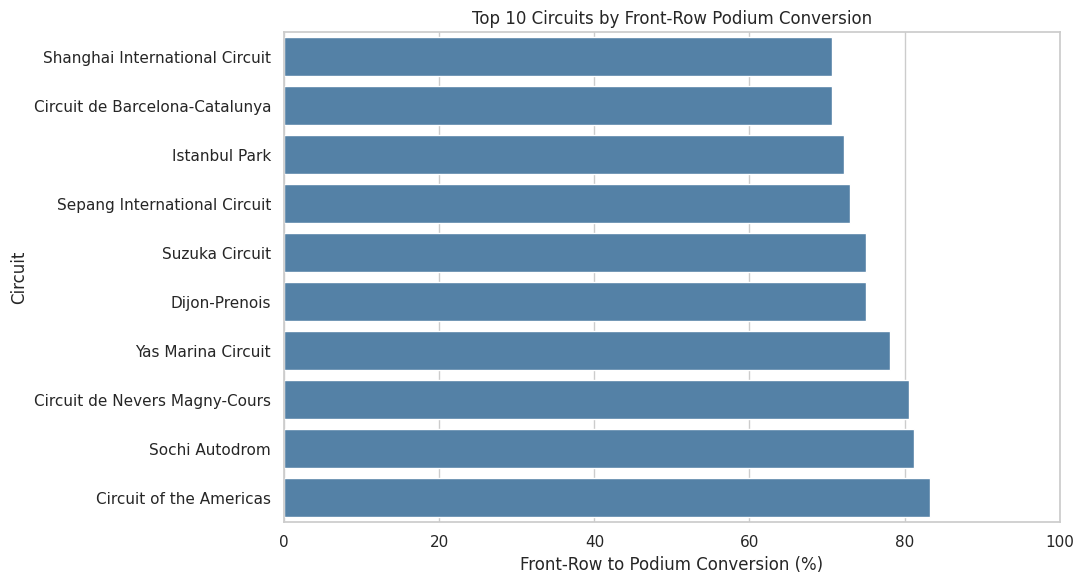

In [57]:

top_circuits = circuit_ranking.head(10).sort_values(
    "conversion_rate"
)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=top_circuits,
    x="conversion_rate",
    y="circuitName",
    color="steelblue"
)

plt.xlabel("Front-Row to Podium Conversion (%)")
plt.ylabel("Circuit")
plt.title("Top 10 Circuits by Front-Row Podium Conversion")
plt.xlim(0, 100)
plt.tight_layout()
plt.show()


In [58]:

# Calculate podium conversion separately for each era
era_conversion = (
    front_row_df
    .groupby(["circuitId", "circuitName", "era"])
    .agg(
        starts=("podium", "size"),
        podiums=("podium", "sum")
    )
    .reset_index()
)

era_conversion["conversion_rate"] = (
    era_conversion["podiums"]
    / era_conversion["starts"] * 100
)

# Keep circuits with at least 10 starts in BOTH eras
eligible_circuits = (
    era_conversion[era_conversion["starts"] >= 10]
    .groupby("circuitId")["era"]
    .nunique()
)

eligible_ids = eligible_circuits[
    eligible_circuits == 2
].index

era_comparison = era_conversion[
    era_conversion["circuitId"].isin(eligible_ids)
].copy()

print("Eligible circuits:", len(eligible_ids))

display(
    era_comparison.sort_values(
        ["circuitName", "era"]
    )
)


Eligible circuits: 16


,circuitId,circuitName,era,starts,podiums,conversion_rate
0,1,Albert Park Grand Prix Circuit,2014–2024,18,13,72.222222
1,1,Albert Park Grand Prix Circuit,Before 2014,36,20,55.555556
24,14,Autodromo Nazionale di Monza,2014–2024,22,16,72.727273
25,14,Autodromo Nazionale di Monza,Before 2014,128,60,46.875000
49,32,Autódromo Hermanos Rodríguez,2014–2024,18,11,61.111111
50,32,Autódromo Hermanos Rodríguez,Before 2014,30,18,60.000000
31,18,Autódromo José Carlos Pace,2014–2024,19,15,78.947368
32,18,Autódromo José Carlos Pace,Before 2014,62,37,59.677419
4,3,Bahrain International Circuit,2014–2024,24,16,66.666667
5,3,Bahrain International Circuit,Before 2014,18,12,66.666667


In [59]:

era_wide = era_comparison.pivot(
    index=["circuitId", "circuitName"],
    columns="era",
    values="conversion_rate"
).reset_index()

era_wide["Change (pp)"] = (
    era_wide["2014–2024"]
    - era_wide["Before 2014"]
)

era_wide["Rank Before"] = (
    era_wide["Before 2014"]
    .rank(ascending=False, method="min")
    .astype(int)
)

era_wide["Rank After"] = (
    era_wide["2014–2024"]
    .rank(ascending=False, method="min")
    .astype(int)
)

era_wide["Rank Improvement"] = (
    era_wide["Rank Before"]
    - era_wide["Rank After"]
)

display(
    era_wide.sort_values(
        "Rank After"
    ).round(2)
)


era,circuitId,circuitName,2014–2024,Before 2014,Change (pp),Rank Before,Rank After,Rank Improvement
12,22,Suzuka Circuit,88.89,70.00,18.89,1,1,0
13,24,Yas Marina Circuit,86.36,60.00,26.36,6,2,4
3,6,Circuit de Monaco,85.00,49.17,35.83,15,3,12
2,4,Circuit de Barcelona-Catalunya,81.82,65.22,16.60,4,4,0
7,13,Circuit de Spa-Francorchamps,81.82,53.85,27.97,12,4,8
11,18,Autódromo José Carlos Pace,78.95,59.68,19.27,8,6,2
10,17,Shanghai International Circuit,78.57,65.00,13.57,5,7,-2
4,7,Circuit Gilles Villeneuve,77.78,52.94,24.84,13,8,5
5,9,Silverstone Circuit,75.00,56.38,18.62,10,9,1
15,70,Red Bull Ring,73.08,52.00,21.08,14,10,4


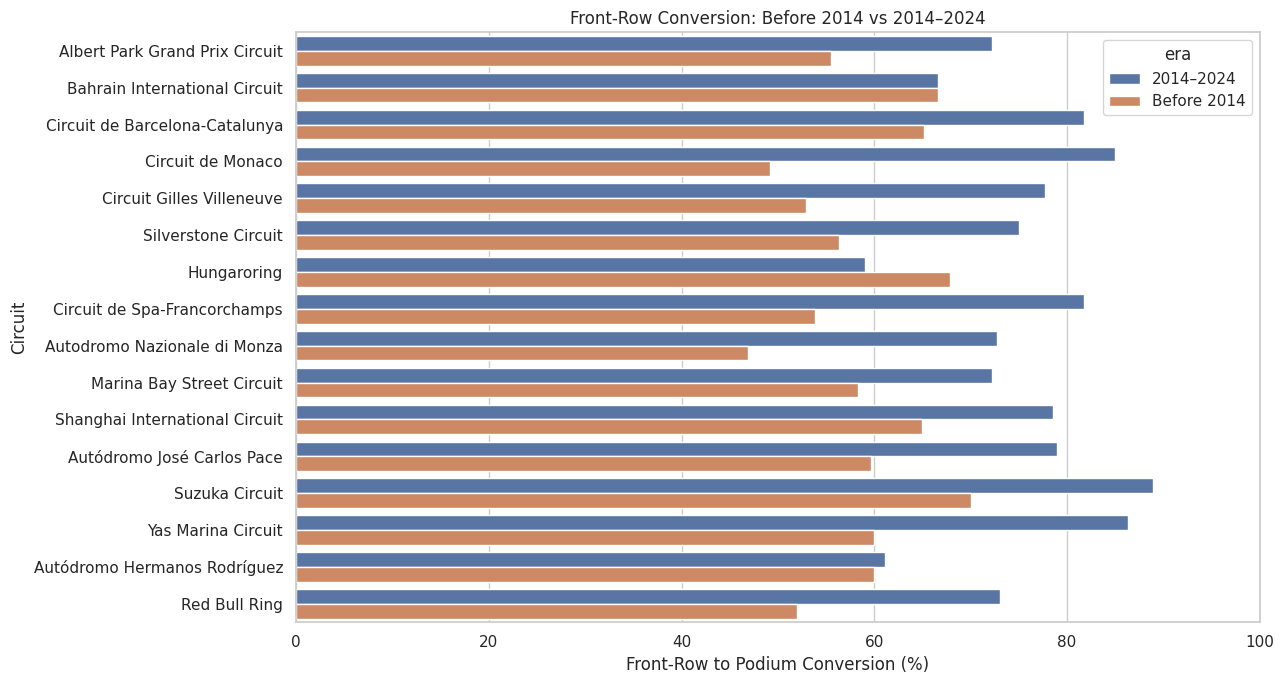

In [60]:

if era_comparison.empty:
    print("No circuits meet the minimum sample requirement in both eras.")
else:
    plt.figure(figsize=(13, 7))

    sns.barplot(
        data=era_comparison,
        x="conversion_rate",
        y="circuitName",
        hue="era"
    )

    plt.xlabel("Front-Row to Podium Conversion (%)")
    plt.ylabel("Circuit")
    plt.title("Front-Row Conversion: Before 2014 vs 2014–2024")
    plt.xlim(0, 100)
    plt.tight_layout()
    plt.show()


In [61]:

qualifying_positions = (
    clean_tables["qualifying"][
        ["raceId", "driverId", "position"]
    ]
    .rename(columns={"position": "qualifying_position"})
    .copy()
)

# Confirm qualifying records are unique at join grain
assert not qualifying_positions.duplicated(
    ["raceId", "driverId"]
).any(), "Duplicate qualifying records require investigation."

grid_qual_comparison = (
    clean_tables["results"][
        ["raceId", "driverId", "grid", "positionOrder"]
    ]
    .merge(
        qualifying_positions,
        on=["raceId", "driverId"],
        how="inner",
        validate="one_to_one"
    )
)

for col in ["grid", "qualifying_position", "positionOrder"]:
    grid_qual_comparison[col] = pd.to_numeric(
        grid_qual_comparison[col],
        errors="coerce"
    )

# Restrict to comparable positive positions
grid_qual_comparison = grid_qual_comparison[
    (grid_qual_comparison["grid"] > 0) &
    (grid_qual_comparison["qualifying_position"] > 0)
].copy()

grid_qual_comparison["position_changed"] = (
    grid_qual_comparison["grid"]
    != grid_qual_comparison["qualifying_position"]
)

print("Comparable driver-race records:",
      len(grid_qual_comparison))

print("Different grid and qualifying positions:",
      grid_qual_comparison["position_changed"].sum())

print("Percentage different:",
      round(
          grid_qual_comparison["position_changed"].mean() * 100,
          2
      )
)

display(
    grid_qual_comparison[
        grid_qual_comparison["position_changed"]
    ].head(10)
)


Comparable driver-race records: 10407
Different grid and qualifying positions: 2422
Percentage different: 23.27


,raceId,driverId,grid,positionOrder,qualifying_position,position_changed
0,1,1,18,20,15,True
1,1,2,9,10,11,True
3,1,4,10,5,12,True
4,1,5,12,19,14,True
5,1,6,11,18,13,True
6,1,7,17,8,20,True
7,1,8,7,15,9,True
9,1,10,19,4,6,True
10,1,12,14,17,17,True
11,1,13,6,16,7,True


,Front Row Type,Observations,Podiums,Conversion Rate (%)
0,Starting Grid,986,692,70.18
1,Qualifying Position,986,680,68.97


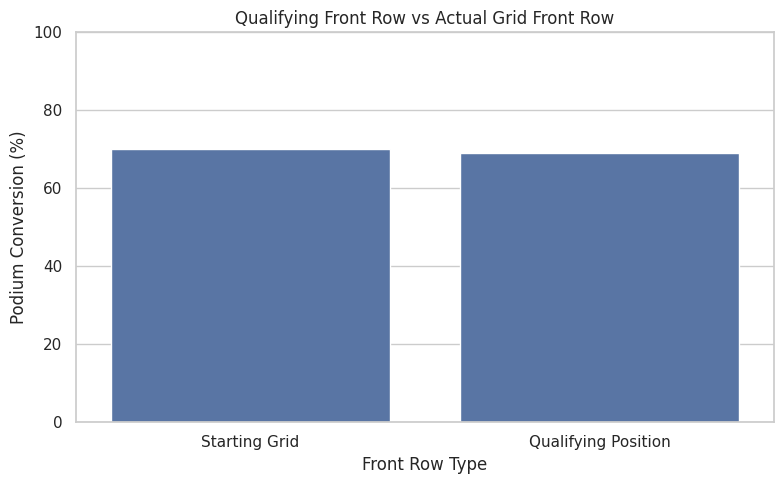

Primary front-row observations: 2250 removed: 0
Exclude Indianapolis front-row observations: 2227 removed: 23
Exclude 2005 US GP front-row observations: 2248 removed: 2
Exclude both front-row observations: 2225 removed: 25


,circuitId,circuitName,era,starts,podiums,conversion_rate,eligible,rank,Scenario
240,22,Suzuka Circuit,2014–2024,18,16,88.89,True,1.0,Exclude 2005 US GP
242,24,Yas Marina Circuit,2014–2024,22,19,86.36,True,2.0,Exclude 2005 US GP
212,6,Circuit de Monaco,2014–2024,20,17,85.00,True,3.0,Exclude 2005 US GP
208,4,Circuit de Barcelona-Catalunya,2014–2024,22,18,81.82,True,4.0,Exclude 2005 US GP
224,13,Circuit de Spa-Francorchamps,2014–2024,22,18,81.82,True,4.0,Exclude 2005 US GP
...,...,...,...,...,...,...,...,...,...
84,64,Ain Diab,Before 2014,2,2,100.00,False,NaN,Primary
85,65,Pescara Circuit,Before 2014,2,2,100.00,False,NaN,Primary
87,67,Circuit de Pedralbes,Before 2014,4,2,50.00,False,NaN,Primary
88,68,Buddh International Circuit,Before 2014,6,5,83.33,False,NaN,Primary


Scenario ranks; NaN denotes fewer than 10 observations:


Scenario                                                    Exclude 2005 US GP  \
circuitId circuitName                          era                               
1         Albert Park Grand Prix Circuit       2014–2024                  14.0   
                                               Before 2014                26.0   
2         Sepang International Circuit         2014–2024                   NaN   
                                               Before 2014                 4.0   
3         Bahrain International Circuit        2014–2024                  16.0   
...                                                                        ...   
76        Autodromo Internazionale del Mugello 2014–2024                   NaN   
77        Jeddah Corniche Circuit              2014–2024                   NaN   
78        Losail International Circuit         2014–2024                   NaN   
79        Miami International Autodrome        2014–2024                   NaN   
80        Las Vegas Strip Street Circuit       2014–2024                   NaN   

Scenario                                                    Exclude Indianapolis  \
circuitId circuitName                          era                                 
1         Albert Park Grand Prix Circuit       2014–2024                    14.0   
                                               Before 2014                  27.0   
2         Sepang International Circuit         2014–2024                     NaN   
                                               Before 2014                   4.0   
3         Bahrain International Circuit        2014–2024                    16.0   
...                                                                          ...   
76        Autodromo Internazionale del Mugello 2014–2024                     NaN   
77        Jeddah Corniche Circuit              2014–2024                     NaN   
78        Losail International Circuit         2014–2024                     NaN   
79        Miami International Autodrome        2014–2024                     NaN   
80        Las Vegas Strip Street Circuit       2014–2024                     NaN   

Scenario                                                    Exclude both  \
circuitId circuitName                          era                         
1         Albert Park Grand Prix Circuit       2014–2024            14.0   
                                               Before 2014          27.0   
2         Sepang International Circuit         2014–2024             NaN   
                                               Before 2014           5.0   
3         Bahrain International Circuit        2014–2024            16.0   
...                                                                  ...   
76        Autodromo Internazionale del Mugello 2014–2024             NaN   
77        Jeddah Corniche Circuit              2014–2024             NaN   
78        Losail International Circuit         2014–2024             NaN   
79        Miami International Autodrome        2014–2024             NaN   
80        Las Vegas Strip Street Circuit       2014–2024             NaN   

Scenario                                                    Primary  
circuitId circuitName                          era                   
1         Albert Park Grand Prix Circuit       2014–2024       14.0  
                                               Before 2014     26.0  
2         Sepang International Circuit         2014–2024        NaN  
                                               Before 2014      4.0  
3         Bahrain International Circuit        2014–2024       16.0  
...                                                             ...  
76        Autodromo Internazionale del Mugello 2014–2024        NaN  
77        Jeddah Corniche Circuit              2014–2024        NaN  
78        Losail International Circuit         2014–2024        NaN  
79        Miami International Autodrome        2014–2024        NaN  
80        L

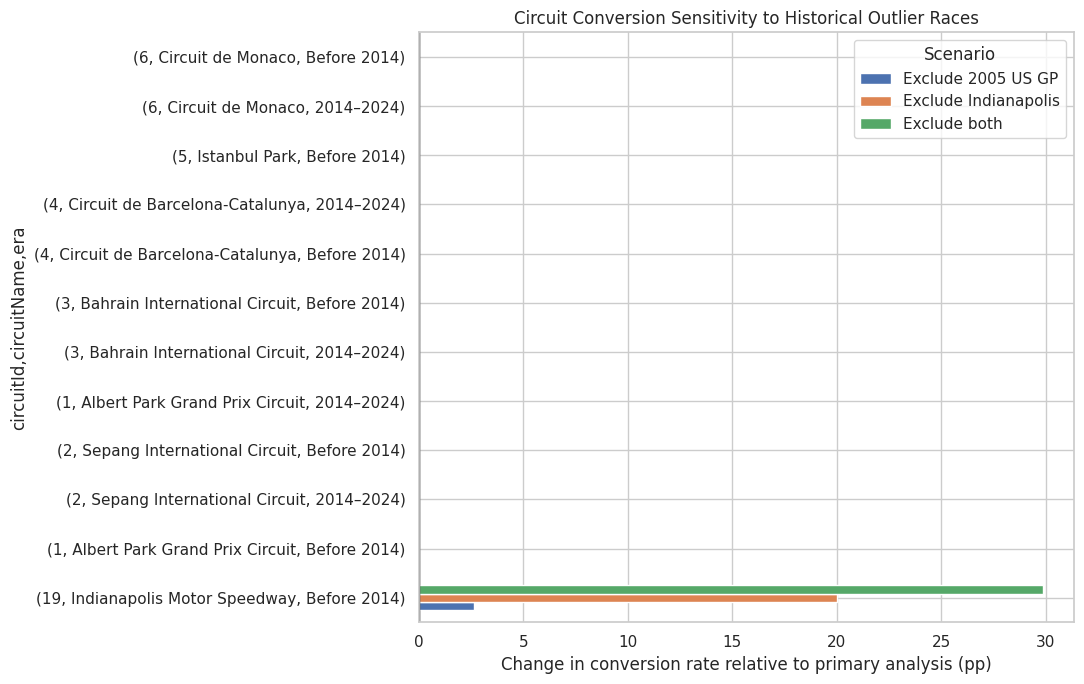

These comparisons are descriptive; race clusters and small samples limit ranking certainty.


In [62]:
comparison = grid_qual_comparison.copy()

comparison["podium"] = (
    comparison["positionOrder"].between(1, 3)
).astype(int)

grid_front = comparison[
    comparison["grid"].isin([1, 2])
]

qual_front = comparison[
    comparison["qualifying_position"].isin([1, 2])
]

front_row_type_comparison = pd.DataFrame({
    "Front Row Type": [
        "Starting Grid",
        "Qualifying Position"
    ],
    "Observations": [
        len(grid_front),
        len(qual_front)
    ],
    "Podiums": [
        grid_front["podium"].sum(),
        qual_front["podium"].sum()
    ],
    "Conversion Rate (%)": [
        grid_front["podium"].mean() * 100,
        qual_front["podium"].mean() * 100
    ]
})

display(front_row_type_comparison.round(2))

plt.figure(figsize=(8, 5))

sns.barplot(
    data=front_row_type_comparison,
    x="Front Row Type",
    y="Conversion Rate (%)"
)

plt.title("Qualifying Front Row vs Actual Grid Front Row")
plt.ylabel("Podium Conversion (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

# Historical-outlier sensitivity; the primary circuit ranking is unchanged.
# Indianapolis 1950–1960 and the unusual 2005 US GP are tested explicitly.
q1_indy = front_row_df["year"].between(1950, 1960) & front_row_df["raceName"].str.contains("Indianapolis", case=False, na=False)
q1_us2005 = front_row_df["year"].eq(2005) & front_row_df["raceName"].str.contains("United States", case=False, na=False)
q1_scenarios = {
    "Primary": front_row_df,
    "Exclude Indianapolis": front_row_df.loc[~q1_indy],
    "Exclude 2005 US GP": front_row_df.loc[~q1_us2005],
    "Exclude both": front_row_df.loc[~q1_indy & ~q1_us2005]
}
q1_sensitivity_parts = []
for scenario, data in q1_scenarios.items():
    part = data.groupby(["circuitId", "circuitName", "era"]).agg(
        starts=("podium", "size"), podiums=("podium", "sum")
    ).reset_index()
    part["conversion_rate"] = 100 * part["podiums"] / part["starts"]
    part["eligible"] = part["starts"].ge(10)
    part["rank"] = part.loc[part["eligible"]].groupby("era")["conversion_rate"].rank(method="min", ascending=False)
    part["Scenario"] = scenario
    q1_sensitivity_parts.append(part)
    print(scenario, "front-row observations:", len(data), "removed:", len(front_row_df)-len(data))
q1_sensitivity = pd.concat(q1_sensitivity_parts, ignore_index=True)
display(q1_sensitivity.sort_values(["era", "Scenario", "rank"]).round(2))
q1_rates = q1_sensitivity.pivot(index=["circuitId", "circuitName", "era"], columns="Scenario", values="conversion_rate")
q1_rank_changes = q1_sensitivity.pivot(index=["circuitId", "circuitName", "era"], columns="Scenario", values="rank")
print("Scenario ranks; NaN denotes fewer than 10 observations:")
display(q1_rank_changes)
q1_delta = q1_rates.sub(q1_rates["Primary"], axis=0).drop(columns="Primary")
if not q1_delta.empty:
    q1_plot = q1_delta.fillna(0).abs().max(axis=1).sort_values(ascending=False).head(12).index
    q1_delta.loc[q1_plot].plot.barh(figsize=(11, 7))
    plt.axvline(0, color="black", linewidth=1)
    plt.xlabel("Change in conversion rate relative to primary analysis (pp)")
    plt.title("Circuit Conversion Sensitivity to Historical Outlier Races")
    plt.tight_layout()
    plt.show()
print("These comparisons are descriptive; race clusters and small samples limit ranking certainty.")


### Question 1 — Findings and Interpretation

**Verification status:** Numerical statements were reconciled with the successful clean saved execution (Version 13, 16 October 2026). Audit results, statistical tables and plotted outputs provide the evidence; predictive associations do not establish causation.

Among circuits meeting the minimum overall sample requirement, **Circuit of the Americas** led the observed front-row podium conversion ranking (approximately **83.33%**); **Sochi Autodrom** and **Circuit de Nevers Magny-Cours** followed at approximately **81.25%** and **80.56%**, respectively.

The comparison across **16 circuits** represented sufficiently in both eras shows ranking changes: **Suzuka** rose from approximately **70.00% to 88.89%**, **Yas Marina** from **60.00% to 86.36%**, and **Monaco** from approximately **49.17% to 85%**. In the separately audited qualifying–grid comparison, **2,422 of 10,407** comparable entries (**23.27%**) had unequal positions. This does **not** imply all such differences were penalties.

**Conclusion:** front-row podium conversion differs across circuits and historical eras. The comparison does not isolate a causal effect of 2014 regulation changes: drivers, teams, circuit configurations, weather, grid rules, and sample sizes also differ. Era-comparison rankings cover only eligible circuits, not all 77 circuits.

The added sensitivity analysis retains the primary ranking and reports front-row sample sizes, eligibility and era-specific ranks after excluding Indianapolis 500 entries, the unusual 2005 United States Grand Prix, and both. A circuit can lose eligibility after exclusion. Changes remain descriptive and are not evidence of a causal regulation effect; race-level dependence and unequal samples limit rank certainty. The sensitivity execution retained 2,250 primary front-row observations; excluding Indianapolis retained 2,227, excluding the 2005 US GP retained 2,248, and excluding both retained 2,225. The original primary ranking is unchanged by this reporting addition.


## Phase 4 — Data-Engineering Question 2: Home-Country Advantage

**Verification status:** Numerical statements were reconciled with the successful clean saved execution (Version 13, 16 October 2026). Audit results, statistical tables and plotted outputs provide the evidence; predictive associations do not establish causation.

**Question:** Are drivers more likely to podium in their home country after controlling for starting position?

We join **results → drivers → races → circuits**. Driver nationality labels are harmonized with circuit-country names (e.g., British → UK; American → USA; Monegasque → Monaco). Six drivers with ambiguous nationality labels are left unmapped rather than assigned arbitrarily. The comparison is restricted to positive grid positions.

To reduce grid-related confounding, we compare home and away podium rates within **P1–P2, P3–P5, P6–P10, P11–P15, and P16+**, then standardize both groups to the same pooled grid-band distribution. This controls for **bands**, not exact grid positions or differences in driver/team quality.


In [63]:

# Phase 4 — Question 2
# Step 1: Inspect nationality and country values

print("Unique driver nationalities:")
nationalities = sorted(
    clean_tables["drivers"]["nationality"]
    .dropna().unique()
)

print(nationalities)

print("\nUnique circuit countries:")
countries = sorted(
    clean_tables["circuits"]["country"]
    .dropna().unique()
)

print(countries)

print("\nNumber of nationalities:", len(nationalities))
print("Number of circuit countries:", len(countries))


Unique driver nationalities:
['American', 'American-Italian', 'Argentine', 'Argentine-Italian', 'Argentinian ', 'Australian', 'Austrian', 'Belgian', 'Brazilian', 'British', 'Canadian', 'Chilean', 'Chinese', 'Colombian', 'Czech', 'Danish', 'Dutch', 'East German', 'Finnish', 'French', 'German', 'Hungarian', 'Indian', 'Indonesian', 'Irish', 'Italian', 'Japanese', 'Liechtensteiner', 'Malaysian', 'Mexican', 'Monegasque', 'New Zealander', 'Polish', 'Portuguese', 'Rhodesian', 'Russian', 'South African', 'Spanish', 'Swedish', 'Swiss', 'Thai', 'Uruguayan', 'Venezuelan']

Unique circuit countries:
['Argentina', 'Australia', 'Austria', 'Azerbaijan', 'Bahrain', 'Belgium', 'Brazil', 'Canada', 'China', 'France', 'Germany', 'Hungary', 'India', 'Italy', 'Japan', 'Korea', 'Malaysia', 'Mexico', 'Monaco', 'Morocco', 'Netherlands', 'Portugal', 'Qatar', 'Russia', 'Saudi Arabia', 'Singapore', 'South Africa', 'Spain', 'Sweden', 'Switzerland', 'Turkey', 'UAE', 'UK', 'USA', 'United States']

Number of national

In [64]:

# Map driver nationality to country
nationality_to_country = {
    "American": "USA",
    "Argentine": "Argentina",
    "Australian": "Australia",
    "Austrian": "Austria",
    "Belgian": "Belgium",
    "Brazilian": "Brazil",
    "British": "UK",
    "Canadian": "Canada",
    "Chilean": "Chile",
    "Chinese": "China",
    "Colombian": "Colombia",
    "Czech": "Czech Republic",
    "Danish": "Denmark",
    "Dutch": "Netherlands",
    "Finnish": "Finland",
    "French": "France",
    "German": "Germany",
    "Hungarian": "Hungary",
    "Indian": "India",
    "Indonesian": "Indonesia",
    "Irish": "Ireland",
    "Italian": "Italy",
    "Japanese": "Japan",
    "Liechtensteiner": "Liechtenstein",
    "Malaysian": "Malaysia",
    "Mexican": "Mexico",
    "Monegasque": "Monaco",
    "New Zealander": "New Zealand",
    "Polish": "Poland",
    "Portuguese": "Portugal",
    "Russian": "Russia",
    "South African": "South Africa",
    "Spanish": "Spain",
    "Swedish": "Sweden",
    "Swiss": "Switzerland",
    "Thai": "Thailand",
    "Uruguayan": "Uruguay",
    "Venezuelan": "Venezuela",
    "Argentinian": "Argentina",
    "East German": "Germany",

    # Ambiguous historical / dual nationality
    "American-Italian": None,
    "Argentine-Italian": None,
    "Rhodesian": None
}

drivers_home = clean_tables["drivers"].copy()

# Remove trailing/leading spaces
drivers_home["nationality_clean"] = (
    drivers_home["nationality"]
    .astype("string")
    .str.strip()
)

drivers_home["home_country"] = (
    drivers_home["nationality_clean"]
    .map(nationality_to_country)
)

# Show unmapped nationalities
unmapped = drivers_home[
    drivers_home["home_country"].isna()
]

print("Unmapped driver records:", len(unmapped))

display(
    unmapped[
        ["driverId", "nationality_clean"]
    ].drop_duplicates()
)

print("Total drivers:", len(drivers_home))


Unmapped driver records: 6


,driverId,nationality_clean
339,340,Rhodesian
367,368,Rhodesian
413,414,Rhodesian
473,473,Rhodesian
491,491,American-Italian
573,573,Argentine-Italian


Total drivers: 861


In [65]:

home_df = (
    clean_tables["results"][
        ["raceId", "driverId", "grid",
         "positionOrder", "statusId"]
    ]
    .merge(
        drivers_home[
            ["driverId", "nationality_clean",
             "home_country"]
        ],
        on="driverId",
        how="left",
        validate="many_to_one"
    )
    .merge(
        clean_tables["races"][
            ["raceId", "year", "circuitId", "name"]
        ].rename(columns={"name": "raceName"}),
        on="raceId",
        how="left",
        validate="many_to_one"
    )
    .merge(
        clean_tables["circuits"][
            ["circuitId", "country", "name"]
        ].rename(columns={"name": "circuitName"}),
        on="circuitId",
        how="left",
        validate="many_to_one"
    )
)

# Normalize the American circuit country labels
home_df["circuit_country"] = (
    home_df["country"].replace({
        "United States": "USA"
    })
)

# Prepare numerical columns
home_df["grid"] = pd.to_numeric(
    home_df["grid"], errors="coerce"
)

home_df["positionOrder"] = pd.to_numeric(
    home_df["positionOrder"], errors="coerce"
)

# Exclude ambiguous or unmapped nationality
home_df = home_df[
    home_df["home_country"].notna()
].copy()

# Restrict primary analysis to positive grid positions
home_df = home_df[
    home_df["grid"] > 0
].copy()

# Podium outcome is for retrospective analysis only
home_df["podium"] = (
    home_df["positionOrder"].between(1, 3)
).astype(int)

home_df["is_home"] = (
    home_df["home_country"]
    == home_df["circuit_country"]
)

assert not home_df.duplicated(
    ["raceId", "driverId"]
).any()

print("Rows after filtering:", len(home_df))
print("Home-country observations:", home_df["is_home"].sum())
print("Away observations:", (~home_df["is_home"]).sum())

display(home_df.head())


Rows after filtering: 25016
Home-country observations: 2322
Away observations: 22694


,raceId,driverId,grid,positionOrder,statusId,nationality_clean,home_country,year,circuitId,raceName,country,circuitName,circuit_country,podium,is_home
0,1,1,18,20,2,British,UK,2009,1,Australian Grand Prix,Australia,Albert Park Grand Prix Circuit,Australia,0,False
1,1,2,9,10,1,German,Germany,2009,1,Australian Grand Prix,Australia,Albert Park Grand Prix Circuit,Australia,0,False
2,1,3,5,6,1,German,Germany,2009,1,Australian Grand Prix,Australia,Albert Park Grand Prix Circuit,Australia,0,False
3,1,4,10,5,1,Spanish,Spain,2009,1,Australian Grand Prix,Australia,Albert Park Grand Prix Circuit,Australia,0,False
4,1,5,12,19,4,Finnish,Finland,2009,1,Australian Grand Prix,Australia,Albert Park Grand Prix Circuit,Australia,0,False


,is_home,entries,podiums,podium_rate,Location
0,False,22694,3118,13.74,Away
1,True,2322,260,11.20,Home


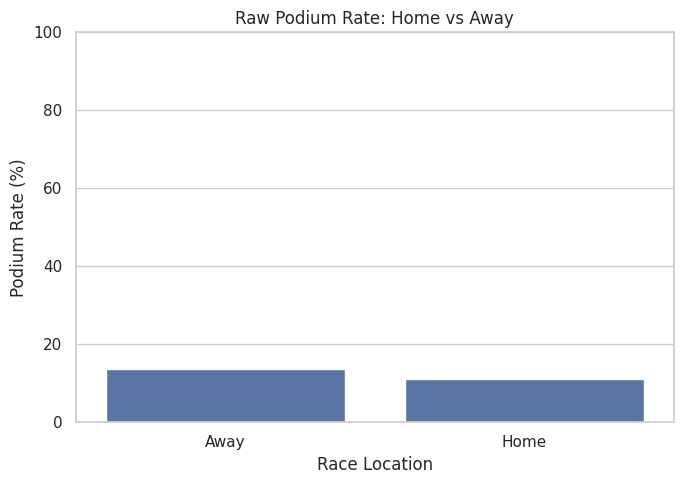

In [66]:

raw_home_comparison = (
    home_df
    .groupby("is_home")
    .agg(
        entries=("podium", "size"),
        podiums=("podium", "sum"),
        podium_rate=("podium", "mean")
    )
    .reset_index()
)

raw_home_comparison["podium_rate"] *= 100

raw_home_comparison["Location"] = (
    raw_home_comparison["is_home"]
    .map({True: "Home", False: "Away"})
)

display(raw_home_comparison.round(2))

plt.figure(figsize=(7, 5))

sns.barplot(
    data=raw_home_comparison,
    x="Location",
    y="podium_rate"
)

plt.ylabel("Podium Rate (%)")
plt.xlabel("Race Location")
plt.title("Raw Podium Rate: Home vs Away")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()


,grid_group,is_home,entries,podiums,podium_rate,Location
0,P1–P2,False,2067,1246,60.28,Away
1,P1–P2,True,183,99,54.10,Home
2,P3–P5,False,3132,1090,34.80,Away
3,P3–P5,True,251,96,38.25,Home
4,P6–P10,False,5144,577,11.22,Away
5,P6–P10,True,476,43,9.03,Home
6,P11–P15,False,5122,152,2.97,Away
7,P11–P15,True,471,15,3.18,Home
8,P16+,False,7229,53,0.73,Away
9,P16+,True,941,7,0.74,Home


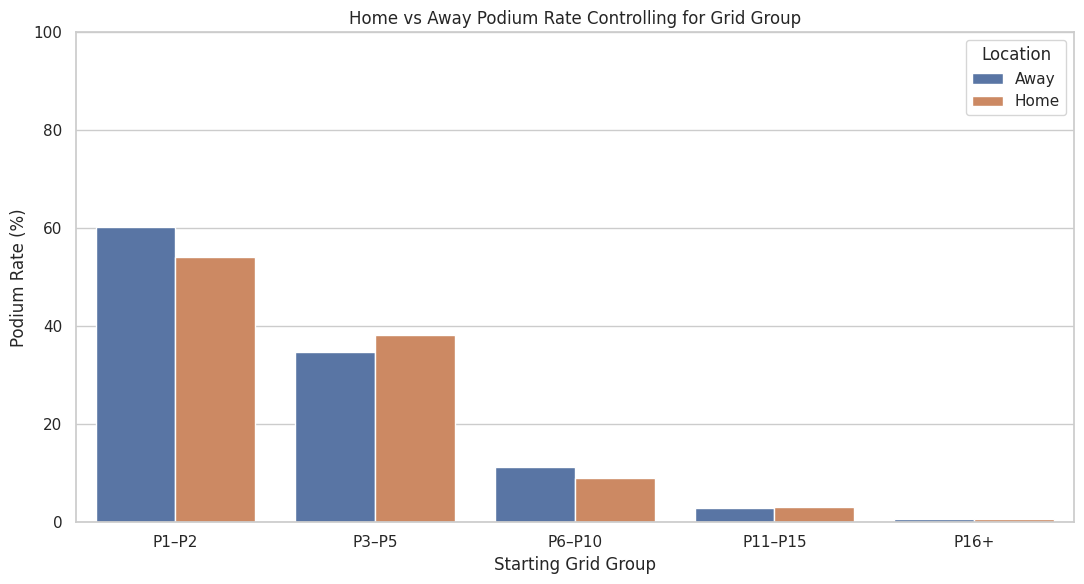

In [67]:

home_df["grid_group"] = pd.cut(
    home_df["grid"],
    bins=[0, 2, 5, 10, 15, np.inf],
    labels=[
        "P1–P2",
        "P3–P5",
        "P6–P10",
        "P11–P15",
        "P16+"
    ]
)

grid_home_comparison = (
    home_df
    .groupby(
        ["grid_group", "is_home"],
        observed=True
    )
    .agg(
        entries=("podium", "size"),
        podiums=("podium", "sum"),
        podium_rate=("podium", "mean")
    )
    .reset_index()
)

grid_home_comparison["podium_rate"] *= 100

grid_home_comparison["Location"] = (
    grid_home_comparison["is_home"]
    .map({True: "Home", False: "Away"})
)

display(grid_home_comparison.round(2))

plt.figure(figsize=(11, 6))

sns.barplot(
    data=grid_home_comparison,
    x="grid_group",
    y="podium_rate",
    hue="Location"
)

plt.xlabel("Starting Grid Group")
plt.ylabel("Podium Rate (%)")
plt.title("Home vs Away Podium Rate Controlling for Grid Group")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()


In [68]:

# Convert rates into a comparison table
rate_table = grid_home_comparison.pivot(
    index="grid_group",
    columns="Location",
    values="podium_rate"
)

# Common weights based on the full sample
weights = (
    home_df["grid_group"]
    .value_counts(normalize=True)
    .reindex(rate_table.index)
)

# Include only groups with home and away observations
valid = rate_table[["Home", "Away"]].notna().all(axis=1)

assert valid.all(), (
    "Some grid groups lack a home or away sample."
)

adjusted_home = (
    rate_table["Home"] * weights
).sum()

adjusted_away = (
    rate_table["Away"] * weights
).sum()

adjusted_difference = adjusted_home - adjusted_away

print(f"Grid-adjusted home podium rate: {adjusted_home:.2f}%")
print(f"Grid-adjusted away podium rate: {adjusted_away:.2f}%")
print(f"Adjusted difference: {adjusted_difference:+.2f} percentage points")


Grid-adjusted home podium rate: 13.02%
Grid-adjusted away podium rate: 13.55%
Adjusted difference: -0.53 percentage points


Possible non-starter rows: 104


status
Withdrew           84
Did not qualify    12
Injury              5
Excluded            2
Eye injury          1
Name: count, dtype: int64

,Scenario,Observations,Home Entries,Adjusted Difference (pp)
0,Original sample,25016,2322,-0.529
1,Exclude possible non-starters,24912,2310,-0.521
2,Exclude Indianapolis 500,24635,1942,-0.465
3,Exclude both,24531,1930,-0.451


,Adjusted difference (pp),95% percentile lower (pp),95% percentile upper (pp),Valid race bootstrap draws,Race clusters
0,-0.528623,-1.999187,0.754764,300,1125


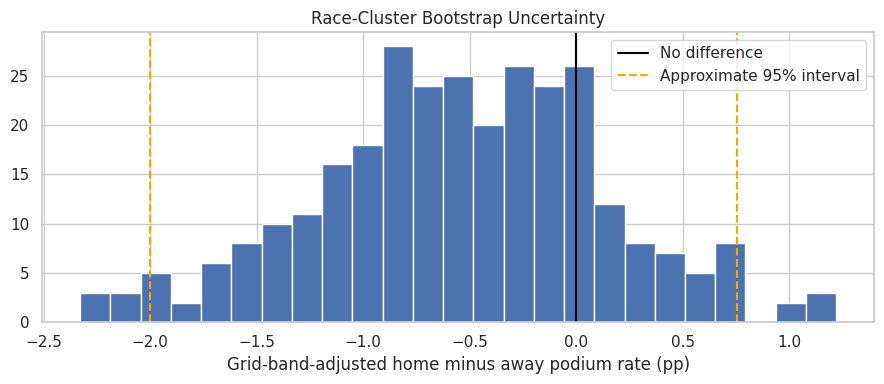

Zero in approximate interval: True
Grid bands leave residual confounding; repeated drivers across races and era drift are not fully modeled.


In [69]:
# Phase 4 — Question 2: Robustness checks

# Use the already-created home_df
audit_df = home_df.copy()

# Join race status descriptions
audit_df = audit_df.merge(
    clean_tables["status"][
        ["statusId", "status"]
    ],
    on="statusId",
    how="left",
    validate="many_to_one"
)

# Check possible non-starters
nonstarter_pattern = (
    r"did not qualify|did not prequalify|"
    r"did not pre-qualify|did not start|"
    r"not started|withdrew|withdrawn|"
    r"injury|excluded"
)

audit_df["possible_nonstarter"] = (
    audit_df["status"]
    .str.contains(
        nonstarter_pattern,
        case=False,
        na=False,
        regex=True
    )
)

print("Possible non-starter rows:",
      audit_df["possible_nonstarter"].sum())

display(
    audit_df.loc[
        audit_df["possible_nonstarter"], "status"
    ].value_counts()
)

# Recalculate standardized home-away difference

def adjusted_home_difference(data):
    data = data.copy()

    data["grid_group"] = pd.cut(
        data["grid"],
        bins=[0, 2, 5, 10, 15, np.inf],
        labels=[
            "P1-P2", "P3-P5", "P6-P10",
            "P11-P15", "P16+"
        ]
    )

    rates = (
        data.groupby(
            ["grid_group", "is_home"],
            observed=True
        )["podium"]
        .mean()
        .unstack()
    )

    # Reindex explicitly using a non-Boolean column index.
    # This avoids pandas confusing labels with a row mask.
    rates = rates.reindex(
        columns=pd.Index(
            [True, False],
            dtype="bool",
            name="is_home"
        )
    )

    if rates.isna().any().any():
        return np.nan

    weights = (
        data["grid_group"]
        .value_counts(normalize=True)
        .reindex(rates.index, fill_value=0)
    )

    home_rate = (rates[True] * weights).sum()
    away_rate = (rates[False] * weights).sum()

    return (home_rate - away_rate) * 100





# Indianapolis 500 was part of the
# championship from 1950 through 1960
indy_mask = (
    audit_df["year"].between(1950, 1960)
    & audit_df["raceName"].str.contains(
        "Indianapolis 500",
        case=False,
        na=False
    )
)

scenarios = {
    "Original sample": audit_df,
    "Exclude possible non-starters":
        audit_df[~audit_df["possible_nonstarter"]],
    "Exclude Indianapolis 500":
        audit_df[~indy_mask],
    "Exclude both":
        audit_df[
            ~audit_df["possible_nonstarter"]
            & ~indy_mask
        ]
}

robustness_results = []

for name, data in scenarios.items():
    robustness_results.append({
        "Scenario": name,
        "Observations": len(data),
        "Home Entries": int(data["is_home"].sum()),
        "Adjusted Difference (pp)":
            adjusted_home_difference(data)
    })

robustness_results = pd.DataFrame(
    robustness_results
)

display(robustness_results.round(3))

# Approximate uncertainty: resample complete races, preserving within-race dependence.
# Fixed pooled grid-band weights target the same standard population in every draw.
q2_counts = home_df.groupby(["raceId", "grid_group", "is_home"], observed=True).agg(
    n=("podium", "size"), k=("podium", "sum")
)
q2_races = home_df["raceId"].unique()
q2_bands = list(home_df["grid_group"].cat.categories)
q2_columns = pd.MultiIndex.from_product([q2_bands, [False, True]])
q2_n = q2_counts["n"].unstack(["grid_group", "is_home"]).reindex(index=q2_races, columns=q2_columns).fillna(0).to_numpy().reshape(len(q2_races), len(q2_bands), 2)
q2_k = q2_counts["k"].unstack(["grid_group", "is_home"]).reindex(index=q2_races, columns=q2_columns).fillna(0).to_numpy().reshape(len(q2_races), len(q2_bands), 2)
q2_weights = home_df["grid_group"].value_counts(normalize=True).reindex(q2_bands).to_numpy()
q2_rng = np.random.default_rng(42)
q2_bootstrap = []
for _ in range(300):
    multiplicities = q2_rng.multinomial(len(q2_races), np.full(len(q2_races), 1 / len(q2_races)))
    n = np.einsum("r,rgh->gh", multiplicities, q2_n)
    k = np.einsum("r,rgh->gh", multiplicities, q2_k)
    if (n > 0).all():
        rates = k / n
        q2_bootstrap.append(100 * np.sum(q2_weights * (rates[:, 1] - rates[:, 0])))
assert len(q2_bootstrap) >= 250, "Too many unsupported bootstrap strata"
q2_ci = np.quantile(q2_bootstrap, [0.025, 0.975])
q2_uncertainty = pd.DataFrame([{
    "Adjusted difference (pp)": adjusted_difference,
    "95% percentile lower (pp)": q2_ci[0], "95% percentile upper (pp)": q2_ci[1],
    "Valid race bootstrap draws": len(q2_bootstrap), "Race clusters": len(q2_races)
}])
display(q2_uncertainty)
plt.figure(figsize=(9, 4))
plt.hist(q2_bootstrap, bins=25)
plt.axvline(0, color="black", label="No difference")
plt.axvline(q2_ci[0], linestyle="--", color="orange", label="Approximate 95% interval")
plt.axvline(q2_ci[1], linestyle="--", color="orange")
plt.xlabel("Grid-band-adjusted home minus away podium rate (pp)")
plt.title("Race-Cluster Bootstrap Uncertainty")
plt.legend()
plt.tight_layout()
plt.show()
print("Zero in approximate interval:", bool(q2_ci[0] <= 0 <= q2_ci[1]))
print("Grid bands leave residual confounding; repeated drivers across races and era drift are not fully modeled.")


### Question 2 — Results and Robustness

**Verification status:** Numerical statements were reconciled with the successful clean saved execution (Version 13, 16 October 2026). Audit results, statistical tables and plotted outputs provide the evidence; predictive associations do not establish causation.

The documented robustness analysis used **25,016 original observations**, including **2,322 home-country entries**. The standardized home-minus-away podium-rate difference was **−0.529 percentage points**. It remained slightly negative after excluding possible non-starters (**−0.521 pp**), the 1950–1960 Indianapolis 500 (**−0.465 pp**), and both (**−0.451 pp**).

**Conclusion:** we do not observe a positive home-country podium advantage after adjustment for starting-grid groups. The observed negative difference is small and must not be presented as a causal disadvantage or as statistically significant without an uncertainty analysis. The possible-nonstarter filter uses retrospective status descriptions **only for sensitivity analysis**, never as a model feature.

The added approximate 95% percentile interval resamples **300 complete race clusters** with fixed pooled grid-band weights, retaining within-race dependence and reporting valid draws. The observed adjusted difference was −0.528623 percentage points; its approximate 95% interval was **[−1.999187, 0.754764] pp**, using 300 valid draws across 1,125 races. The interval includes zero. This is a descriptive uncertainty check: it does not fully capture repeated-driver dependence, era drift, selection into a home race or residual confounding within grid bands. No statistically established or causal home advantage/disadvantage is asserted.


## Phase 4 — Data-Engineering Question 3: Mechanical Retirements

**Question:** Which constructors have the highest mechanical-retirement rates in **2014–2021** versus **2022–2024**?

The analysis joins **results → races → constructors → status**, classifies clearly mechanical/component failure descriptions, excludes known non-starters from the denominator, and retains other race outcomes as non-mechanical starts when appropriate. Mechanical-retirement rate is `mechanical retirements ÷ eligible recorded race starts × 100`. For primary rankings, constructors require at least **20 starts per era**, while unfiltered results remain available.

Classifying recorded race statuses involves judgment. Crashes and regulatory exclusions are not counted as mechanical; ambiguous statuses cannot always establish cause conclusively. These results are retrospective and never enter the pre-race predictors.

In [70]:

# Review all status descriptions used in the target years

status_audit = (
    clean_tables["results"][
        ["raceId", "statusId"]
    ]
    .merge(
        clean_tables["races"][
            ["raceId", "year"]
        ],
        on="raceId",
        how="left"
    )
    .merge(
        clean_tables["status"][
            ["statusId", "status"]
        ],
        on="statusId",
        how="left"
    )
)

status_audit = status_audit[
    status_audit["year"].between(2014, 2024)
]

status_counts = (
    status_audit["status"]
    .value_counts()
    .reset_index()
)

status_counts.columns = ["Status", "Count"]

display(status_counts)

print("Distinct status descriptions:",
      status_counts.shape[0])


,Status,Count
0,Finished,2403
1,+1 Lap,1178
2,+2 Laps,208
3,Collision,150
4,Accident,85
5,Engine,81
6,Collision damage,59
7,Retired,50
8,Brakes,49
9,Gearbox,42


Distinct status descriptions: 66


In [71]:

mechanical_df = (
    clean_tables["results"][
        [
            "raceId", "driverId",
            "constructorId", "grid",
            "positionText", "statusId"
        ]
    ]
    .merge(
        clean_tables["races"][
            ["raceId", "year"]
        ],
        on="raceId",
        how="left",
        validate="many_to_one"
    )
    .merge(
        clean_tables["constructors"][
            ["constructorId", "name"]
        ].rename(columns={"name": "constructorName"}),
        on="constructorId",
        how="left",
        validate="many_to_one"
    )
    .merge(
        clean_tables["status"][
            ["statusId", "status"]
        ],
        on="statusId",
        how="left",
        validate="many_to_one"
    )
)

mechanical_df = mechanical_df[
    mechanical_df["year"].between(2014, 2024)
].copy()

mechanical_df["era"] = np.where(
    mechanical_df["year"] <= 2021,
    "2014–2021",
    "2022–2024"
)

assert not mechanical_df.duplicated(
    ["raceId", "driverId"]
).any()

print("Total records:", len(mechanical_df))
print("Constructors:",
      mechanical_df["constructorId"].nunique())

display(mechanical_df.head())


Total records: 4626
Constructors: 20


,raceId,driverId,constructorId,grid,positionText,statusId,year,constructorName,status,era
22042,900,1,131,1,R,5,2014,Mercedes,Engine,2014–2021
22043,900,3,131,3,1,1,2014,Mercedes,Finished,2014–2021
22044,900,4,6,5,4,1,2014,Ferrari,Finished,2014–2021
22045,900,8,6,11,7,1,2014,Ferrari,Finished,2014–2021
22046,900,13,3,9,R,4,2014,Williams,Collision,2014–2021


In [72]:

# Mechanical component / system failures
mechanical_statuses = {
    "Engine",
    "Gearbox",
    "Transmission",
    "Clutch",
    "Hydraulics",
    "Electrical",
    "Electronics",
    "Brakes",
    "Brake duct",
    "Suspension",
    "Wheel",
    "Wheel bearing",
    "Wheel nut",
    "Power Unit",
    "ERS",
    "Turbo",
    "Turbocharger",
    "MGU-K",
    "MGU-H",
    "Battery",
    "Water leak",
    "Oil leak",
    "Fuel leak",
    "Fuel pump",
    "Fuel system",
    "Oil pressure",
    "Water pressure",
    "Overheating",
    "Radiator",
    "Cooling system",
    "Exhaust",
    "Differential",
    "Driveshaft",
    "Axle",
    "Steering",
    "Throttle",
    "Alternator",
    "Ignition",
    "Spark plugs",
    "Pneumatics",
    "Mechanical",
    "Technical",
    "Vibrations",
    "Drivetrain"
}

# Clear cases where the car did not start
nonstarter_statuses = {
    "Did not start",
    "Did not qualify",
    "Did not prequalify",
    "Did not pre-qualify",
    "Withdrew",
    "Withdrawn",
    "Not started"
}

mechanical_df["status_normalized"] = (
    mechanical_df["status"]
    .astype("string")
    .str.strip()
    .str.casefold()
)

mechanical_lookup = {
    x.casefold() for x in mechanical_statuses
}

nonstarter_lookup = {
    x.casefold() for x in nonstarter_statuses
}

mechanical_df["mechanical_retirement"] = (
    mechanical_df["status_normalized"]
    .isin(mechanical_lookup)
)

mechanical_df["nonstarter"] = (
    mechanical_df["status_normalized"]
    .isin(nonstarter_lookup)
)

# Audit descriptions not included in either list
other_statuses = (
    mechanical_df.loc[
        ~mechanical_df["mechanical_retirement"]
        & ~mechanical_df["nonstarter"],
        "status"
    ]
    .value_counts()
)

print("Mechanical retirements:",
      mechanical_df["mechanical_retirement"].sum())

print("Known non-starters:",
      mechanical_df["nonstarter"].sum())

print("\nOther statuses for review:")
display(other_statuses.to_frame("Count"))


Mechanical retirements: 372
Known non-starters: 14

Other statuses for review:


,Count
status,
Finished,2403
+1 Lap,1178
+2 Laps,208
Collision,150
Accident,85
Collision damage,59
Retired,50
+3 Laps,24
Power loss,13


In [73]:

# Correct additional documented component failures
additional_mechanical_statuses = {
    "Fuel pressure",
    "Fuel pump",
    "Oil pressure",
    "Oil pump",
    "Water pump",
    "Cooling system"
}

mechanical_lookup.update(
    s.casefold() for s in additional_mechanical_statuses
)

mechanical_df["mechanical_retirement"] = (
    mechanical_df["status_normalized"].isin(mechanical_lookup)
)

# Verify categories
assert not (
    mechanical_df["mechanical_retirement"]
    & mechanical_df["nonstarter"]
).any()

print("Updated mechanical retirements:",
      mechanical_df["mechanical_retirement"].sum())

print("\nRemaining status classifications:")
display(
    mechanical_df.loc[
        ~mechanical_df["mechanical_retirement"]
        & ~mechanical_df["nonstarter"],
        "status"
    ].value_counts().to_frame("Count")
)


Updated mechanical retirements: 378

Remaining status classifications:


,Count
status,
Finished,2403
+1 Lap,1178
+2 Laps,208
Collision,150
Accident,85
Collision damage,59
Retired,50
+3 Laps,24
Power loss,13


In [74]:

# Exclude only known non-starters
mechanical_starts = mechanical_df[
    ~mechanical_df["nonstarter"]
].copy()

constructor_reliability = (
    mechanical_starts
    .groupby(
        ["constructorId", "constructorName", "era"]
    )
    .agg(
        race_starts=("driverId", "size"),
        mechanical_retirements=(
            "mechanical_retirement", "sum"
        )
    )
    .reset_index()
)

constructor_reliability["retirement_rate"] = (
    constructor_reliability["mechanical_retirements"]
    / constructor_reliability["race_starts"]
    * 100
)

# Display counts before filtering
display(
    constructor_reliability.sort_values(
        ["era", "retirement_rate"],
        ascending=[True, False]
    ).round(2)
)

# Require at least 20 starts per constructor per era
MIN_STARTS = 20

reliable_ranking = constructor_reliability[
    constructor_reliability["race_starts"] >= MIN_STARTS
].copy()

top_constructors = (
    reliable_ranking
    .sort_values(
        ["era", "retirement_rate"],
        ascending=[True, False]
    )
    .groupby("era")
    .head(10)
)

display(top_constructors.round(2))


,constructorId,constructorName,era,race_starts,mechanical_retirements,retirement_rate
20,207,Caterham,2014–2021,34,8,23.53
21,208,Lotus F1,2014–2021,75,12,16.00
5,5,Toro Rosso,2014–2021,242,38,15.70
0,1,McLaren,2014–2021,318,43,13.52
4,4,Renault,2014–2021,200,27,13.50
11,15,Sauber,2014–2021,200,21,10.50
8,9,Red Bull,2014–2021,319,33,10.34
26,213,AlphaTauri,2014–2021,78,8,10.26
19,206,Marussia,2014–2021,31,3,9.68
23,210,Haas F1 Team,2014–2021,241,23,9.54


,constructorId,constructorName,era,race_starts,mechanical_retirements,retirement_rate
20,207,Caterham,2014–2021,34,8,23.53
21,208,Lotus F1,2014–2021,75,12,16.00
5,5,Toro Rosso,2014–2021,242,38,15.70
0,1,McLaren,2014–2021,318,43,13.52
4,4,Renault,2014–2021,200,27,13.50
11,15,Sauber,2014–2021,200,21,10.50
8,9,Red Bull,2014–2021,319,33,10.34
26,213,AlphaTauri,2014–2021,78,8,10.26
19,206,Marussia,2014–2021,31,3,9.68
23,210,Haas F1 Team,2014–2021,241,23,9.54


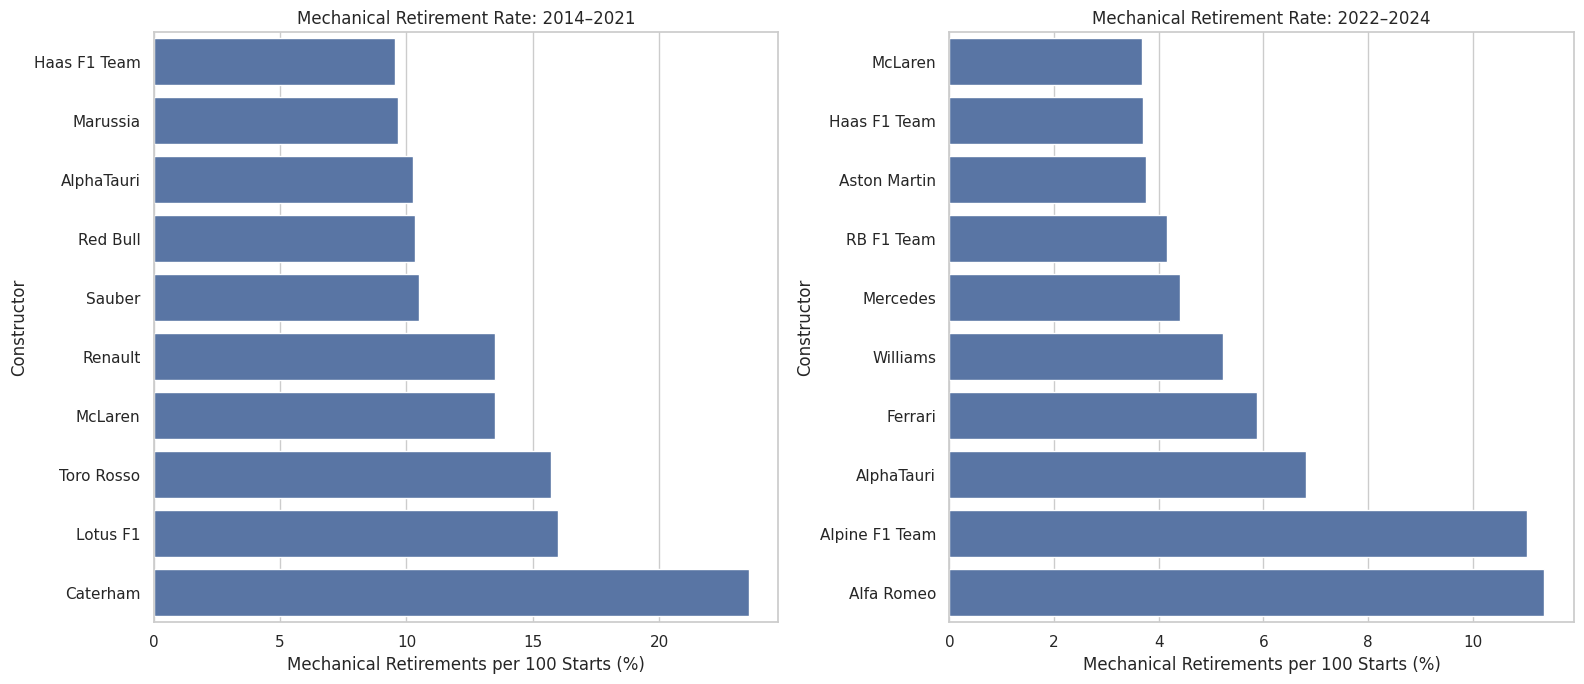

In [75]:

fig, axes = plt.subplots(
    1, 2, figsize=(16, 7)
)

eras = ["2014–2021", "2022–2024"]

for ax, era in zip(axes, eras):

    subset = (
        top_constructors[
            top_constructors["era"] == era
        ]
        .sort_values("retirement_rate")
    )

    sns.barplot(
        data=subset,
        x="retirement_rate",
        y="constructorName",
        ax=ax
    )

    ax.set_title(f"Mechanical Retirement Rate: {era}")
    ax.set_xlabel("Mechanical Retirements per 100 Starts (%)")
    ax.set_ylabel("Constructor")

plt.tight_layout()
plt.show()


In [76]:

constructor_era_wide = reliable_ranking.pivot(
    index=["constructorId", "constructorName"],
    columns="era",
    values="retirement_rate"
)

# Keep constructors represented in both eras
constructor_era_wide = (
    constructor_era_wide
    .dropna(subset=["2014–2021", "2022–2024"])
    .copy()
)

constructor_era_wide["Change (pp)"] = (
    constructor_era_wide["2022–2024"]
    - constructor_era_wide["2014–2021"]
)

display(
    constructor_era_wide
    .sort_values("Change (pp)", ascending=False)
    .round(2)
)


,era,2014–2021,2022–2024,Change (pp)
constructorId,constructorName,,,
51,Alfa Romeo,4.17,11.36,7.20
214,Alpine F1 Team,6.82,11.03,4.21
117,Aston Martin,2.27,3.76,1.49
131,Mercedes,4.06,4.41,0.35
6,Ferrari,5.62,5.88,0.26
3,Williams,7.52,5.22,-2.30
213,AlphaTauri,10.26,6.82,-3.44
210,Haas F1 Team,9.54,3.70,-5.84
9,Red Bull,10.34,3.68,-6.67


In [77]:

# Verify retirement and non-starter categories do not overlap
assert not (
    mechanical_df["mechanical_retirement"]
    & mechanical_df["nonstarter"]
).any()

# Verify there are no impossible rates
assert constructor_reliability[
    "retirement_rate"
].between(0, 100).all()

# Overall mechanical retirement rate per era
era_summary = (
    mechanical_starts.groupby("era")
    .agg(
        race_starts=("driverId", "size"),
        mechanical_retirements=(
            "mechanical_retirement", "sum"
        )
    )
)

era_summary["retirement_rate"] = (
    era_summary["mechanical_retirements"]
    / era_summary["race_starts"]
    * 100
)

print("Overall retirement rates by era:")
display(era_summary.round(2))

print("\nTop constructors in each era:")
display(top_constructors.round(2))


Overall retirement rates by era:


,race_starts,mechanical_retirements,retirement_rate
era,,,
2014–2021,3258,303,9.30
2022–2024,1354,75,5.54



Top constructors in each era:


,constructorId,constructorName,era,race_starts,mechanical_retirements,retirement_rate
20,207,Caterham,2014–2021,34,8,23.53
21,208,Lotus F1,2014–2021,75,12,16.00
5,5,Toro Rosso,2014–2021,242,38,15.70
0,1,McLaren,2014–2021,318,43,13.52
4,4,Renault,2014–2021,200,27,13.50
11,15,Sauber,2014–2021,200,21,10.50
8,9,Red Bull,2014–2021,319,33,10.34
26,213,AlphaTauri,2014–2021,78,8,10.26
19,206,Marussia,2014–2021,31,3,9.68
23,210,Haas F1 Team,2014–2021,241,23,9.54


In [78]:

classification_audit = (
    mechanical_df
    .groupby(
        ["status", "mechanical_retirement", "nonstarter"],
        dropna=False
    )
    .size()
    .reset_index(name="Count")
    .sort_values("Count", ascending=False)
)

classification_audit["Category"] = np.select(
    [
        classification_audit["mechanical_retirement"],
        classification_audit["nonstarter"]
    ],
    [
        "Mechanical retirement",
        "Non-starter"
    ],
    default="Other / non-mechanical"
)

display(classification_audit)

print("\nClassification totals:")
display(
    classification_audit.groupby("Category")["Count"].sum()
)


,status,mechanical_retirement,nonstarter,Count,Category
28,Finished,False,False,2403,Other / non-mechanical
0,+1 Lap,False,False,1178,Other / non-mechanical
1,+2 Laps,False,False,208,Other / non-mechanical
13,Collision,False,False,150,Other / non-mechanical
8,Accident,False,False,85,Other / non-mechanical
25,Engine,True,False,81,Mechanical retirement
14,Collision damage,False,False,59,Other / non-mechanical
47,Retired,False,False,50,Other / non-mechanical
11,Brakes,True,False,49,Mechanical retirement
34,Gearbox,True,False,42,Mechanical retirement



Classification totals:


Category
Mechanical retirement      378
Non-starter                 14
Other / non-mechanical    4234
Name: Count, dtype: int64

In [79]:
# RESULTS — corrected classification

mechanical_starts = mechanical_df.loc[
    ~mechanical_df["nonstarter"]
].copy()

constructor_reliability = (
    mechanical_starts
    .groupby(["constructorId", "constructorName", "era"])
    .agg(
        race_starts=("driverId", "size"),
        mechanical_retirements=("mechanical_retirement", "sum")
    )
    .reset_index()
)

constructor_reliability["retirement_rate"] = (
    100 * constructor_reliability["mechanical_retirements"]
    / constructor_reliability["race_starts"]
)

# Overall statistics for both eras
era_summary = (
    mechanical_starts
    .groupby("era")
    .agg(
        race_starts=("driverId", "size"),
        mechanical_retirements=("mechanical_retirement", "sum")
    )
)

era_summary["retirement_rate"] = (
    100 * era_summary["mechanical_retirements"]
    / era_summary["race_starts"]
)

# Minimum 20 starts per constructor per era
reliable_ranking = constructor_reliability.loc[
    constructor_reliability["race_starts"] >= 20
].copy()

top_constructors = (
    reliable_ranking
    .sort_values(
        ["era", "retirement_rate"],
        ascending=[True, False]
    )
    .groupby("era")
    .head(10)
)

print("FINAL OVERALL ERA RATES")
display(era_summary.round(2))

print("TOP CONSTRUCTORS")
display(top_constructors.round(2))

print("Consistency checks")
assert era_summary["race_starts"].sum() == len(mechanical_starts)
assert era_summary["mechanical_retirements"].sum() == mechanical_starts["mechanical_retirement"].sum()
assert constructor_reliability["retirement_rate"].between(0, 100).all()

print("All numerical consistency checks passed.")


FINAL OVERALL ERA RATES


,race_starts,mechanical_retirements,retirement_rate
era,,,
2014–2021,3258,303,9.30
2022–2024,1354,75,5.54


TOP CONSTRUCTORS


,constructorId,constructorName,era,race_starts,mechanical_retirements,retirement_rate
20,207,Caterham,2014–2021,34,8,23.53
21,208,Lotus F1,2014–2021,75,12,16.00
5,5,Toro Rosso,2014–2021,242,38,15.70
0,1,McLaren,2014–2021,318,43,13.52
4,4,Renault,2014–2021,200,27,13.50
11,15,Sauber,2014–2021,200,21,10.50
8,9,Red Bull,2014–2021,319,33,10.34
26,213,AlphaTauri,2014–2021,78,8,10.26
19,206,Marussia,2014–2021,31,3,9.68
23,210,Haas F1 Team,2014–2021,241,23,9.54


Consistency checks
All numerical consistency checks passed.


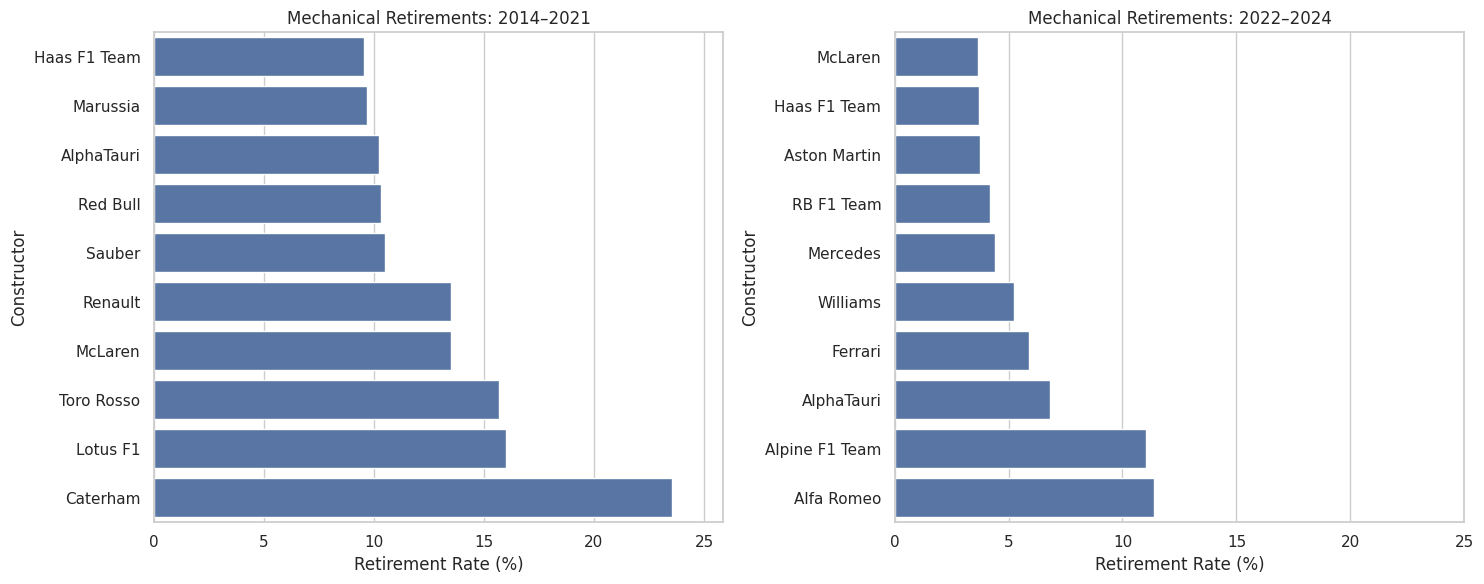

,status,status_normalized,mechanical_retirement,nonstarter,ambiguous_status,Records
0,+1 Lap,+1 lap,False,False,False,1178
1,+2 Laps,+2 laps,False,False,False,208
2,+3 Laps,+3 laps,False,False,False,24
3,+4 Laps,+4 laps,False,False,False,6
4,+5 Laps,+5 laps,False,False,False,1
5,+6 Laps,+6 laps,False,False,False,2
6,+7 Laps,+7 laps,False,False,False,1
7,+8 Laps,+8 laps,False,False,False,2
8,Accident,accident,False,False,False,85
9,Battery,battery,True,False,False,5


,constructorId,constructorName,era,eligible_records,failures,rate_pct,Scenario,rank
51,207,Caterham,2014–2021,34,8,23.53,Ambiguous causes excluded from numerator,1.0
36,5,Toro Rosso,2014–2021,242,37,15.29,Ambiguous causes excluded from numerator,2.0
52,208,Lotus F1,2014–2021,75,11,14.67,Ambiguous causes excluded from numerator,3.0
35,4,Renault,2014–2021,200,26,13.00,Ambiguous causes excluded from numerator,4.0
31,1,McLaren,2014–2021,318,40,12.58,Ambiguous causes excluded from numerator,5.0
57,213,AlphaTauri,2014–2021,78,8,10.26,Ambiguous causes excluded from numerator,6.0
39,9,Red Bull,2014–2021,319,32,10.03,Ambiguous causes excluded from numerator,7.0
42,15,Sauber,2014–2021,200,20,10.00,Ambiguous causes excluded from numerator,8.0
50,206,Marussia,2014–2021,31,3,9.68,Ambiguous causes excluded from numerator,9.0
56,211,Racing Point,2014–2021,76,7,9.21,Ambiguous causes excluded from numerator,10.0


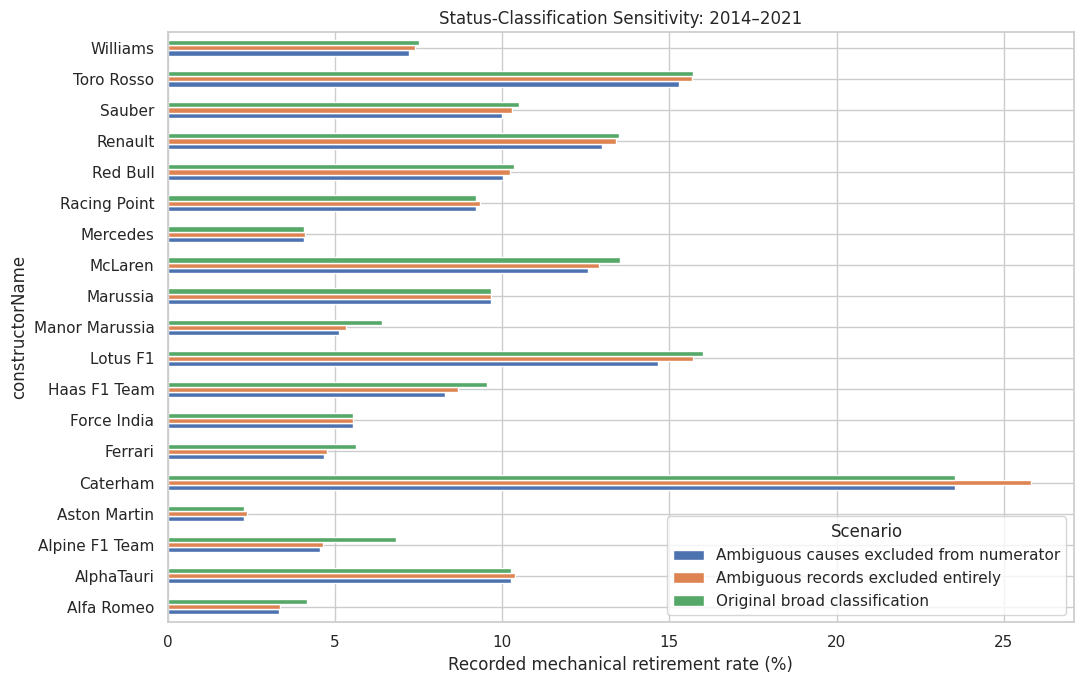

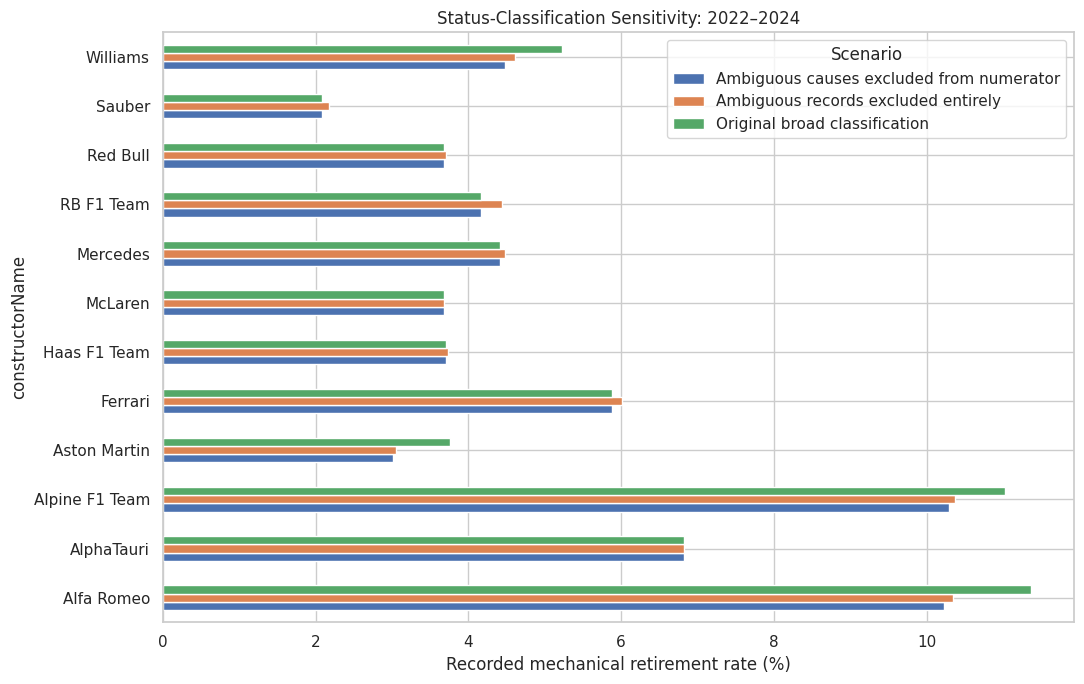

Accidents, driver errors, and regulatory outcomes are never mechanical numerators.
Status labels alone cannot resolve collision-induced failures or confirm every actual start; constructor identities remain separate.


In [80]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for ax, era in zip(axes, ["2014–2021", "2022–2024"]):
    subset = (
        top_constructors[top_constructors["era"] == era]
        .sort_values("retirement_rate")
    )

    sns.barplot(
        data=subset,
        x="retirement_rate",
        y="constructorName",
        ax=ax
    )

    ax.set_title(f"Mechanical Retirements: {era}")
    ax.set_xlabel("Retirement Rate (%)")
    ax.set_ylabel("Constructor")
    ax.set_xlim(0, max(25, subset["retirement_rate"].max() * 1.1))

plt.tight_layout()
plt.show()

# Transparent sensitivity to statuses whose cause or actual start is uncertain.
# Preserve the original broad classification and ranking; add a conservative comparison.
q3_ambiguous_labels = {"mechanical", "technical", "vibrations", "wheel", "tyre", "puncture", "damage", "retired", "injury", "excluded", "not classified", "disqualified"}
mechanical_df["ambiguous_status"] = mechanical_df["status_normalized"].isin(q3_ambiguous_labels) | mechanical_df["status"].isna()
q3_status_mapping = mechanical_df.groupby(
    ["status", "status_normalized", "mechanical_retirement", "nonstarter", "ambiguous_status"], dropna=False
).size().reset_index(name="Records")
display(q3_status_mapping)
q3_sensitivity_parts = []
for scenario, data in {
    "Original broad classification": mechanical_df.loc[~mechanical_df["nonstarter"]],
    "Ambiguous causes excluded from numerator": mechanical_df.loc[~mechanical_df["nonstarter"]],
    "Ambiguous records excluded entirely": mechanical_df.loc[~mechanical_df["nonstarter"] & ~mechanical_df["ambiguous_status"]]
}.items():
    data = data.copy()
    data["sensitivity_failure"] = data["mechanical_retirement"]
    if scenario != "Original broad classification":
        data["sensitivity_failure"] &= ~data["ambiguous_status"]
    part = data.groupby(["constructorId", "constructorName", "era"]).agg(
        eligible_records=("driverId", "size"), failures=("sensitivity_failure", "sum")
    ).reset_index()
    part["rate_pct"] = 100 * part["failures"] / part["eligible_records"]
    part["Scenario"] = scenario
    q3_sensitivity_parts.append(part)
q3_sensitivity = pd.concat(q3_sensitivity_parts, ignore_index=True)
q3_eligible = q3_sensitivity.loc[q3_sensitivity["eligible_records"].ge(20)].copy()
q3_eligible["rank"] = q3_eligible.groupby(["Scenario", "era"])["rate_pct"].rank(method="min", ascending=False)
display(q3_eligible.sort_values(["era", "Scenario", "rank"]).round(2))
for era, data in q3_eligible.groupby("era"):
    data.pivot(index="constructorName", columns="Scenario", values="rate_pct").plot.barh(figsize=(11, 7))
    plt.xlabel("Recorded mechanical retirement rate (%)")
    plt.title("Status-Classification Sensitivity: " + str(era))
    plt.tight_layout()
    plt.show()
print("Accidents, driver errors, and regulatory outcomes are never mechanical numerators.")
print("Status labels alone cannot resolve collision-induced failures or confirm every actual start; constructor identities remain separate.")


### Question 3 — Findings and Limitations

**Verification status:** Numerical statements were reconciled with the successful clean saved execution (Version 13, 16 October 2026). Audit results, statistical tables and plotted outputs provide the evidence; predictive associations do not establish causation.

The final status audit classifies **378** records as mechanical retirements, **14** as known non-starters, and **4,234** as other outcomes across **4,626** driver–race result records for 2014–2024.

Based on the corrected calculation, the observed mechanical-retirement rate was approximately **9.30% (2014–2021)** versus **5.54% (2022–2024)**. **Caterham (23.53%)**, **Lotus F1 (16.00%)**, and **Toro Rosso (15.70%)** led the earlier era among eligible constructors. **Alfa Romeo (11.36%)**, **Alpine F1 Team (about 11%)**, and **AlphaTauri (6.82%)** led the later era.

**Conclusion:** recorded component-related retirement rates were lower in the later period, but historical classification ambiguity, actual-starter uncertainty, unequal observation windows, and constructor rebranding limit interpretation. These data do not establish that regulation changes caused the difference.

The broad original classification is retained. A displayed status mapping flags generic or ambiguous causes (such as Mechanical, Technical, Vibrations, Wheel, damage and unexplained retirement) and uncertain start/administrative outcomes. Additional rankings compare excluding ambiguous causes from the numerator and excluding ambiguous records from both numerator and denominator. Crashes, driver errors and regulatory decisions never count as mechanical failures. A component label can conceal collision damage; status alone cannot establish every actual start or root cause. The denominator is therefore an eligible-record proxy for race starts, and the executed sensitivity results show classification dependence. Caterham remains the highest-rate earlier-era constructor in both sensitivity analyses. In 2022–2024, excluding ambiguous causes from the numerator puts **Alpine first (14/136 = 10.29%)** and **Alfa Romeo second (9/88 = 10.23%)**, reversing their broad-classification order. Excluding ambiguous records entirely gives **Alpine 14/135 = 10.37%** and **Alfa Romeo 9/87 = 10.34%**. The displayed mapping also shows unclassified descriptions such as **Power loss (13 records)** outside the broad mechanical numerator; status-based rates depend on these judgment calls.


## Phase 5 — Leakage-Safe Feature Engineering

**Verification status:** Numerical statements were reconciled with the successful clean saved execution (Version 13, 16 October 2026). Audit results, statistical tables and plotted outputs provide the evidence; predictive associations do not establish causation.

The cleaned results table is joined to race context and driver-specific qualifying measurements, producing one row per `(raceId, driverId)`. The target `podium` is defined from the historical finishing outcome but is excluded from the input feature matrix.

The **16 numeric predictors** cover: **grid** (position and missingness), **qualifying** (position, Q1 time, and availability flags), **driver form** (prior entries and historical/recent podium rates), **constructor form** (prior entries and historical/recent podium rates), **pre-race season points**, and **race context** (`year`, `round`). Grid selection is supported by EDA; qualifying and standings reflect known pre-race competitiveness, while history summarizes prior performance.

Driver cumulative and last-five race metrics exclude the current race. Constructor form is aggregated first at the **constructor–race grain**, then shifted, so one teammate's result from the same race is not exposed to the other teammate. Season points are reconstructed from previous recorded results; they may not exactly match official standings because of historical scoring conventions, sprint points, or penalties.

The modeling export contains **26,668 driver–race rows** and 16 predictors. Historical features can be missing for a driver's or constructor's first observed race; Q1 and qualifying position are often unavailable for early eras. Outcome data and status remain excluded from `feature_columns`.

### Feature provenance and prediction-cutoff justification

All 16 existing features are retained. Evidence is hypothesis-driven, supported by the original EDA, the added **training-only** Spearman/coverage plots, and exploratory validation group ablation. Held-out 2022–2024 outcomes do not determine feature inclusion.

| Feature | Source table(s) | Derivation | Availability at prediction cutoff | Supporting evidence or hypothesis |
|---|---|---|---|---|
| `grid` | results | Recorded starting-grid position; zero is retained | Assumes final published grid known before start | Grid EDA; training association; grid ablation |
| `grid_missing` | results | 1 if grid missing or <=0 | Computable from grid | Zero/missing values differ from ordinary positions |
| `qualifying_position` | qualifying | Driver position joined by raceId/driverId | Completed qualifying | Qualifying/grid comparison; qualifying ablation |
| `q1_seconds` | qualifying | Parsed Q1 seconds; one flagged anomaly becomes missing in modeling copy | Completed qualifying | Proxy for pace; training Q1 distribution and correlation |
| `qualifying_available` | qualifying | Position present indicator | Known qualifying-record availability | Historical coverage drift EDA |
| `q1_missing` | qualifying | Q1 seconds missing indicator | Known before prediction | Separates absent timing from a numerical lap time |
| `driver_prior_starts` | results, races | Count of strictly prior unique driver–race records | Earlier race history | Experience/exposure hypothesis; driver-form ablation |
| `driver_career_podium_rate` | results, races | Prior podiums / prior entries | Earlier outcomes only | Persistent competitiveness hypothesis; driver EDA and ablation |
| `driver_last5_podium_rate` | results, races | Mean of five previous recorded outcomes | Earlier outcomes only | Recent form hypothesis; driver-form ablation |
| `constructor_prior_entries` | results, races | Prior constructor–race entry totals | Earlier constructor history | Experience/exposure hypothesis; constructor-form ablation |
| `constructor_career_podium_rate` | results, races | Prior constructor podiums / prior entries | Earlier outcomes only | Team-strength EDA and constructor-form ablation |
| `constructor_last5_podium_rate` | results, races | Prior five constructor races: podium sum / entry sum | Earlier outcomes; current teammates excluded together | Recent team-strength hypothesis and ablation |
| `driver_points_before_race` | results, races | Same-season cumulative recorded points excluding current race | Earlier race points | Season competitiveness hypothesis; standings ablation |
| `constructor_points_before_race` | results, races | Aggregate points per constructor-race, then exclude current race | Earlier race points; current teammates excluded | Team competitiveness hypothesis; standings ablation |
| `year` | races | Season year | Published calendar | Era-drift hypothesis; training year diagnostics/context ablation |
| `round` | races | Season round | Published calendar | Season progression hypothesis; context ablation |

**Limits and eligibility.** `year` is an era proxy that can extrapolate poorly and absorb confounding; it is not a causal technical-regulation effect. Absolute Q1 seconds also reflect circuit length/layout, weather and qualifying format, so they are not normalized measures of driver skill. The dataset's `grid=0` is a special source convention that can include pit-lane starts and historical non-starters; it is not interpreted as better than pole. The existing `grid_missing` flag covers zero as well as null, while the raw zero remains in `grid`. Qualifying-record coverage is not the same as Q1 timing completeness, and coverage/format changes across eras. The fixed 2006 training start reduces this drift but does not eliminate missingness.

The modeling population includes all cleaned recorded entries in the selected years, including historical DNQ/DNPQ/DNS/withdrawn entries when present. No post-race status filter silently changes the prediction population. Consequently, `driver_prior_starts` counts prior **entries**, not verified actual starts; constructor exposure and historical rates have the same entry-based interpretation. This differs from Question 3's eligible-start proxy. Non-starters usually have non-podium labels, so entry selection affects class prevalence and deployment interpretation.

The temporal audit checks that each contributing prior driver/constructor race date is strictly earlier and recomputes cumulative/rolling form and same-season points from shifted outcomes. Constructor outcomes are aggregated before shifting. Official standings tables are not directly used: reconstructed race points omit sprint points and may differ under historical scoring, penalties or retrospective corrections. Earlier test-race outcomes can update later test-race form in sequential pre-race evaluation; they do not fit transformations or choose features, models, hyperparameters or thresholds. Full historical as-of snapshots are unavailable, so retrospective appeals/corrections remain a source-data limitation.


In [81]:

import pandas as pd
import numpy as np

# Build independent modeling dataset
model_df = clean_tables["results"].copy()

race_features = clean_tables["races"][
    ["raceId", "year", "round", "date", "circuitId"]
].copy()

model_df = model_df.merge(
    race_features,
    on="raceId",
    how="left",
    validate="many_to_one"
)

model_df["date"] = pd.to_datetime(model_df["date"])

for col in ["grid", "positionOrder", "points"]:
    model_df[col] = pd.to_numeric(
        model_df[col], errors="coerce"
    )

# Target: 1 = podium, 0 = no podium
model_df["podium"] = (
    model_df["positionOrder"].between(1, 3)
).astype(int)

# Chronological ordering
model_df = model_df.sort_values(
    ["date", "round", "raceId", "driverId"]
).reset_index(drop=True)

# Verify unique modeling grain
assert not model_df.duplicated(
    ["raceId", "driverId"]
).any()

assert model_df["date"].notna().all()
assert model_df["podium"].isin([0, 1]).all()

print("Driver-race observations:", len(model_df))
print("Podium distribution:")
display(model_df["podium"].value_counts(normalize=True) * 100)

display(model_df[
    ["raceId", "driverId", "constructorId",
     "year", "round", "grid", "podium"]
].head())


Driver-race observations: 26668
Podium distribution:


podium
0    87.329384
1    12.670616
Name: proportion, dtype: float64

,raceId,driverId,constructorId,year,round,grid,podium
0,833,579,51,1950,1,3,0
1,833,589,105,1950,1,11,0
2,833,619,151,1950,1,13,0
3,833,627,154,1950,1,9,0
4,833,640,105,1950,1,8,0


In [82]:

# Use the modeling copy with the flagged Suzuka anomaly
qual_features = qualifying_model[
    [
        "raceId", "driverId",
        "position", "q1_seconds",
        "q1_anomaly_flag"
    ]
].copy()

qual_features = qual_features.rename(
    columns={"position": "qualifying_position"}
)

assert not qual_features.duplicated(
    ["raceId", "driverId"]
).any()

rows_before = len(model_df)

model_df = model_df.merge(
    qual_features,
    on=["raceId", "driverId"],
    how="left",
    validate="one_to_one"
)

assert len(model_df) == rows_before

model_df["qualifying_position"] = pd.to_numeric(
    model_df["qualifying_position"],
    errors="coerce"
)

model_df["q1_seconds"] = pd.to_numeric(
    model_df["q1_seconds"],
    errors="coerce"
)

model_df["qualifying_available"] = (
    model_df["qualifying_position"].notna()
).astype(int)

model_df["grid_missing"] = (
    model_df["grid"].isna()
    | (model_df["grid"] <= 0)
).astype(int)

# Flag missing qualifying times
model_df["q1_missing"] = (
    model_df["q1_seconds"].isna()
).astype(int)

print("Rows after qualifying join:", len(model_df))
print("Missing Q1 values:", model_df["q1_missing"].sum())
print("Qualifying coverage:",
      round(model_df["qualifying_available"].mean() * 100, 2), "%")

display(model_df[
    [
        "year", "grid", "qualifying_position",
        "q1_seconds", "qualifying_available",
        "q1_missing"
    ]
].head(10))


Rows after qualifying join: 26668
Missing Q1 values: 16331
Qualifying coverage: 39.35 %


,year,grid,qualifying_position,q1_seconds,qualifying_available,q1_missing
0,1950,3,NaN,NaN,0,1
1,1950,11,NaN,NaN,0,1
2,1950,13,NaN,NaN,0,1
3,1950,9,NaN,NaN,0,1
4,1950,8,NaN,NaN,0,1
5,1950,1,NaN,NaN,0,1
6,1950,21,NaN,NaN,0,1
7,1950,10,NaN,NaN,0,1
8,1950,10,NaN,NaN,0,1
9,1950,5,NaN,NaN,0,1


In [83]:

# Driver historical form (past races only)

model_df = model_df.sort_values(
    ["date", "round", "raceId", "driverId"]
).reset_index(drop=True)

driver_group = model_df.groupby(
    "driverId", sort=False
)

# Prior race records
model_df["driver_prior_starts"] = (
    driver_group.cumcount()
)

# Prior career podium total
model_df["driver_prior_podiums"] = (
    driver_group["podium"].cumsum()
    - model_df["podium"]
)

# Prior career podium rate
model_df["driver_career_podium_rate"] = (
    model_df["driver_prior_podiums"]
    / model_df["driver_prior_starts"].replace(0, np.nan)
)

# Last five previous race outcomes
model_df["driver_last5_podium_rate"] = (
    model_df.groupby("driverId")["podium"]
    .transform(
        lambda s: s.shift(1).rolling(
            window=5, min_periods=1
        ).mean()
    )
)

# First race has no prior history
print("Missing career rates:",
      model_df["driver_career_podium_rate"].isna().sum())

display(
    model_df[
        [
            "driverId", "year",
            "driver_prior_starts",
            "driver_career_podium_rate",
            "driver_last5_podium_rate"
        ]
    ].head(10)
)


Missing career rates: 861


,driverId,year,driver_prior_starts,driver_career_podium_rate,driver_last5_podium_rate
0,579,1950,0,NaN,NaN
1,589,1950,0,NaN,NaN
2,619,1950,0,NaN,NaN
3,627,1950,0,NaN,NaN
4,640,1950,0,NaN,NaN
5,642,1950,0,NaN,NaN
6,660,1950,0,NaN,NaN
7,661,1950,0,NaN,NaN
8,666,1950,0,NaN,NaN
9,669,1950,0,NaN,NaN


In [84]:

# Constructor form: aggregate at constructor-race grain

constructor_race = (
    model_df.groupby(
        ["constructorId", "raceId", "date", "round"],
        as_index=False
    )
    .agg(
        constructor_race_podiums=("podium", "sum"),
        constructor_race_entries=("driverId", "size")
    )
)

constructor_race = constructor_race.sort_values(
    ["constructorId", "date", "round", "raceId"]
).reset_index(drop=True)

constructor_group = constructor_race.groupby(
    "constructorId", sort=False
)

# Prior constructor entries and podiums
constructor_race["constructor_prior_entries"] = (
    constructor_group["constructor_race_entries"].cumsum()
    - constructor_race["constructor_race_entries"]
)

constructor_race["constructor_prior_podiums"] = (
    constructor_group["constructor_race_podiums"].cumsum()
    - constructor_race["constructor_race_podiums"]
)

constructor_race["constructor_career_podium_rate"] = (
    constructor_race["constructor_prior_podiums"]
    / constructor_race["constructor_prior_entries"].replace(
        0, np.nan
    )
)

# Prior five races: average podiums per car entry
past5_podiums = (
    constructor_race.groupby("constructorId")[
        "constructor_race_podiums"
    ].transform(
        lambda s: s.shift(1).rolling(
            5, min_periods=1
        ).sum()
    )
)

past5_entries = (
    constructor_race.groupby("constructorId")[
        "constructor_race_entries"
    ].transform(
        lambda s: s.shift(1).rolling(
            5, min_periods=1
        ).sum()
    )
)

constructor_race["constructor_last5_podium_rate"] = (
    past5_podiums / past5_entries.replace(0, np.nan)
)

# Merge past-only constructor form
constructor_features = constructor_race[
    [
        "constructorId", "raceId",
        "constructor_prior_entries",
        "constructor_career_podium_rate",
        "constructor_last5_podium_rate"
    ]
]

rows_before = len(model_df)

model_df = model_df.merge(
    constructor_features,
    on=["constructorId", "raceId"],
    how="left",
    validate="many_to_one"
)

assert len(model_df) == rows_before

print("Constructor form features created.")
display(model_df[
    [
        "raceId", "constructorId",
        "constructor_prior_entries",
        "constructor_career_podium_rate",
        "constructor_last5_podium_rate"
    ]
].head(10))


Constructor form features created.


,raceId,constructorId,constructor_prior_entries,constructor_career_podium_rate,constructor_last5_podium_rate
0,833,51,0,NaN,NaN
1,833,105,0,NaN,NaN
2,833,151,0,NaN,NaN
3,833,154,0,NaN,NaN
4,833,105,0,NaN,NaN
5,833,51,0,NaN,NaN
6,833,154,0,NaN,NaN
7,833,151,0,NaN,NaN
8,833,151,0,NaN,NaN
9,833,105,0,NaN,NaN


In [85]:

# Driver season points before each race
model_df = model_df.sort_values(
    ["date", "round", "raceId", "driverId"]
).reset_index(drop=True)

model_df["driver_points_before_race"] = (
    model_df.groupby(["year", "driverId"])["points"]
    .cumsum()
    - model_df["points"]
)

# Constructor points must first be aggregated per race
constructor_season = (
    model_df.groupby(
        ["year", "raceId", "constructorId",
         "date", "round"],
        as_index=False
    )["points"]
    .sum()
)

constructor_season = constructor_season.sort_values(
    ["year", "constructorId", "date", "round", "raceId"]
)

constructor_season["constructor_points_before_race"] = (
    constructor_season.groupby(
        ["year", "constructorId"]
    )["points"].cumsum()
    - constructor_season["points"]
)

model_df = model_df.merge(
    constructor_season[
        [
            "raceId", "constructorId",
            "constructor_points_before_race"
        ]
    ],
    on=["raceId", "constructorId"],
    how="left",
    validate="many_to_one"
)

print("Pre-race season points created.")

display(model_df[
    [
        "year", "round", "driverId",
        "constructorId",
        "driver_points_before_race",
        "constructor_points_before_race"
    ]
].tail(10))


Pre-race season points created.


,year,round,driverId,constructorId,driver_points_before_race,constructor_points_before_race
26658,2024,24,844,6,312.0,562.0
26659,2024,24,846,1,319.0,583.0
26660,2024,24,847,131,216.0,411.0
26661,2024,24,848,3,12.0,17.0
26662,2024,24,852,215,29.0,40.0
26663,2024,24,855,15,4.0,4.0
26664,2024,24,857,1,264.0,583.0
26665,2024,24,859,215,4.0,40.0
26666,2024,24,861,3,5.0,17.0
26667,2024,24,862,214,0.0,57.0


In [86]:

# Final predictor list, organized by feature group
feature_groups = {
    "grid": [
        "grid",
        "grid_missing"
    ],
    "qualifying": [
        "qualifying_position",
        "q1_seconds",
        "qualifying_available",
        "q1_missing"
    ],
    "driver_form": [
        "driver_prior_starts",
        "driver_career_podium_rate",
        "driver_last5_podium_rate"
    ],
    "constructor_form": [
        "constructor_prior_entries",
        "constructor_career_podium_rate",
        "constructor_last5_podium_rate"
    ],
    "standings": [
        "driver_points_before_race",
        "constructor_points_before_race"
    ],
    "race_context": [
        "year",
        "round"
    ]
}

feature_columns = [
    col
    for columns in feature_groups.values()
    for col in columns
]

# Target and metadata kept separate
modeling_table = model_df[
    ["raceId", "driverId", "constructorId",
     "date", "circuitId", "podium"] + feature_columns
].copy()

# Check unique driver-race grain
assert not modeling_table.duplicated(
    ["raceId", "driverId"]
).any()

# Verify current-race outcome columns are excluded
forbidden = [
    "positionOrder", "position", "positionText",
    "statusId", "points", "laps",
    "milliseconds", "fastestLap",
    "fastestLapTime", "fastestLapSpeed",
    "time"
]

assert not set(forbidden).intersection(feature_columns)

# Verify all model features are numeric
assert all(
    pd.api.types.is_numeric_dtype(modeling_table[col])
    for col in feature_columns
)

X = modeling_table[feature_columns].copy()
y = modeling_table["podium"].copy()

print("Modeling dataset shape:", modeling_table.shape)
print("Number of features:", len(feature_columns))
print("Target distribution:")
display(y.value_counts())

print("\nMissing feature values:")
display(
    X.isna().sum()
    .sort_values(ascending=False)
    .to_frame("Missing Count")
)

display(modeling_table.head())


Modeling dataset shape: (26668, 22)
Number of features: 16
Target distribution:


podium
0    23289
1     3379
Name: count, dtype: int64


Missing feature values:


,Missing Count
q1_seconds,16331
qualifying_position,16174
driver_career_podium_rate,861
driver_last5_podium_rate,861
constructor_career_podium_rate,347
constructor_last5_podium_rate,347
grid,0
grid_missing,0
driver_prior_starts,0
q1_missing,0


,raceId,driverId,constructorId,date,circuitId,podium,grid,grid_missing,qualifying_position,q1_seconds,qualifying_available,q1_missing,driver_prior_starts,driver_career_podium_rate,driver_last5_podium_rate,constructor_prior_entries,constructor_career_podium_rate,constructor_last5_podium_rate,driver_points_before_race,constructor_points_before_race,year,round
0,833,579,51,1950-05-13,9,0,3,0,NaN,NaN,0,1,0,NaN,NaN,0,NaN,NaN,0.0,0.0,1950,1
1,833,589,105,1950-05-13,9,0,11,0,NaN,NaN,0,1,0,NaN,NaN,0,NaN,NaN,0.0,0.0,1950,1
2,833,619,151,1950-05-13,9,0,13,0,NaN,NaN,0,1,0,NaN,NaN,0,NaN,NaN,0.0,0.0,1950,1
3,833,627,154,1950-05-13,9,0,9,0,NaN,NaN,0,1,0,NaN,NaN,0,NaN,NaN,0.0,0.0,1950,1
4,833,640,105,1950-05-13,9,0,8,0,NaN,NaN,0,1,0,NaN,NaN,0,NaN,NaN,0.0,0.0,1950,1


In [87]:
# Every driver's first historical entry has zero prior records
first_driver_rows = (
    model_df.sort_values(
        ["date", "round", "raceId"]
    )
    .groupby("driverId")
    .head(1)
)

assert (
    first_driver_rows["driver_prior_starts"] == 0
).all()

assert (
    first_driver_rows["driver_prior_podiums"] == 0
).all()

# At each constructor's first race, historical entries = 0
first_constructor_rows = (
    constructor_race
    .sort_values(["date", "round", "raceId"])
    .groupby("constructorId")
    .head(1)
)

assert (
    first_constructor_rows["constructor_prior_entries"] == 0
).all()

assert (
    first_constructor_rows["constructor_prior_podiums"] == 0
).all()

# All historical rates must be between 0 and 1
rate_cols = [
    "driver_career_podium_rate",
    "driver_last5_podium_rate",
    "constructor_career_podium_rate",
    "constructor_last5_podium_rate"
]

for col in rate_cols:
    valid_values = model_df[col].dropna()
    assert valid_values.between(0, 1).all(), col

# Confirm target is binary
assert set(y.unique()).issubset({0, 1})

print("Historical feature validation passed.")
print("Feature groups:", list(feature_groups.keys()))
print("Feature count:", len(feature_columns))

# Temporal provenance and independent shifted-history checks.
temporal_driver = model_df.sort_values(["date", "round", "raceId", "driverId"]).copy()
prior_driver_date = temporal_driver.groupby("driverId")["date"].shift(1)
assert (prior_driver_date.isna() | prior_driver_date.lt(temporal_driver["date"])).all(), "Driver history includes a non-earlier race"
prior_constructor_date = constructor_race.groupby("constructorId")["date"].shift(1)
assert (prior_constructor_date.isna() | prior_constructor_date.lt(constructor_race["date"])).all(), "Constructor history includes a non-earlier race"

def assert_same_history(actual, expected, label):
    assert np.allclose(np.asarray(actual, dtype=float), np.asarray(expected, dtype=float), equal_nan=True), label

assert_same_history(temporal_driver["driver_career_podium_rate"], temporal_driver.groupby("driverId")["podium"].transform(lambda s: s.shift(1).expanding().mean()), "Driver career history mismatch")
assert_same_history(temporal_driver["driver_last5_podium_rate"], temporal_driver.groupby("driverId")["podium"].transform(lambda s: s.shift(1).rolling(5, min_periods=1).mean()), "Driver recent history mismatch")
assert_same_history(temporal_driver["driver_prior_starts"], temporal_driver.groupby("driverId").cumcount(), "Prior entries mismatch")
assert_same_history(temporal_driver["driver_points_before_race"], temporal_driver.groupby(["year", "driverId"])["points"].transform(lambda s: s.shift(1, fill_value=0).cumsum()), "Driver season points mismatch")
assert_same_history(constructor_race["constructor_prior_entries"], constructor_race.groupby("constructorId")["constructor_race_entries"].transform(lambda s: s.shift(1, fill_value=0).cumsum()), "Constructor entry history mismatch")
constructor_expected_podiums = constructor_race.groupby("constructorId")["constructor_race_podiums"].transform(lambda s: s.shift(1, fill_value=0).cumsum())
assert_same_history(constructor_race["constructor_career_podium_rate"], constructor_expected_podiums / constructor_race["constructor_prior_entries"].replace(0, np.nan), "Constructor career history mismatch")
assert_same_history(constructor_race["constructor_last5_podium_rate"], constructor_race.groupby("constructorId")["constructor_race_podiums"].transform(lambda s: s.shift(1).rolling(5, min_periods=1).sum()) / constructor_race.groupby("constructorId")["constructor_race_entries"].transform(lambda s: s.shift(1).rolling(5, min_periods=1).sum()), "Constructor recent history mismatch")
constructor_points_check = constructor_season.copy()
constructor_points_check["expected_points"] = constructor_points_check.groupby(["year", "constructorId"])["points"].transform(lambda s: s.shift(1, fill_value=0).cumsum())
assert_same_history(constructor_points_check["constructor_points_before_race"], constructor_points_check["expected_points"], "Constructor season points mismatch")
print("Historical features verified using strictly earlier race dates and shifted outcomes.")
print("Evaluation is sequential: an earlier validation/test race may inform a later race, but never fitting, thresholds or model selection.")


Historical feature validation passed.
Feature groups: ['grid', 'qualifying', 'driver_form', 'constructor_form', 'standings', 'race_context']
Feature count: 16
Historical features verified using strictly earlier race dates and shifted outcomes.
Evaluation is sequential: an earlier validation/test race may inform a later race, but never fitting, thresholds or model selection.


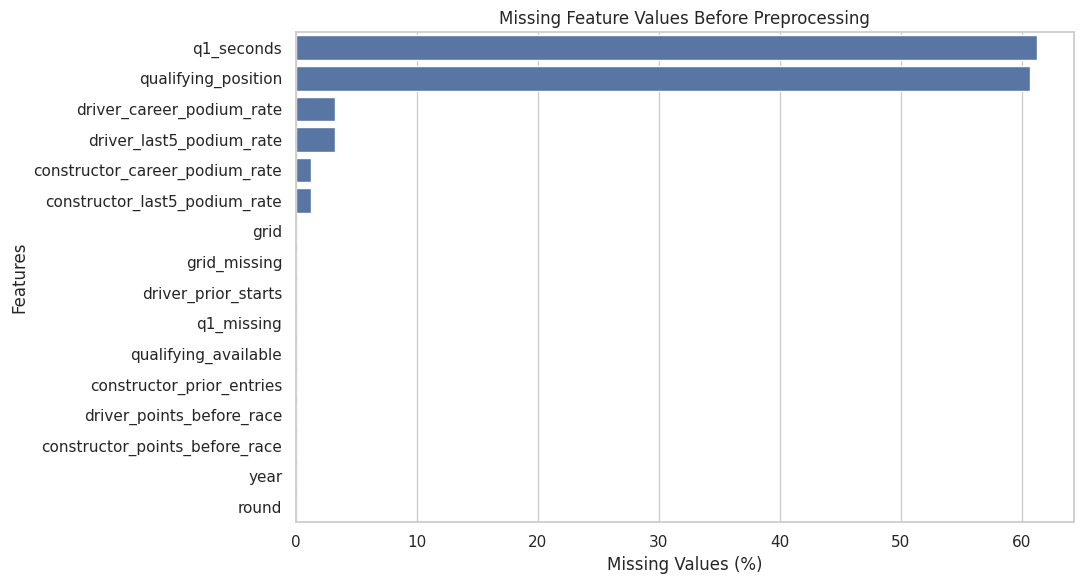

In [88]:

missing_rates = (
    X.isna().mean() * 100
).sort_values(ascending=False)

plt.figure(figsize=(11, 6))

sns.barplot(
    x=missing_rates.values,
    y=missing_rates.index
)

plt.title("Missing Feature Values Before Preprocessing")
plt.xlabel("Missing Values (%)")
plt.ylabel("Features")
plt.tight_layout()
plt.show()


In [89]:

from pathlib import Path

output_path = Path(
    "/kaggle/working/f1_modeling_table.csv"
)

modeling_table.to_csv(output_path, index=False)

print("Saved:", output_path)
print("Rows:", len(modeling_table))
print("Features:", len(feature_columns))


Saved: /kaggle/working/f1_modeling_table.csv
Rows: 26668
Features: 16


## Phase 6 — Chronological Split and Training-Only Preprocessing

To reflect real-world future prediction, races are divided by **complete seasons**, not shuffled randomly: **train 2006–2019**, **validation 2020–2021**, **test 2022–2024**. Pre-2006 records can still supply past-history context for engineered features, but are not primary training examples. Keeping a whole Grand Prix in one partition prevents cross-split race overlap.

The baseline preprocessing is **median imputation followed by StandardScaler**, with both transformations fitted on training data alone. Validation/test observations use those stored parameters unchanged. Missingness flags distinguish absent qualifying information from real numerical values. Distribution plots illustrate how scaling changes center and range without necessarily removing skew.

Three configurations are prepared for later experiments: (A) median imputation → standard scaling; (B) standard scaling → median imputation; (C) median imputation → robust scaling. Data preparation, hyperparameter development, and threshold selection must not fit on test records. The test-set peek occurred before Phase 8 in the notebook, so later Phase 8 analysis is honestly described as **exploratory** rather than a new untouched-test model-selection exercise.

The original full-history EDA also includes years later assigned to the test partition, and test results were previously inspected. This review cannot retroactively establish a pristine untouched-test study. The fixed feature set, split, models and hyperparameters are preserved; new evidence uses training/validation rows only and does not use test scores to revise those decisions.


In [90]:

# PHASE 6 — Chronological splitting

import pandas as pd
import numpy as np

train_df = modeling_table[
    modeling_table["year"].between(2006, 2019)
].copy()

val_df = modeling_table[
    modeling_table["year"].between(2020, 2021)
].copy()

test_df = modeling_table[
    modeling_table["year"].between(2022, 2024)
].copy()

split_summary = pd.DataFrame({
    "Split": ["Train", "Validation", "Test"],
    "Period": ["2006–2019", "2020–2021", "2022–2024"],
    "Rows": [len(train_df), len(val_df), len(test_df)],
    "Podiums": [
        train_df["podium"].sum(),
        val_df["podium"].sum(),
        test_df["podium"].sum()
    ],
    "Podium Rate (%)": [
        train_df["podium"].mean() * 100,
        val_df["podium"].mean() * 100,
        test_df["podium"].mean() * 100
    ]
})

display(split_summary.round(2))

assert len(train_df) > 0
assert len(val_df) > 0
assert len(test_df) > 0

assert train_df["year"].max() < val_df["year"].min()
assert val_df["year"].max() < test_df["year"].min()

assert set(train_df["raceId"]).isdisjoint(val_df["raceId"])
assert set(train_df["raceId"]).isdisjoint(test_df["raceId"])
assert set(val_df["raceId"]).isdisjoint(test_df["raceId"])

print("Chronological split validation passed.")


,Split,Period,Rows,Podiums,Podium Rate (%)
0,Train,2006–2019,5775,804,13.92
1,Validation,2020–2021,780,117,15.00
2,Test,2022–2024,1359,204,15.01


Chronological split validation passed.


In [91]:

X_train = train_df[feature_columns].copy()
X_val = val_df[feature_columns].copy()
X_test = test_df[feature_columns].copy()

y_train = train_df["podium"].copy()
y_val = val_df["podium"].copy()
y_test = test_df["podium"].copy()

print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)

print("\nTrain target distribution:")
display(y_train.value_counts(normalize=True).round(4))


X_train: (5775, 16)
X_val: (780, 16)
X_test: (1359, 16)

Train target distribution:


podium
0    0.8608
1    0.1392
Name: proportion, dtype: float64

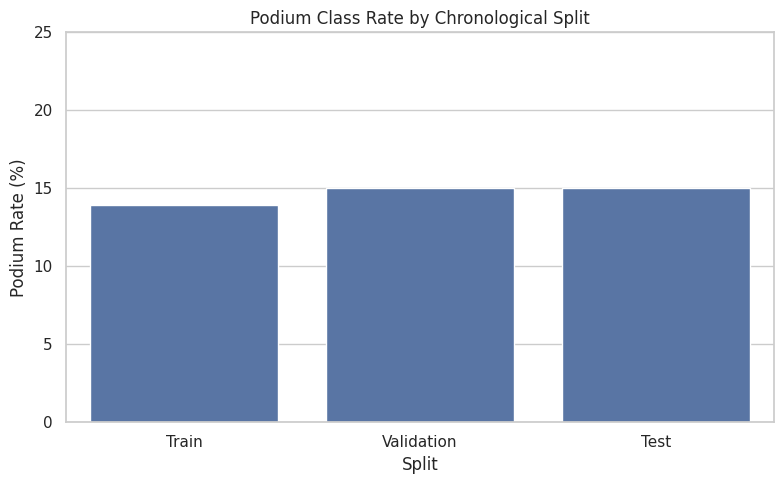

In [92]:

import matplotlib.pyplot as plt
import seaborn as sns

plot_df = split_summary.copy()

plt.figure(figsize=(8, 5))

sns.barplot(
    data=plot_df,
    x="Split",
    y="Podium Rate (%)"
)

plt.title("Podium Class Rate by Chronological Split")
plt.ylabel("Podium Rate (%)")
plt.ylim(0, 25)
plt.tight_layout()
plt.show()


In [93]:

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Pipeline for Logistic Regression and neural network
standard_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Learn preprocessing statistics ONLY from training
X_train_scaled = standard_preprocessor.fit_transform(X_train)

# Apply the same learned preprocessing to validation
X_val_scaled = standard_preprocessor.transform(X_val)

# Do not fit on validation or test
assert X_train_scaled.shape == X_train.shape
assert X_val_scaled.shape == X_val.shape

assert np.isfinite(X_train_scaled).all()
assert np.isfinite(X_val_scaled).all()

print("Training preprocessing completed.")
print("Train shape:", X_train_scaled.shape)
print("Validation shape:", X_val_scaled.shape)


Training preprocessing completed.
Train shape: (5775, 16)
Validation shape: (780, 16)


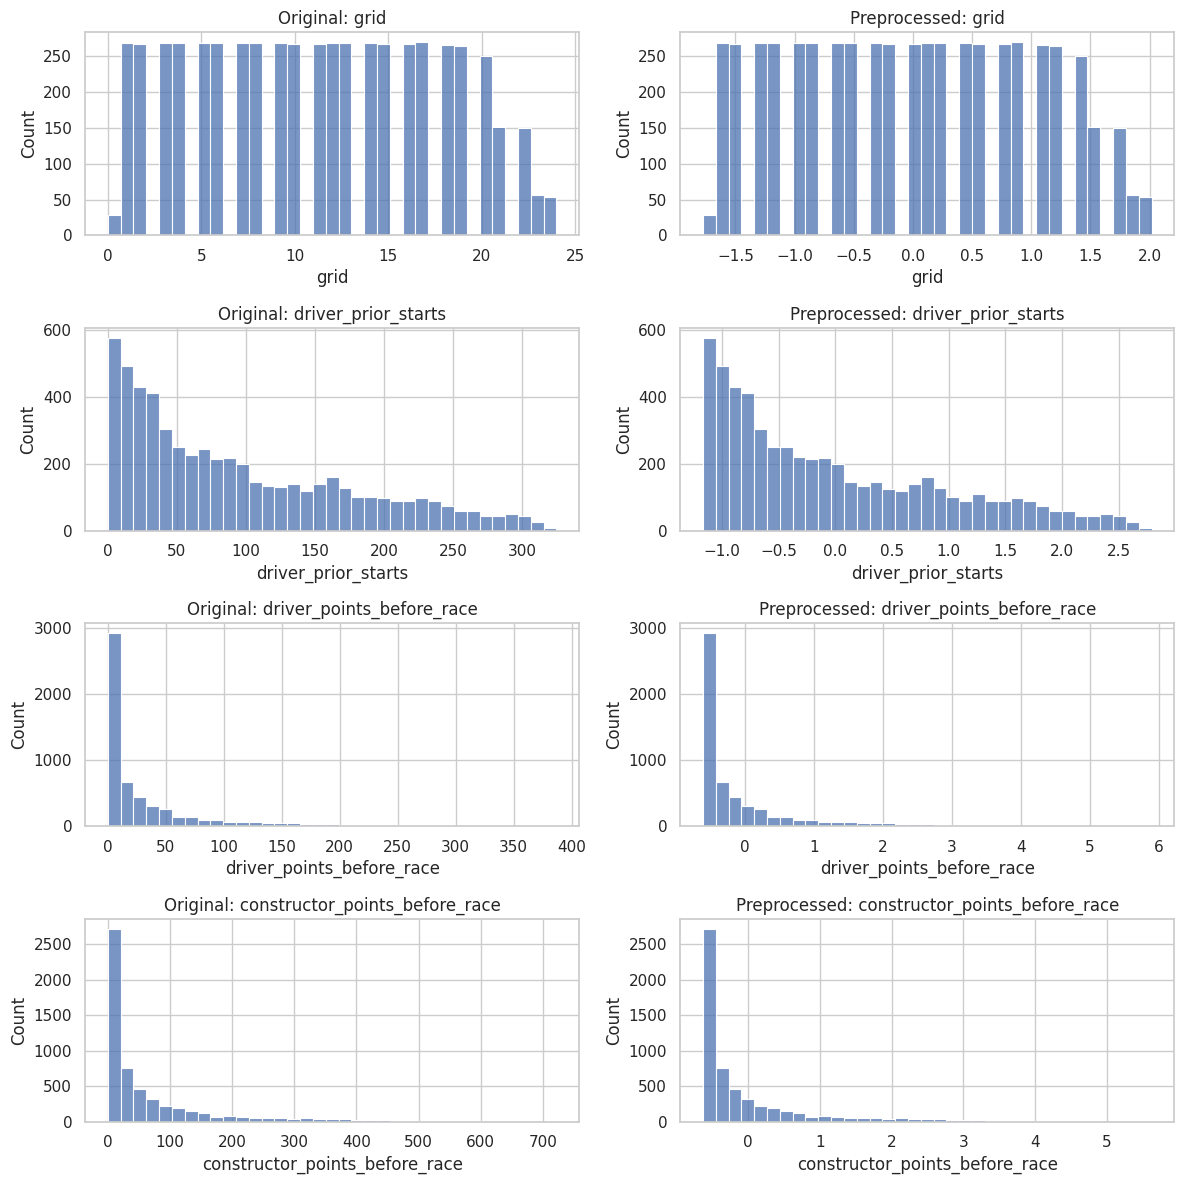

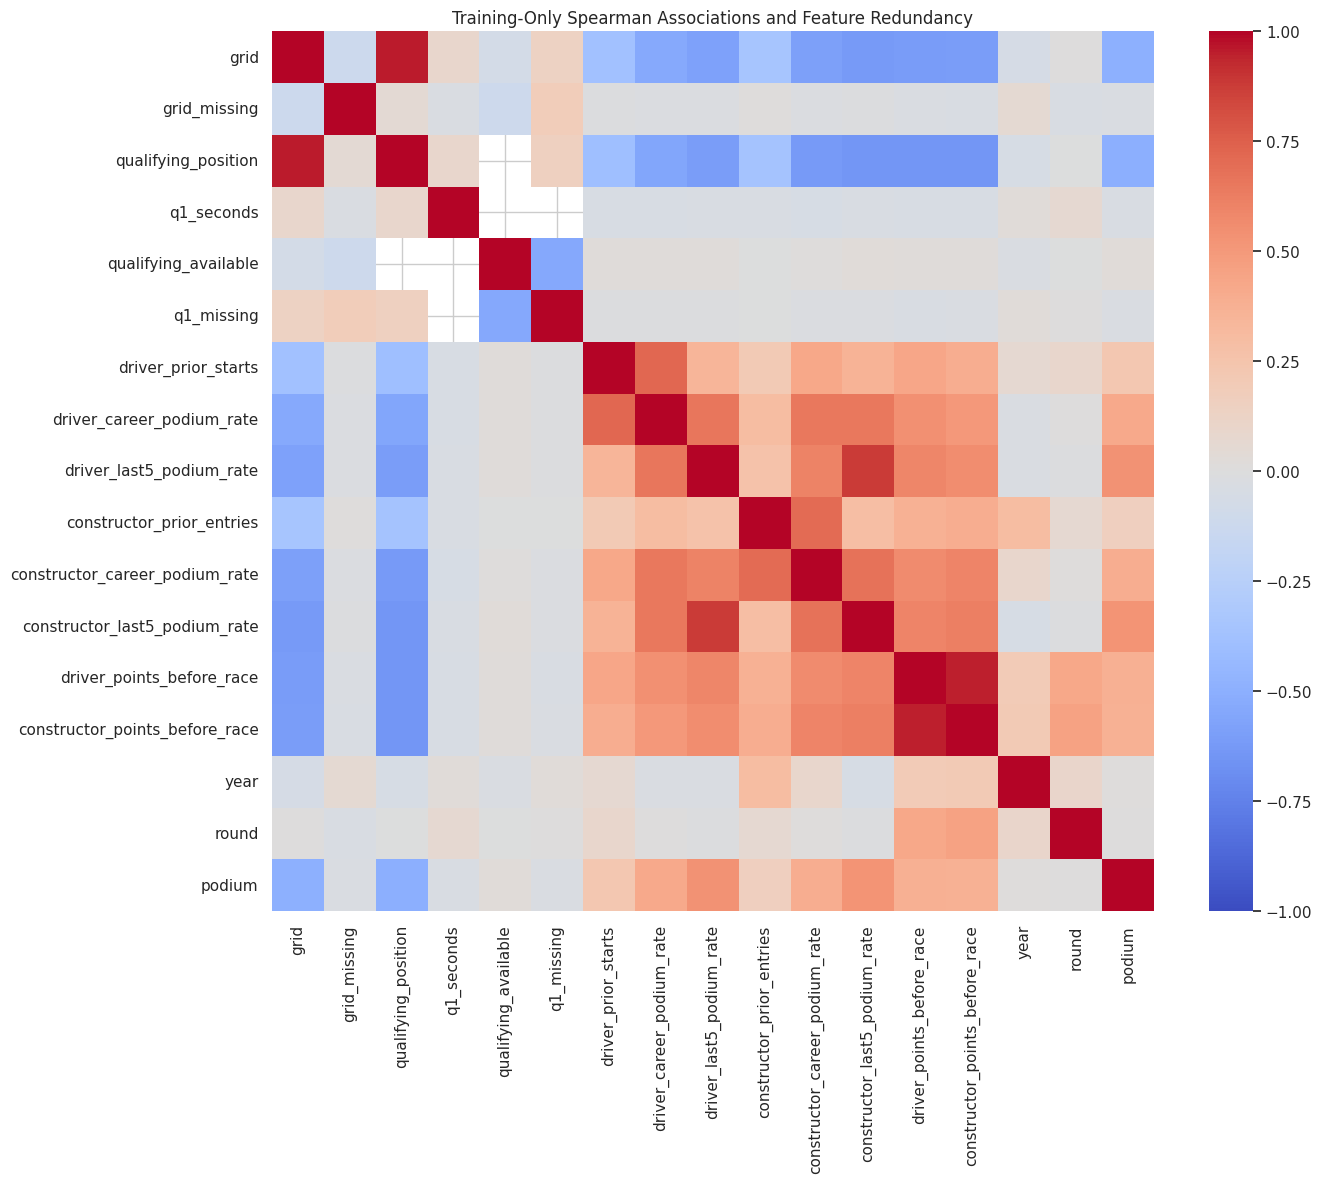

,Spearman with podium,Training missing (%)
grid,-0.495181,0.000000
grid_missing,-0.028571,0.000000
qualifying_position,-0.503470,0.398268
q1_seconds,-0.034159,1.333333
qualifying_available,0.025431,0.000000
q1_missing,-0.029307,0.000000
driver_prior_starts,0.228900,0.000000
driver_career_podium_rate,0.415512,1.021645
driver_last5_podium_rate,0.532834,1.021645
constructor_prior_entries,0.163025,0.000000


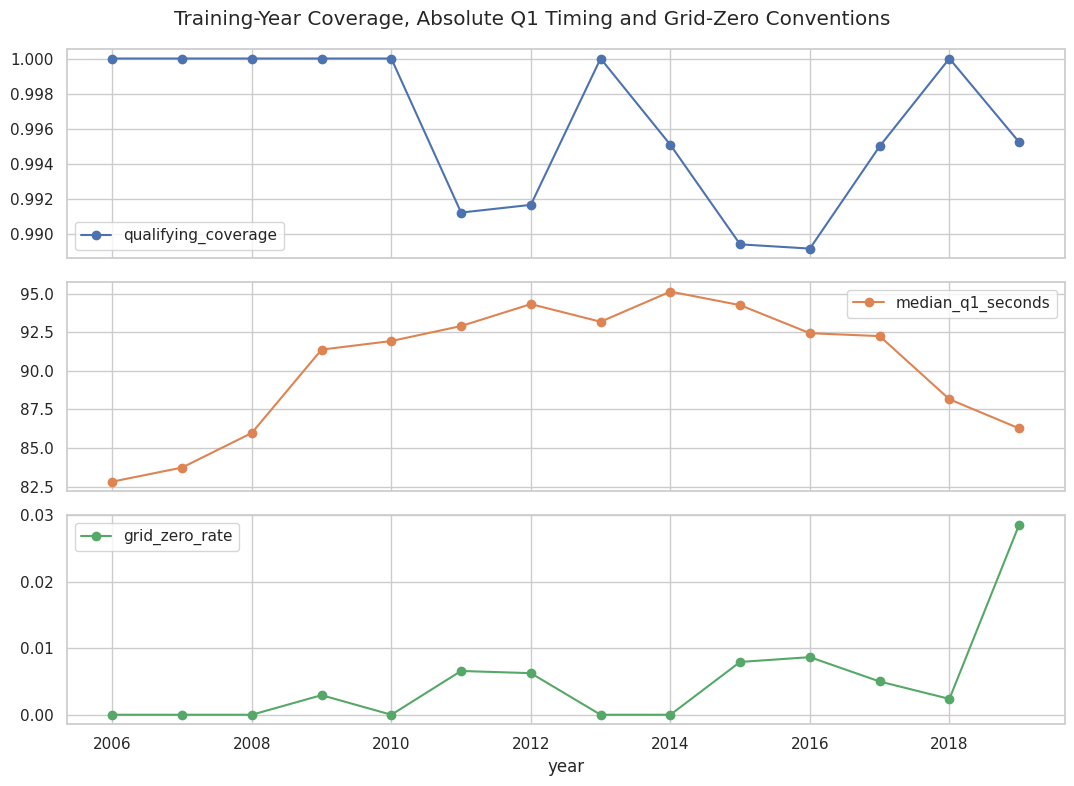

In [94]:
# Compare a few numerical features before and after scaling

selected_features = [
    "grid",
    "driver_prior_starts",
    "driver_points_before_race",
    "constructor_points_before_race"
]

scaled_train_df = pd.DataFrame(
    X_train_scaled,
    columns=feature_columns,
    index=X_train.index
)

fig, axes = plt.subplots(
    len(selected_features), 2,
    figsize=(12, 12)
)

for i, feature in enumerate(selected_features):
    sns.histplot(
        X_train[feature].dropna(),
        bins=35,
        ax=axes[i, 0]
    )

    axes[i, 0].set_title(f"Original: {feature}")

    sns.histplot(
        scaled_train_df[feature],
        bins=35,
        ax=axes[i, 1]
    )

    axes[i, 1].set_title(f"Preprocessed: {feature}")

plt.tight_layout()
plt.show()

# Training-only feature evidence; held-out outcomes are not used to justify choices.
feature_evidence = X_train.copy()
feature_evidence["podium"] = y_train
train_correlations = feature_evidence.corr(method="spearman")
plt.figure(figsize=(14, 12))
sns.heatmap(train_correlations, cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Training-Only Spearman Associations and Feature Redundancy")
plt.tight_layout()
plt.show()
display(pd.DataFrame({"Spearman with podium": train_correlations["podium"].drop("podium"), "Training missing (%)": X_train.isna().mean()*100}))
train_coverage = train_df.groupby("year").agg(qualifying_coverage=("qualifying_available", "mean"), median_q1_seconds=("q1_seconds", "median"), grid_zero_rate=("grid", lambda s: s.eq(0).mean()))
train_coverage.plot(subplots=True, figsize=(11, 8), marker="o")
plt.suptitle("Training-Year Coverage, Absolute Q1 Timing and Grid-Zero Conventions")
plt.tight_layout()
plt.show()


In [95]:

from sklearn.preprocessing import RobustScaler

preprocessing_experiments = {
    "A_Impute_Then_Scale": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]),

    "B_Scale_Then_Impute": Pipeline([
        ("scaler", StandardScaler()),
        ("imputer", SimpleImputer(strategy="median"))
    ]),

    "C_Impute_Then_RobustScale": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", RobustScaler())
    ])
}

preprocessing_outputs = {}

for name, pipeline in preprocessing_experiments.items():
    train_transformed = pipeline.fit_transform(X_train)
    val_transformed = pipeline.transform(X_val)

    assert np.isfinite(train_transformed).all()
    assert np.isfinite(val_transformed).all()

    preprocessing_outputs[name] = {
        "pipeline": pipeline,
        "train": train_transformed,
        "validation": val_transformed
    }

    print(
        name,
        "| Train:", train_transformed.shape,
        "| Validation:", val_transformed.shape
    )

print("\nAll three preprocessing pipelines executed.")


A_Impute_Then_Scale | Train: (5775, 16) | Validation: (780, 16)
B_Scale_Then_Impute | Train: (5775, 16) | Validation: (780, 16)
C_Impute_Then_RobustScale | Train: (5775, 16) | Validation: (780, 16)

All three preprocessing pipelines executed.


In [96]:

# FINAL PHASE 6 VALIDATION

assert X_train.columns.tolist() == X_val.columns.tolist()
assert X_train.columns.tolist() == X_test.columns.tolist()

assert "podium" not in X_train.columns
assert "positionOrder" not in X_train.columns
assert "points" not in X_train.columns
assert "statusId" not in X_train.columns

assert train_df["date"].max() < val_df["date"].min()
assert val_df["date"].max() < test_df["date"].min()

assert len(X_train) == len(y_train)
assert len(X_val) == len(y_val)
assert len(X_test) == len(y_test)

assert y_train.isin([0, 1]).all()
assert y_val.isin([0, 1]).all()
assert y_test.isin([0, 1]).all()

print("Phase 6 validation passed.")
print("Test data remains reserved for final evaluation.")


Phase 6 validation passed.
Test data remains reserved for final evaluation.


## Phase 7 — Three-Model Comparison

Three classifiers use the **same rows and same 16 features**: (1) **Logistic Regression** as the interpretable statistical baseline, (2) **Random Forest** with 200 trees and regularized tree depth/leaf size to learn nonlinear interactions, and (3) a **shallow feedforward neural network**, with Dense layers of 32 and 16 neurons and a sigmoid output. The network uses Adam, binary cross-entropy, dropout, and validation-loss early stopping. The maximum epoch count is 100 in the final training configuration; the actual training history records the observed number of epochs.

**Primary metric:** average precision (**PR-AUC**), appropriate for the roughly 13–15% positive-class prevalence. **Secondary metrics:** ROC-AUC and F1, with precision and recall for threshold-specific interpretation. Thresholds are chosen on validation predictions, not test predictions. We report train, validation, and later test metrics for all three models. Higher capacity alone does not guarantee better generalization.

The comparison's `PR-AUC` column is **average precision (AP)** from scikit-learn, rather than trapezoidal integration of the precision–recall curve. Keras training-history PR-AUC uses a different approximation, so those values are not interchangeable. Accuracy is supplementary only. Nine reports (three models × train/validation/test) are checked for all five required metrics, finite ranges and the same validation-selected threshold per model. The three required models constitute three distinct modeling attempts; the preserved preprocessing and ablation comparisons provide additional controlled attempts. Validation scores are also used for thresholds and early stopping, so they are development estimates rather than independent final estimates.


**Executed comparison.** Training, validation and test contain **5,775 / 780 / 1,359** rows respectively. The network trained for **35 epochs**, restored the best validation-loss weights from **epoch 25**, and remained the validation-AP winner (**0.7496**, threshold **0.28**). Logistic Regression and Random Forest validation AP were **0.7363** and **0.7315**, with thresholds **0.29** and **0.35**. All nine model/split reports include ROC-AUC, AP, F1, precision, recall and supplementary accuracy.


In [97]:

# PHASE 7 — Imports and configuration

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    f1_score,
    precision_score,
    recall_score,
    precision_recall_curve,
    roc_curve,
    confusion_matrix,
    ConfusionMatrixDisplay
)

tf.keras.utils.set_random_seed(42)

# Statistical baseline and Random Forest
models = {
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            max_iter=2000,
            random_state=42
        ))
    ]),

    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(
            n_estimators=200,
            max_depth=10,
            min_samples_leaf=5,
            n_jobs=-1,
            random_state=42
        ))
    ])
}

print("Models prepared:", list(models.keys()))


Models prepared: ['Logistic Regression', 'Random Forest']


In [98]:

# Train statistical ML models

trained_models = {}
model_probabilities = {}

for name, pipeline in models.items():

    print(f"\nTraining {name}...")

    pipeline.fit(X_train, y_train)

    trained_models[name] = pipeline

    model_probabilities[name] = {
        "Train": pipeline.predict_proba(X_train)[:, 1],
        "Validation": pipeline.predict_proba(X_val)[:, 1]
    }

    print(f"{name} training completed.")

print("\nBoth statistical models trained successfully.")



Training Logistic Regression...
Logistic Regression training completed.

Training Random Forest...
Random Forest training completed.

Both statistical models trained successfully.


In [99]:

# Build neural network

neural_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(len(feature_columns),)),

    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dropout(0.2),

    tf.keras.layers.Dense(16, activation="relu"),
    tf.keras.layers.Dropout(0.1),

    tf.keras.layers.Dense(1, activation="sigmoid")
])

neural_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.AUC(name="roc_auc"),
        tf.keras.metrics.AUC(
            curve="PR", name="pr_auc"
        )
    ]
)

neural_model.summary()


I0000 00:00:1792182373.354680      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792182373.359409      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,089 (4.25 KB)

 Trainable params: 1,089 (4.25 KB)

 Non-trainable params: 0 (0.00 B)

In [100]:

import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("CPUs:", tf.config.list_physical_devices("CPU"))
print("GPUs:", tf.config.list_physical_devices("GPU"))


TensorFlow version: 2.20.0
CPUs: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [101]:

# Train neural network using training-only preprocessing

X_train_nn = X_train_scaled.astype("float32")
X_val_nn = X_val_scaled.astype("float32")

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history_nn = neural_model.fit(
    X_train_nn,
    y_train.to_numpy(),
    validation_data=(
        X_val_nn,
        y_val.to_numpy()
    ),
    epochs=100,
    batch_size=64,
    callbacks=[early_stop],
    verbose=1
)

# Save probability predictions
model_probabilities["Neural Network"] = {
    "Train": neural_model.predict(
        X_train_nn, verbose=0
    ).ravel(),

    "Validation": neural_model.predict(
        X_val_nn, verbose=0
    ).ravel()
}

print("Neural network training completed.")

print("Maximum epochs: 100")
print("Actual epochs trained:",
      len(history_nn.history["loss"]))

print("Best epoch:",
      np.argmin(history_nn.history["val_loss"]) + 1)

print("Best validation loss:",
      min(history_nn.history["val_loss"]))



Epoch 1/100
66/91 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.5361 - pr_auc: 0.2533 - roc_auc: 0.6694

I0000 00:00:1792182380.111737      93 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


91/91 ━━━━━━━━━━━━━━━━━━━━ 10s 62ms/step - loss: 0.3962 - pr_auc: 0.3442 - roc_auc: 0.7883 - val_loss: 0.2767 - val_pr_auc: 0.6368 - val_roc_auc: 0.9005
Epoch 2/100
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.2509 - pr_auc: 0.5721 - roc_auc: 0.9081 - val_loss: 0.2502 - val_pr_auc: 0.6597 - val_roc_auc: 0.9106
Epoch 3/100
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.2390 - pr_auc: 0.6035 - roc_auc: 0.9152 - val_loss: 0.2485 - val_pr_auc: 0.6744 - val_roc_auc: 0.9112
Epoch 4/100
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.2387 - pr_auc: 0.6116 - roc_auc: 0.9149 - val_loss: 0.2475 - val_pr_auc: 0.6934 - val_roc_auc: 0.9126
Epoch 5/100
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.2321 - pr_auc: 0.6120 - roc_auc: 0.9211 - val_loss: 0.2481 - val_pr_auc: 0.7095 - val_roc_auc: 0.9147
Epoch 6/100
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.2329 - pr_auc: 0.6205 - roc_auc: 0.9197 - val_loss: 0.2465 - val_pr_auc: 0.7223 - val_roc_auc: 0.9157
Epoch 7/100
91/91 ━━━━━━━━━━━━━━

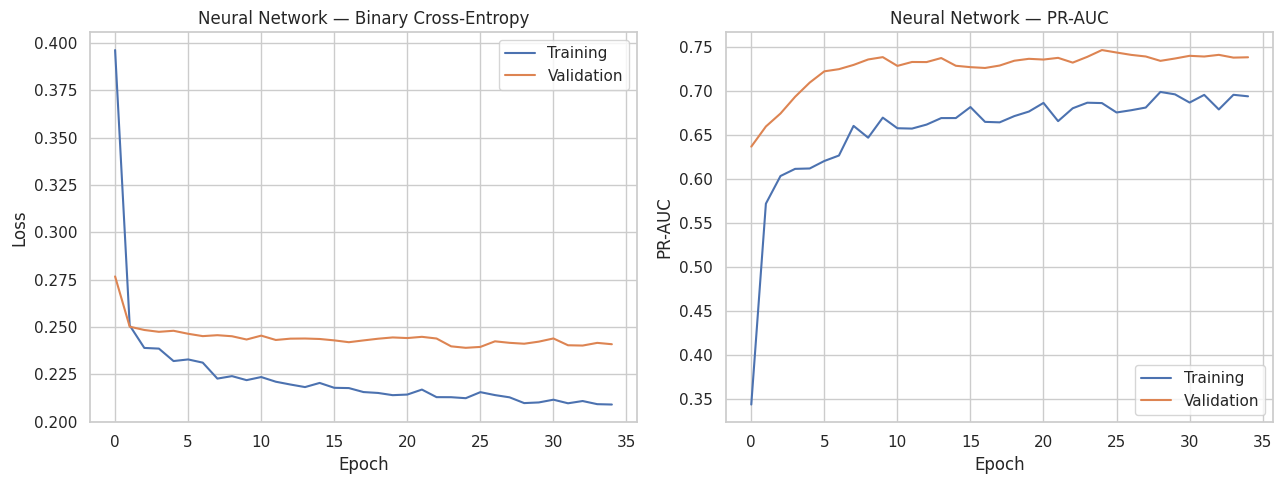

In [102]:

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(
    history_nn.history["loss"],
    label="Training"
)
axes[0].plot(
    history_nn.history["val_loss"],
    label="Validation"
)
axes[0].set_title("Neural Network — Binary Cross-Entropy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

axes[1].plot(
    history_nn.history["pr_auc"],
    label="Training"
)
axes[1].plot(
    history_nn.history["val_pr_auc"],
    label="Validation"
)
axes[1].set_title("Neural Network — PR-AUC")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("PR-AUC")
axes[1].legend()

plt.tight_layout()
plt.show()


In [103]:

from sklearn.metrics import f1_score

# Threshold search on validation only
threshold_grid = np.round(
    np.arange(0.05, 0.951, 0.01), 2
)

best_thresholds = {}

for name, predictions in model_probabilities.items():

    val_probs = predictions["Validation"]

    scores = [
        f1_score(
            y_val,
            (val_probs >= t).astype(int),
            zero_division=0
        )
        for t in threshold_grid
    ]

    best_index = int(np.argmax(scores))
    best_t = float(threshold_grid[best_index])

    best_thresholds[name] = best_t

    print(
        f"{name}: threshold={best_t:.2f}, "
        f"validation F1={scores[best_index]:.4f}"
    )


Logistic Regression: threshold=0.29, validation F1=0.7034
Random Forest: threshold=0.35, validation F1=0.6964
Neural Network: threshold=0.28, validation F1=0.7034


In [104]:
from sklearn.metrics import accuracy_score

def evaluate_predictions(y_true, probs, threshold):
    pred = (np.asarray(probs) >= threshold).astype(int)

    return {
        "Accuracy (supplementary)": accuracy_score(y_true, pred),
        "ROC-AUC": roc_auc_score(y_true, probs),
        "PR-AUC": average_precision_score(y_true, probs),
        "F1": f1_score(y_true, pred, zero_division=0),
        "Precision": precision_score(
            y_true, pred, zero_division=0
        ),
        "Recall": recall_score(
            y_true, pred, zero_division=0
        )
    }


evaluation_rows = []

for name, predictions in model_probabilities.items():
    threshold = best_thresholds[name]

    for split_name, y_true in [
        ("Train", y_train),
        ("Validation", y_val)
    ]:
        metrics = evaluate_predictions(
            y_true,
            predictions[split_name],
            threshold
        )

        evaluation_rows.append({
            "Model": name,
            "Split": split_name,
            "Threshold": threshold,
            **metrics
        })

model_comparison = pd.DataFrame(evaluation_rows)

display(
    model_comparison.sort_values(
        ["Split", "PR-AUC"],
        ascending=[True, False]
    ).round(4)
)


,Model,Split,Threshold,Accuracy (supplementary),ROC-AUC,PR-AUC,F1,Precision,Recall
2,Random Forest,Train,0.35,0.9385,0.9805,0.9019,0.7998,0.7317,0.8818
4,Neural Network,Train,0.28,0.8942,0.9437,0.7330,0.6875,0.5838,0.8358
0,Logistic Regression,Train,0.29,0.8965,0.9351,0.7002,0.6853,0.5940,0.8097
5,Neural Network,Validation,0.28,0.9103,0.9258,0.7496,0.7034,0.6975,0.7094
1,Logistic Regression,Validation,0.29,0.9103,0.9318,0.7363,0.7034,0.6975,0.7094
3,Random Forest,Validation,0.35,0.9038,0.9280,0.7315,0.6964,0.6615,0.7350


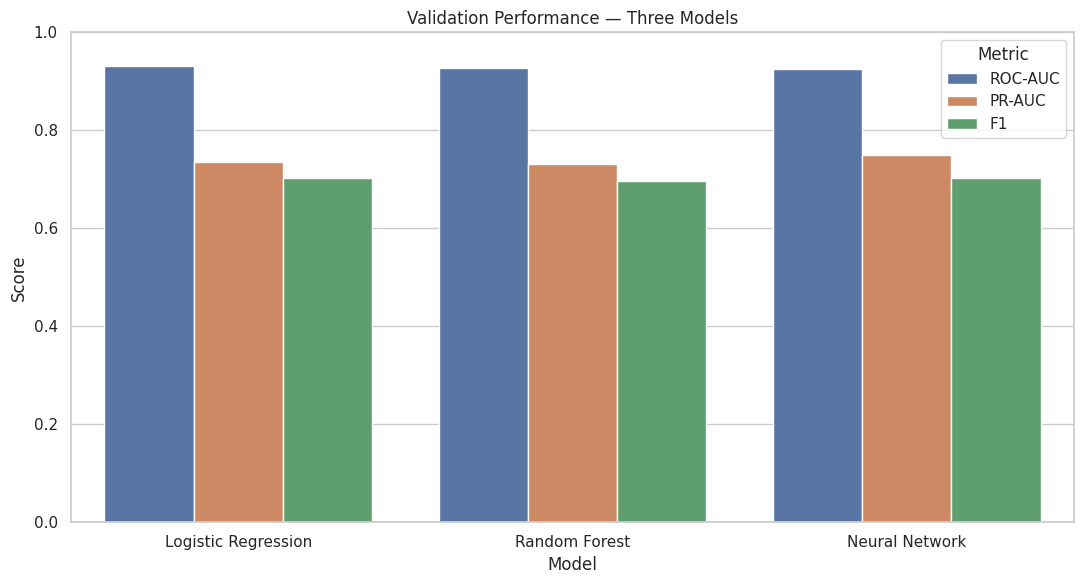

In [105]:

validation_results = model_comparison[
    model_comparison["Split"] == "Validation"
].copy()

comparison_long = validation_results.melt(
    id_vars="Model",
    value_vars=["ROC-AUC", "PR-AUC", "F1"],
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=comparison_long,
    x="Model",
    y="Score",
    hue="Metric"
)

plt.title("Validation Performance — Three Models")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


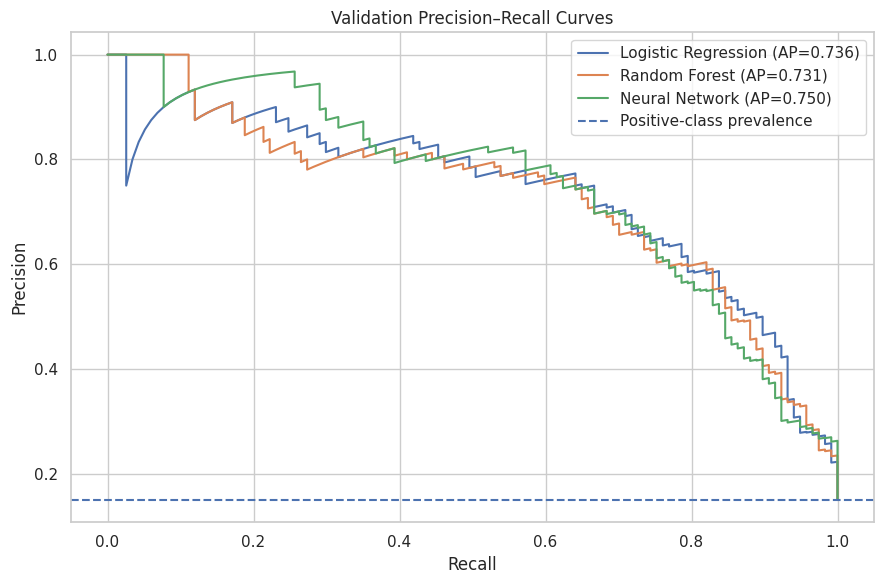

In [106]:

plt.figure(figsize=(9, 6))

for name, predictions in model_probabilities.items():
    probs = predictions["Validation"]

    precision, recall, _ = precision_recall_curve(
        y_val, probs
    )

    ap = average_precision_score(y_val, probs)

    plt.plot(
        recall,
        precision,
        label=f"{name} (AP={ap:.3f})"
    )

plt.axhline(
    y=y_val.mean(),
    linestyle="--",
    label="Positive-class prevalence"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Validation Precision–Recall Curves")
plt.legend()
plt.tight_layout()
plt.show()


In [107]:

ranking = (
    validation_results.sort_values(
        ["PR-AUC", "F1"],
        ascending=[False, False]
    )
    .reset_index(drop=True)
)

best_model_name = ranking.loc[0, "Model"]

print("Best validation model:", best_model_name)
print("Selected threshold:",
      best_thresholds[best_model_name])

display(ranking.round(4))


Best validation model: Neural Network
Selected threshold: 0.28


,Model,Split,Threshold,Accuracy (supplementary),ROC-AUC,PR-AUC,F1,Precision,Recall
0,Neural Network,Validation,0.28,0.9103,0.9258,0.7496,0.7034,0.6975,0.7094
1,Logistic Regression,Validation,0.29,0.9103,0.9318,0.7363,0.7034,0.6975,0.7094
2,Random Forest,Validation,0.35,0.9038,0.9280,0.7315,0.6964,0.6615,0.7350


In [108]:

import joblib
import json
from pathlib import Path

model_dir = Path("/kaggle/working/saved_models")
model_dir.mkdir(parents=True, exist_ok=True)

# Save statistical models including preprocessing
joblib.dump(
    trained_models["Logistic Regression"],
    model_dir / "logistic_regression.joblib"
)

joblib.dump(
    trained_models["Random Forest"],
    model_dir / "random_forest.joblib"
)

# Save neural network
neural_model.save(
    model_dir / "neural_network.keras"
)

# Neural network preprocessing
joblib.dump(
    standard_preprocessor,
    model_dir / "neural_preprocessor.joblib"
)

# Save model input columns and thresholds
metadata = {
    "feature_columns": feature_columns,
    "thresholds": {
        name: float(value)
        for name, value in best_thresholds.items()
    },
    "validation_selected_model": best_model_name
}

with open(model_dir / "metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)

print("Saved model files:")
for file in model_dir.iterdir():
    print(file.name, "-", round(file.stat().st_size / 1024, 2), "KB")


Saved model files:
metadata.json - 0.59 KB
neural_preprocessor.joblib - 2.03 KB
random_forest.joblib - 4831.69 KB
neural_network.keras - 42.46 KB
logistic_regression.joblib - 2.75 KB


In [109]:
# FINAL TEST EVALUATION
# Model and threshold selection used Phase 7 validation data only.
# Phase 8 experiments are exploratory; the test set was inspected beforehand.

final_test_predictions = {}

for name in trained_models:
    final_test_predictions[name] = (
        trained_models[name]
        .predict_proba(X_test)[:, 1]
    )

final_test_predictions["Neural Network"] = (
    neural_model.predict(
        standard_preprocessor.transform(X_test).astype("float32"),
        verbose=0
    ).ravel()
)

test_rows = []

for name, probs in final_test_predictions.items():
    test_rows.append({
        "Model": name,
        "Split": "Test",
        "Threshold": best_thresholds[name],
        **evaluate_predictions(
            y_test, probs, best_thresholds[name]
        )
    })

test_results = pd.DataFrame(test_rows)

display(test_results.round(4))

# Coverage checks use existing predictions; no model or threshold is reselected.
required_metrics = ["ROC-AUC", "PR-AUC", "F1", "Precision", "Recall", "Accuracy (supplementary)"]
all_model_metrics = pd.concat([model_comparison, test_results], ignore_index=True)
expected_models = {"Logistic Regression", "Random Forest", "Neural Network"}
assert set(all_model_metrics["Model"]) == expected_models
assert not all_model_metrics.duplicated(["Model", "Split"]).any()
assert len(all_model_metrics) == 9
assert all_model_metrics[required_metrics].notna().all().all()
assert all_model_metrics[required_metrics].ge(0).all().all() and all_model_metrics[required_metrics].le(1).all().all()
for name in expected_models:
    assert set(all_model_metrics.loc[all_model_metrics["Model"].eq(name), "Split"]) == {"Train", "Validation", "Test"}
    assert all_model_metrics.loc[all_model_metrics["Model"].eq(name), "Threshold"].eq(best_thresholds[name]).all()
assert best_model_name == ranking.loc[0, "Model"]
print("All three models have five required metrics plus supplementary accuracy on all three splits.")
print("PR-AUC in the comparison tables is average precision (AP), not trapezoidal PR integration; Keras training PR-AUC is a different numerical approximation.")


,Model,Split,Threshold,Accuracy (supplementary),ROC-AUC,PR-AUC,F1,Precision,Recall
0,Logistic Regression,Test,0.29,0.8999,0.9347,0.7063,0.6808,0.6532,0.7108
1,Random Forest,Test,0.35,0.8793,0.9314,0.6655,0.6555,0.5735,0.7647
2,Neural Network,Test,0.28,0.8882,0.9299,0.6847,0.6381,0.6204,0.6569


All three models have five required metrics plus supplementary accuracy on all three splits.
PR-AUC in the comparison tables is average precision (AP), not trapezoidal PR integration; Keras training PR-AUC is a different numerical approximation.


### Phase 7 — Results and Generalization

**Verification status:** Numerical statements were reconciled with the successful clean saved execution (Version 13, 16 October 2026). Audit results, statistical tables and plotted outputs provide the evidence; predictive associations do not establish causation.

The **validation-based selection** preferred the **Neural Network** by PR-AUC, using an approximately **0.28** probability threshold selected to optimize validation F1. On the previously reported 2022–2024 test evaluation, **Logistic Regression** had the strongest metrics: **ROC-AUC 0.9347, PR-AUC 0.7063, F1 0.6808**, versus **Random Forest** (0.9314, 0.6655, 0.6555) and **Neural Network** (0.9299, 0.6847, 0.6381).

The neural network's training loss continued decreasing while validation loss flattened, consistent with mild overfitting and motivating early stopping. The chosen model remains the validation AP winner, with validation F1 as the tie-breaker. A better test score does not change that selection; doing so would contaminate model selection with test information. The test was inspected before subsequent ablation experiments, so these later experiments are reported as exploratory validation analyses and not as independently test-confirmed improvements.


## Phase 8 — Preprocessing Experiments and Feature-Group Ablation

A fixed Logistic Regression classifier is trained from scratch under three preprocessing configurations on the same chronological training/validation observations. All pipelines fit their imputer and scaler using **training data only**. The comparison is evaluated using validation PR-AUC, ROC-AUC, and F1. For a fixed increasing affine transform, the transformed median equals the median of transformed observations. However, StandardScaler fitted after imputation uses a different mean/variance from fitting it while ignoring missing values. The complete fitted pipelines therefore need not be identical, and regularized Logistic Regression can respond to the changed scale. Similar AP is not proof of mathematical identity. Robust scaling in configuration C changes the scaling rule and is not a second order reversal.

A second controlled experiment reverses **training-quantile capping and median imputation**, retaining standard scaling and the same Logistic Regression, feature set and rows. Capping uses training-fitted 1st/99th percentiles only for continuous timing/exposure/points features. Imputed mass can change the fitted quantiles, so order can change caps and transformed distributions; where statistics coincide, results can be equivalent. No improvement is assumed. Both experiments display transformed values, per-feature distributions, probability differences and validation metrics. The executed comparisons and transformed distributions are shown below. The experiments remain exploratory and do not revise the frozen Phase 7 selection.

In the **feature-group ablation**, six variants remove one of the following groups at a time: **grid, qualifying, driver form, constructor form, standings, race context**. Each model is retrained and compared to the complete 16-feature baseline. A positive PR-AUC drop indicates that removing the group hurt this model on validation; a negative drop indicates a slight improvement without it. This is predictive reliance, not causality.


In [110]:

# PHASE 8 — Common experiment setup

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    f1_score
)

# Reuse the chronological training/validation partitions
assert X_train.columns.tolist() == X_val.columns.tolist()

threshold_grid_exp = np.arange(0.05, 0.951, 0.01)

def evaluate_experiment(y_true, probabilities):
    probabilities = np.asarray(probabilities).ravel()

    f1_values = [
        f1_score(
            y_true,
            probabilities >= threshold,
            zero_division=0
        )
        for threshold in threshold_grid_exp
    ]

    best_index = int(np.argmax(f1_values))

    return {
        "ROC-AUC": roc_auc_score(y_true, probabilities),
        "PR-AUC": average_precision_score(
            y_true, probabilities
        ),
        "F1": f1_values[best_index],
        "Threshold": float(threshold_grid_exp[best_index])
    }

print("Phase 8 experimental functions ready.")


Phase 8 experimental functions ready.


In [111]:

# EXPERIMENT 1 — Preprocessing comparison

preprocessing_experiments = {
    "A: Impute → StandardScale": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]),

    "B: StandardScale → Impute": Pipeline([
        ("scaler", StandardScaler()),
        ("imputer", SimpleImputer(strategy="median"))
    ]),

    "C: Impute → RobustScale": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", RobustScaler())
    ])
}

preprocessing_results = []
preprocessing_fitted_models = {}

for name, preprocessor in preprocessing_experiments.items():

    experiment_model = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(
            max_iter=2000,
            random_state=42
        ))
    ])

    # Fit only on the training partition
    experiment_model.fit(X_train, y_train)

    val_probs = experiment_model.predict_proba(
        X_val
    )[:, 1]

    metrics = evaluate_experiment(
        y_val, val_probs
    )

    preprocessing_results.append({
        "Preprocessing": name,
        **metrics
    })

    preprocessing_fitted_models[name] = experiment_model

preprocessing_results = pd.DataFrame(
    preprocessing_results
)

display(
    preprocessing_results.sort_values(
        "PR-AUC", ascending=False
    ).round(4)
)


,Preprocessing,ROC-AUC,PR-AUC,F1,Threshold
1,B: StandardScale → Impute,0.9319,0.7371,0.7034,0.29
0,A: Impute → StandardScale,0.9318,0.7363,0.7034,0.29
2,C: Impute → RobustScale,0.9288,0.7311,0.7059,0.43


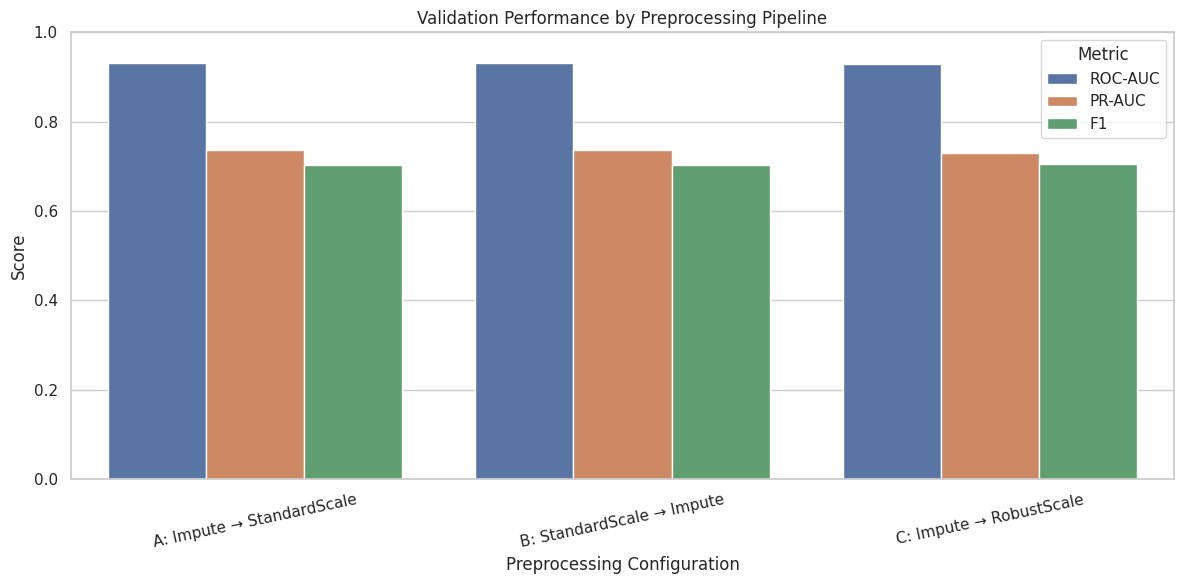

In [112]:

preprocessing_plot = preprocessing_results.melt(
    id_vars="Preprocessing",
    value_vars=["ROC-AUC", "PR-AUC", "F1"],
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=preprocessing_plot,
    x="Preprocessing",
    y="Score",
    hue="Metric"
)

plt.title("Validation Performance by Preprocessing Pipeline")
plt.ylabel("Score")
plt.xlabel("Preprocessing Configuration")
plt.ylim(0, 1)
plt.xticks(rotation=12)
plt.tight_layout()
plt.show()


In [113]:

# EXPERIMENT 2 — Feature-group ablation
# Use the same preprocessing and Logistic Regression
# across all ablation runs.

ablation_results = []
ablation_models = {}

ablation_groups = {
    "Full model": feature_columns
}

for group_name, columns_to_remove in feature_groups.items():
    remaining = [
        col for col in feature_columns
        if col not in columns_to_remove
    ]

    ablation_groups[f"Without {group_name}"] = remaining

for experiment_name, selected_features in ablation_groups.items():

    ablation_model = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            max_iter=2000,
            random_state=42
        ))
    ])

    ablation_model.fit(
        X_train[selected_features],
        y_train
    )

    val_probs = ablation_model.predict_proba(
        X_val[selected_features]
    )[:, 1]

    metrics = evaluate_experiment(
        y_val, val_probs
    )

    ablation_results.append({
        "Experiment": experiment_name,
        "Features": len(selected_features),
        **metrics
    })

    ablation_models[experiment_name] = ablation_model

ablation_results = pd.DataFrame(ablation_results)

baseline_pr_auc = ablation_results.loc[
    ablation_results["Experiment"] == "Full model",
    "PR-AUC"
].iloc[0]

ablation_results["PR-AUC Drop"] = (
    baseline_pr_auc - ablation_results["PR-AUC"]
)

display(
    ablation_results.sort_values(
        "PR-AUC Drop", ascending=False
    ).round(4)
)


,Experiment,Features,ROC-AUC,PR-AUC,F1,Threshold,PR-AUC Drop
1,Without grid,14,0.9295,0.7239,0.7089,0.28,0.0123
5,Without standings,14,0.9315,0.7252,0.7059,0.49,0.0110
2,Without qualifying,12,0.9240,0.7260,0.7054,0.25,0.0102
6,Without race_context,14,0.9318,0.7339,0.7078,0.30,0.0024
0,Full model,16,0.9318,0.7363,0.7034,0.29,0.0000
3,Without driver_form,13,0.9308,0.7363,0.7102,0.25,-0.0001
4,Without constructor_form,13,0.9320,0.7393,0.7029,0.27,-0.0031


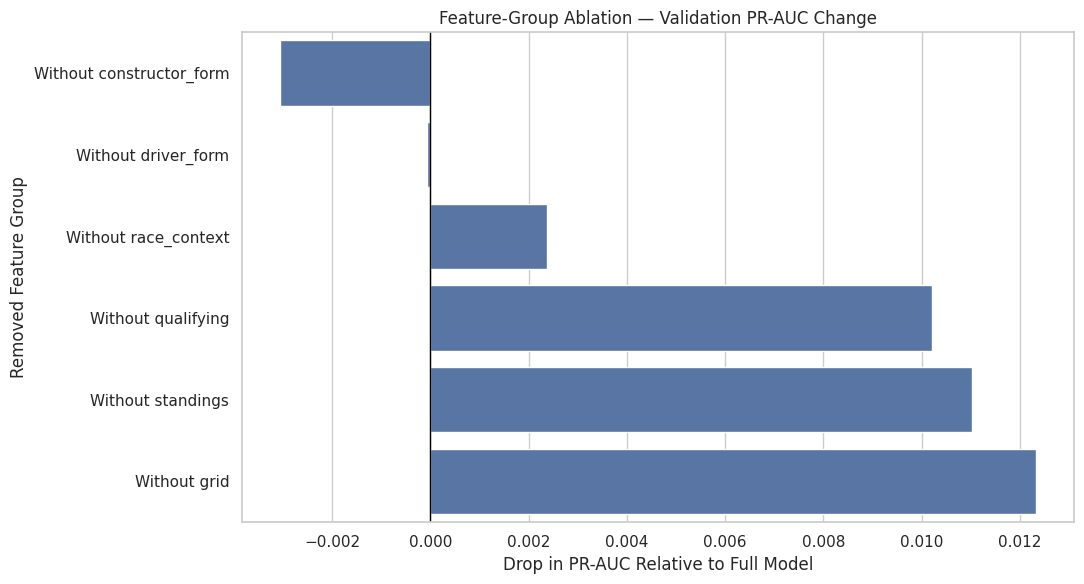

In [114]:

ablation_plot = (
    ablation_results[
        ablation_results["Experiment"] != "Full model"
    ]
    .sort_values("PR-AUC Drop")
)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=ablation_plot,
    x="PR-AUC Drop",
    y="Experiment"
)

plt.axvline(0, color="black", linewidth=1)

plt.title("Feature-Group Ablation — Validation PR-AUC Change")
plt.xlabel("Drop in PR-AUC Relative to Full Model")
plt.ylabel("Removed Feature Group")
plt.tight_layout()
plt.show()


In [115]:

# Ensure all six feature groups were tested
assert len(ablation_results) == len(feature_groups) + 1

# Ensure exactly three preprocessing experiments
assert len(preprocessing_results) == 3

# Verify metric values
for table in [preprocessing_results, ablation_results]:
    for metric in ["ROC-AUC", "PR-AUC", "F1"]:
        assert table[metric].between(0, 1).all()

# Verify feature-group coverage
assert set(feature_columns) == set(
    col
    for columns in feature_groups.values()
    for col in columns
)

# Confirm test data was not used
print("All experiments used X_train, X_val, y_train and y_val.")
print("No test data was used in Phase 8.")
print("Phase 8 structural validation passed.")


All experiments used X_train, X_val, y_train and y_val.
No test data was used in Phase 8.
Phase 8 structural validation passed.


Experiment tables exported successfully.


,Preprocessing,ROC-AUC,PR-AUC,F1,Threshold
0,D: Impute → Cap → Scale,0.931327,0.726222,0.702703,0.43
1,E: Cap → Impute → Scale,0.931327,0.726222,0.702703,0.43


,Order,Feature,Mean,Std,Min,Median,Max
0,A: Impute → StandardScale,grid,-0.175062,0.924279,-1.774514,-0.195108,1.384298
1,A: Impute → StandardScale,grid_missing,0.237294,2.065676,-0.071042,-0.071042,14.076148
2,A: Impute → StandardScale,qualifying_position,-0.127614,0.916609,-1.638529,-0.125777,1.386976
3,A: Impute → StandardScale,q1_seconds,-0.473787,1.190049,-2.975223,-0.672442,4.249215
4,A: Impute → StandardScale,qualifying_available,0.042879,0.568137,-15.814138,0.063235,0.063235
5,A: Impute → StandardScale,q1_missing,-0.015649,0.931106,-0.116248,-0.116248,8.602325
6,A: Impute → StandardScale,driver_prior_starts,0.307853,1.180600,-1.167416,-0.040595,3.108414
7,A: Impute → StandardScale,driver_career_podium_rate,0.084431,1.060853,-0.757807,-0.534505,2.927032
8,A: Impute → StandardScale,driver_last5_podium_rate,0.040787,1.029502,-0.551564,-0.551564,3.417801
9,A: Impute → StandardScale,constructor_prior_entries,0.238112,1.204706,-0.965933,-0.215643,2.679932


grid  grid_missing  \
Order                     Validation index                           
A: Impute → StandardScale 24529            -0.984811     -0.071042   
                          24530             1.226357     -0.071042   
                          24531            -0.037167     -0.071042   
                          24532             0.594595     -0.071042   
                          24533            -0.826870     -0.071042   
B: StandardScale → Impute 24529            -0.984811     -0.071042   
                          24530             1.226357     -0.071042   
                          24531            -0.037167     -0.071042   
                          24532             0.594595     -0.071042   
                          24533            -0.826870     -0.071042   
D: Impute → Cap → Scale   24529            -0.984811     -0.071042   
                          24530             1.226357     -0.071042   
                          24531            -0.037167     -0.071042   
                          24532             0.594595     -0.071042   
                          24533            -0.826870     -0.071042   
E: Cap → Impute → Scale   24529            -0.984811     -0.071042   
                          24530             1.226357     -0.071042   
                          24531            -0.037167     -0.071042   
                          24532             0.594595     -0.071042   
                          24533            -0.826870     -0.071042   

                                            qualifying_position  q1_seconds  \
Order                     Validation index                                    
A: Impute → StandardScale 24529                       -1.479292   -2.127305   
                          24530                        1.227738   -2.042793   
                          24531                       -0.046158   -2.097981   
                          24532                        0.590790   -2.053501   
                          24533                       -0.842343   -2.098887   
B: StandardScale → Impute 24529                       -1.476533   -2.113093   
                          24530                        1.225112   -2.029147   
                          24531                       -0.046250   -2.083966   
                          24532                        0.589431   -2.039783   
                          24533                       -0.840852   -2.084866   
D: Impute → Cap → Scale   24529                       -1.479292   -1.955924   
                          24530                        1.227738   -1.955924   
                          24531                       -0.046158   -1.955924   
                          24532                        0.590790   -1.955924   
                          24533                       -0.842343   -1.955924   
E: Cap → Impute → Scale   24529                       -1.479292   -1.960283   
                          24530                        1.227738   -1.960283   
                          24531                       -0.046158   -1.960283   
                          24532                        0.590790   -1.960283   
                          24533                       -0.842343   -1.960283   

                                            qualifying_available  q1_missing  \
Order                     Validation index                                     
A: Impute → StandardScale 24529                         0.063235   -0.116248   
                          24530                         0.063235   -0.116248   
                          24531                         0.063235   -0.116248   
                          24532                         0.063235   -0.116248   
                          24533                         0.063235   -0.116248   
B: StandardScale → Impute 24529                         0.063235   -0.116248   
                          24530                         0.063235   -0.116248   
                          24531                 

,Experiment,Max absolute transformed difference,Max absolute probability difference,Probabilities equal at tolerance 1e-6
0,Median/standard-scale reversal,0.028441,0.002941,False
1,Median/capping reversal,0.004359,0.000012,False


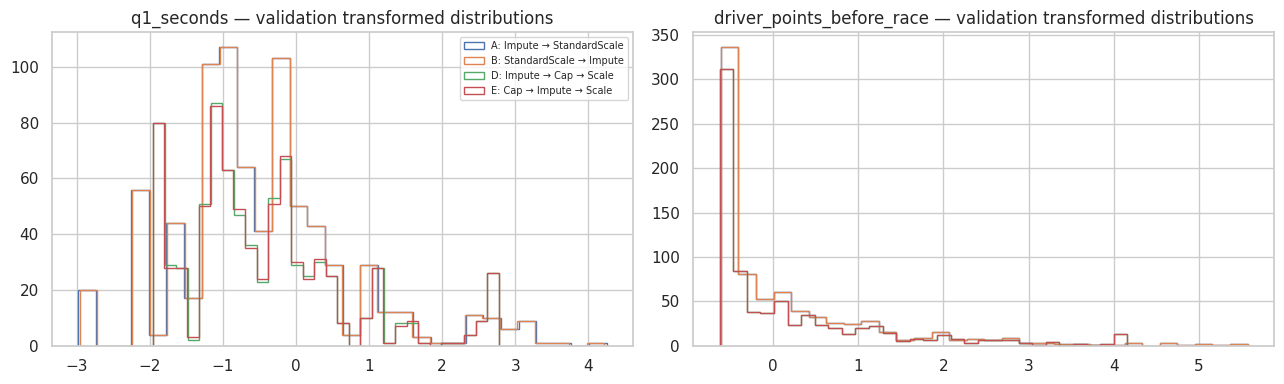

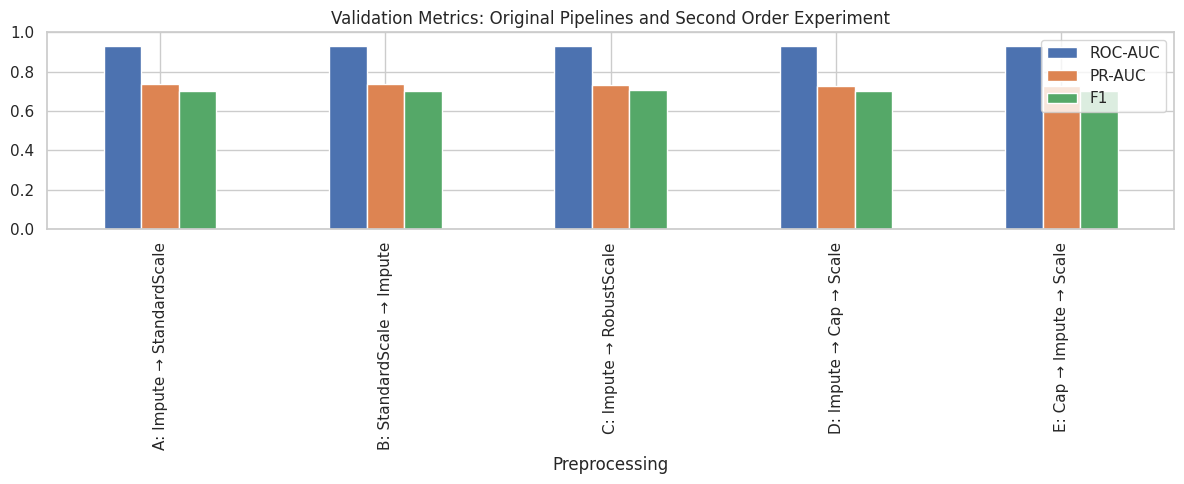

No test data entered either experiment; no gain is assumed and selected models/features/thresholds remain unchanged.


In [116]:
from pathlib import Path

experiment_dir = Path(
    "/kaggle/working/phase8_experiments"
)
experiment_dir.mkdir(parents=True, exist_ok=True)

preprocessing_results.to_csv(
    experiment_dir / "preprocessing_comparison.csv",
    index=False
)

ablation_results.to_csv(
    experiment_dir / "feature_ablation.csv",
    index=False
)

print("Experiment tables exported successfully.")

# SECOND PREPROCESSING-ORDER EXPERIMENT — quantile capping vs median imputation.
# Same rows, 16 features, StandardScaler and Logistic Regression as Experiment 1.
# Train-fitted 1st/99th percentile capping limits extreme continuous magnitudes.
# Imputation changes empirical quantile mass, so the learned caps can differ by order.
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.base import clone

class TrainingQuantileCapper(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        a = np.asarray(X, dtype=float)
        self.n_features_in_ = a.shape[1]
        self.cap_columns_ = [feature_columns.index(c) for c in [
            "q1_seconds", "driver_prior_starts", "constructor_prior_entries",
            "driver_points_before_race", "constructor_points_before_race"]]
        self.lower_ = np.nanquantile(a[:, self.cap_columns_], 0.01, axis=0)
        self.upper_ = np.nanquantile(a[:, self.cap_columns_], 0.99, axis=0)
        return self
    def transform(self, X):
        a = np.asarray(X, dtype=float).copy()
        assert a.shape[1] == self.n_features_in_
        a[:, self.cap_columns_] = np.clip(a[:, self.cap_columns_], self.lower_, self.upper_)
        return a

second_order_preprocessors = {
    "D: Impute → Cap → Scale": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("capper", TrainingQuantileCapper()), ("scaler", StandardScaler())]),
    "E: Cap → Impute → Scale": Pipeline([
        ("capper", TrainingQuantileCapper()),
        ("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())])
}
second_order_models = {}
second_order_rows = []
for name, preprocessor in second_order_preprocessors.items():
    model = Pipeline([("preprocessor", clone(preprocessor)),
                      ("classifier", LogisticRegression(max_iter=2000, random_state=42))])
    model.fit(X_train, y_train)
    second_order_models[name] = model
    second_order_rows.append({"Preprocessing": name, **evaluate_experiment(y_val, model.predict_proba(X_val)[:, 1])})
second_order_results = pd.DataFrame(second_order_rows)
display(second_order_results.round(6))

# Show actual transformed validation values and distribution summaries for BOTH orders.
order_models = {name: preprocessing_fitted_models[name] for name in list(preprocessing_fitted_models)[:2]}
order_models.update(second_order_models)
order_transformed = {}
order_distribution_rows = []
for name, model in order_models.items():
    transformed = model.named_steps["preprocessor"].transform(X_val)
    assert transformed.shape == X_val.shape and np.isfinite(transformed).all()
    order_transformed[name] = transformed
    for j, feature in enumerate(feature_columns):
        v = transformed[:, j]
        order_distribution_rows.append({"Order": name, "Feature": feature, "Mean": v.mean(),
            "Std": v.std(), "Min": v.min(), "Median": np.median(v), "Max": v.max()})
order_distributions = pd.DataFrame(order_distribution_rows)
display(order_distributions)
order_value_examples = pd.concat({name: pd.DataFrame(a[:5], columns=feature_columns, index=X_val.index[:5]) for name, a in order_transformed.items()}, names=["Order", "Validation index"])
display(order_value_examples)
order_equivalence_rows = []
names = list(order_models)
for label, left, right in [("Median/standard-scale reversal", names[0], names[1]), ("Median/capping reversal", names[2], names[3])]:
    p_left = order_models[left].predict_proba(X_val)[:, 1]
    p_right = order_models[right].predict_proba(X_val)[:, 1]
    order_equivalence_rows.append({"Experiment": label,
        "Max absolute transformed difference": np.max(np.abs(order_transformed[left]-order_transformed[right])),
        "Max absolute probability difference": np.max(np.abs(p_left-p_right)),
        "Probabilities equal at tolerance 1e-6": np.allclose(p_left, p_right, atol=1e-6, rtol=0)})
order_equivalence = pd.DataFrame(order_equivalence_rows)
display(order_equivalence)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name, transformed in order_transformed.items():
    for ax, feature in zip(axes, ["q1_seconds", "driver_points_before_race"]):
        ax.hist(transformed[:, feature_columns.index(feature)], bins=30, histtype="step", label=name)
        ax.set_title(feature + " — validation transformed distributions")
axes[0].legend(fontsize=7)
plt.tight_layout()
plt.show()
pd.concat([preprocessing_results, second_order_results]).set_index("Preprocessing")[["ROC-AUC", "PR-AUC", "F1"]].plot.bar(figsize=(12, 5), ylim=(0, 1))
plt.title("Validation Metrics: Original Pipelines and Second Order Experiment")
plt.tight_layout()
plt.show()
print("No test data entered either experiment; no gain is assumed and selected models/features/thresholds remain unchanged.")


### Phase 8 — Experimental Results

**Verification status:** Numerical statements were reconciled with the successful clean saved execution (Version 13, 16 October 2026). Audit results, statistical tables and plotted outputs provide the evidence; predictive associations do not establish causation.

The three preprocessing approaches achieved very similar validation average precision (approximately **0.73**), so the simpler median-imputation → StandardScaler configuration remains the reference pipeline.

The strongest ablation performance losses followed removal of **grid**, **pre-race standings**, and **qualifying** (approximately **0.010–0.012** PR-AUC each), while removal of driver form made little difference. Removing constructor form slightly improved validation PR-AUC, potentially because its information is correlated with standings, grid, or driver features. These effects apply to this Logistic Regression model and validation period, not necessarily to every model or season.

The ablation trials were performed without additional test fitting. Because the earlier test set had already been evaluated, these are **exploratory validation findings** and cannot support a fresh untouched-test performance claim.

The new capping/imputation orders both produced validation **ROC-AUC 0.931327, AP 0.726222 and F1 0.702703**, rounded to six decimals. They did not improve AP over reference A (**0.7363**). Their transformed validation values differ by at most **0.004359** and probabilities by about **0.000012**. In the original median/standard-scaling reversal, the corresponding maximum differences were **0.028441** and **0.002941**. Neither pair is identical at the specified probability tolerance of 1e-6, even though the capping-order metrics agree at the displayed precision. Similar aggregate scores do not imply identical transformations. Original preprocessing and ablation tables remain separate, and the frozen Phase 7 model selection is unchanged.


## Phase 9 — Explainable AI: Global and Local Explanations

Global **permutation importance** shuffles one predictor at a time on validation observations and measures the resulting change in average precision. Global **SHAP** attributes fitted model output to features, and a local SHAP waterfall explains one individual validation prediction. Both methods are computed for the fitted **Logistic Regression** baseline, not the neural network. SHAP values in this setting represent **log-odds**, not probability percentage points.

The plots should be interpreted together: correlated features can produce different rankings across SHAP and permutation importance. Attributions describe model reliance; **they do not prove causal effects on Formula 1 podiums**.

A bounded LIME local surrogate (1,500 perturbations) is plotted for the **same validation record** as the local SHAP waterfall, using the same Logistic Regression and its fitted preprocessing. Binary availability flags are treated categorically. The displayed table compares local probability-surrogate weights with SHAP log-odds contributions, reports top-five overlap and LIME surrogate fidelity. LIME estimates a local response slope; SHAP measures displacement from a background. Their signs need not agree when a feature's observed value is below its reference, and magnitudes have different units. Correlation and off-manifold perturbations add uncertainty. The executed example is **driverId 1, raceId 1037**, with Logistic Regression podium probability **0.8940**. LIME and local SHAP share **grid and qualifying position** in their top five absolute attributions; LIME's weighted local surrogate R² is **0.8082**. For this record, increasing numerical grid/qualifying position has negative LIME weights, while the observed strong positions have positive SHAP contributions relative to the background. These statements are compatible because a local response weight and displacement from a reference answer different questions. LIME gives substantial weight to availability flags whose actual-record SHAP contributions can be near zero; independent perturbations can create unrealistic combinations, so this does not establish those flags as reliable global drivers. These explanations describe **model reliance and do not establish causation**.


,Feature,Importance,Std
2,qualifying_position,0.1219,0.0383
0,grid,0.1128,0.0472
5,q1_missing,0.0384,0.0157
12,driver_points_before_race,0.0367,0.0223
1,grid_missing,0.0342,0.0112
15,round,0.0117,0.0069
10,constructor_career_podium_rate,0.0100,0.0076
8,driver_last5_podium_rate,0.0085,0.0109
3,q1_seconds,0.0011,0.0021
9,constructor_prior_entries,0.0004,0.0041


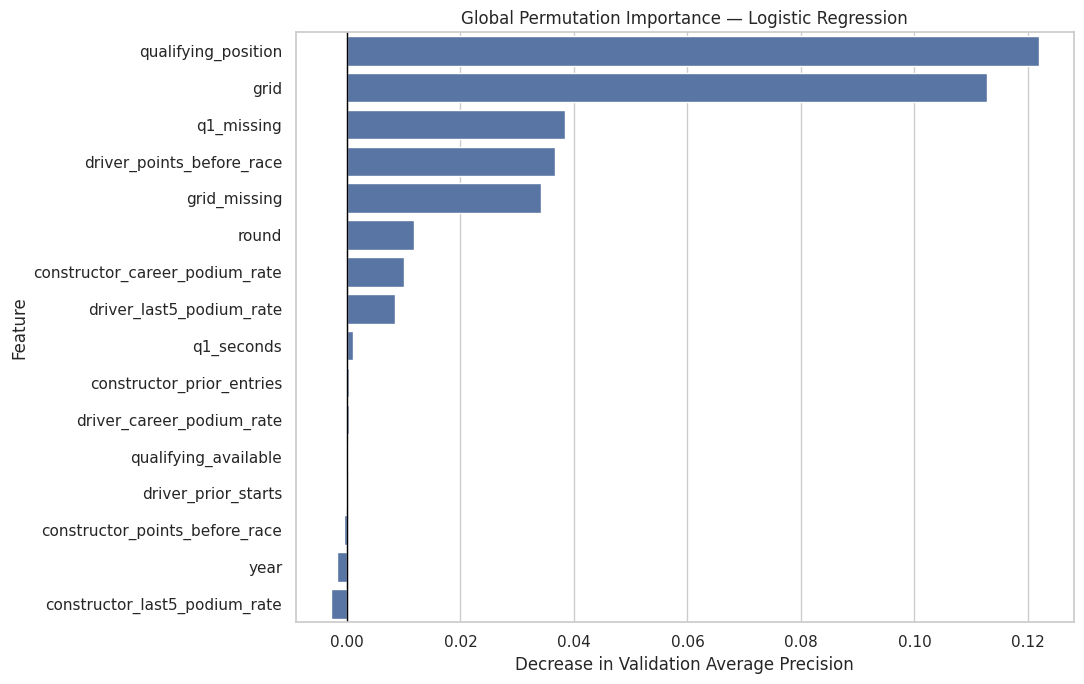

In [117]:

from sklearn.inspection import permutation_importance
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Explain the already-trained Logistic Regression model
explain_model = trained_models["Logistic Regression"]

permutation_result = permutation_importance(
    explain_model,
    X_val,
    y_val,
    scoring="average_precision",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

permutation_df = pd.DataFrame({
    "Feature": feature_columns,
    "Importance": permutation_result.importances_mean,
    "Std": permutation_result.importances_std
}).sort_values("Importance", ascending=False)

display(permutation_df.round(4))

plt.figure(figsize=(11, 7))

sns.barplot(
    data=permutation_df,
    x="Importance",
    y="Feature"
)

plt.axvline(0, color="black", linewidth=1)
plt.title("Global Permutation Importance — Logistic Regression")
plt.xlabel("Decrease in Validation Average Precision")
plt.tight_layout()
plt.show()


Background dataset has 200 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=200 when initializing the masker.
/tmp/ipykernel_23/464499562.py:49: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


SHAP explanations calculated.
Shape: (100, 16)


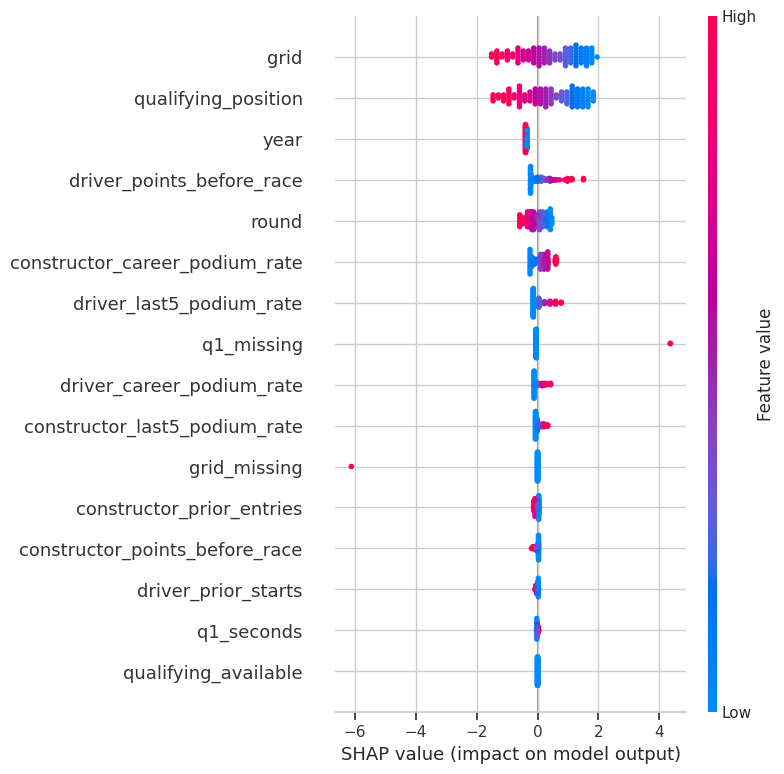

In [118]:

# Install SHAP only if unavailable
try:
    import shap
except ImportError:
    import sys
    import subprocess
    subprocess.check_call([
        sys.executable, "-m", "pip",
        "install", "shap", "-q"
    ])
    import shap

# Extract fitted preprocessing and classifier
log_imputer = explain_model.named_steps["imputer"]
log_scaler = explain_model.named_steps["scaler"]
log_classifier = explain_model.named_steps["model"]

def transform_for_shap(data):
    imputed = log_imputer.transform(data)
    return log_scaler.transform(imputed)

# Small representative samples for efficient explanations
background_raw = X_train.sample(
    n=min(200, len(X_train)),
    random_state=42
)

explain_raw = X_val.sample(
    n=min(100, len(X_val)),
    random_state=42
)

background_scaled = transform_for_shap(background_raw)
explain_scaled = transform_for_shap(explain_raw)

shap_explainer = shap.LinearExplainer(
    log_classifier,
    background_scaled
)

shap_values = shap_explainer(explain_scaled)

# Label features clearly
shap_values.feature_names = feature_columns

print("SHAP explanations calculated.")
print("Shape:", shap_values.values.shape)

shap.summary_plot(
    shap_values.values,
    explain_scaled,
    feature_names=feature_columns,
    show=True
)


,Feature,Mean Absolute SHAP
0,grid,0.8851
2,qualifying_position,0.8698
14,year,0.3758
12,driver_points_before_race,0.3096
15,round,0.2680
10,constructor_career_podium_rate,0.2488
8,driver_last5_podium_rate,0.1957
5,q1_missing,0.1305
7,driver_career_podium_rate,0.1299
11,constructor_last5_podium_rate,0.0810


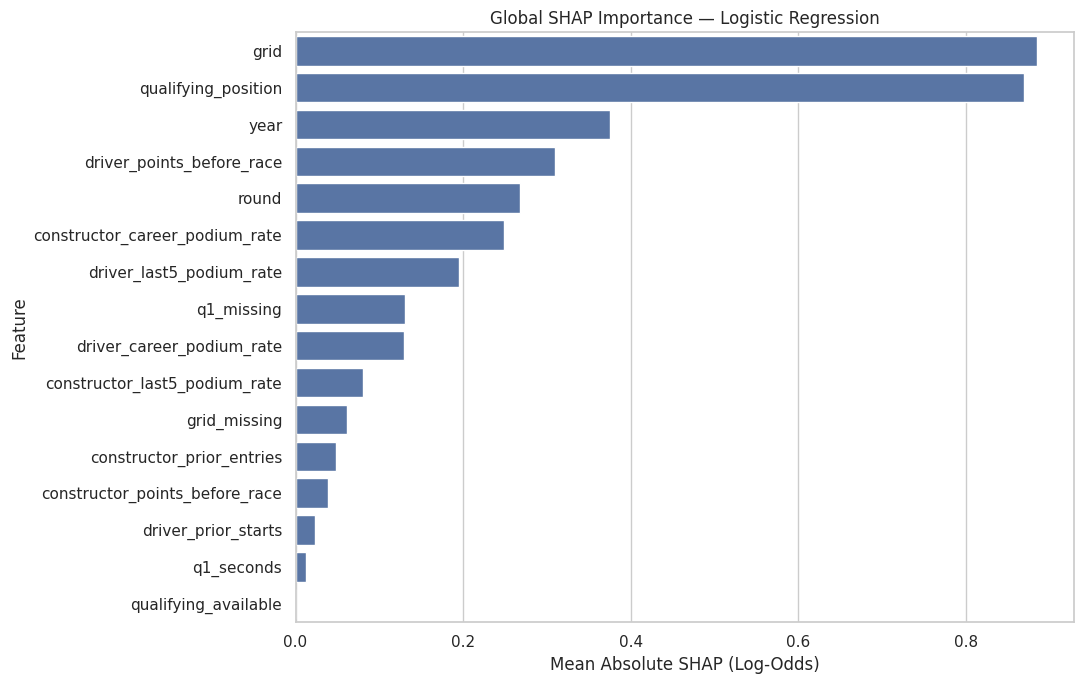

In [119]:

shap_importance = pd.DataFrame({
    "Feature": feature_columns,
    "Mean Absolute SHAP": np.abs(
        shap_values.values
    ).mean(axis=0)
}).sort_values(
    "Mean Absolute SHAP",
    ascending=False
)

display(shap_importance.round(4))

plt.figure(figsize=(11, 7))

sns.barplot(
    data=shap_importance,
    x="Mean Absolute SHAP",
    y="Feature"
)

plt.title("Global SHAP Importance — Logistic Regression")
plt.xlabel("Mean Absolute SHAP (Log-Odds)")
plt.tight_layout()
plt.show()


Selected validation record:
Driver ID: 1
Race ID: 1037
Predicted podium probability: 0.894
Actual podium outcome: 1


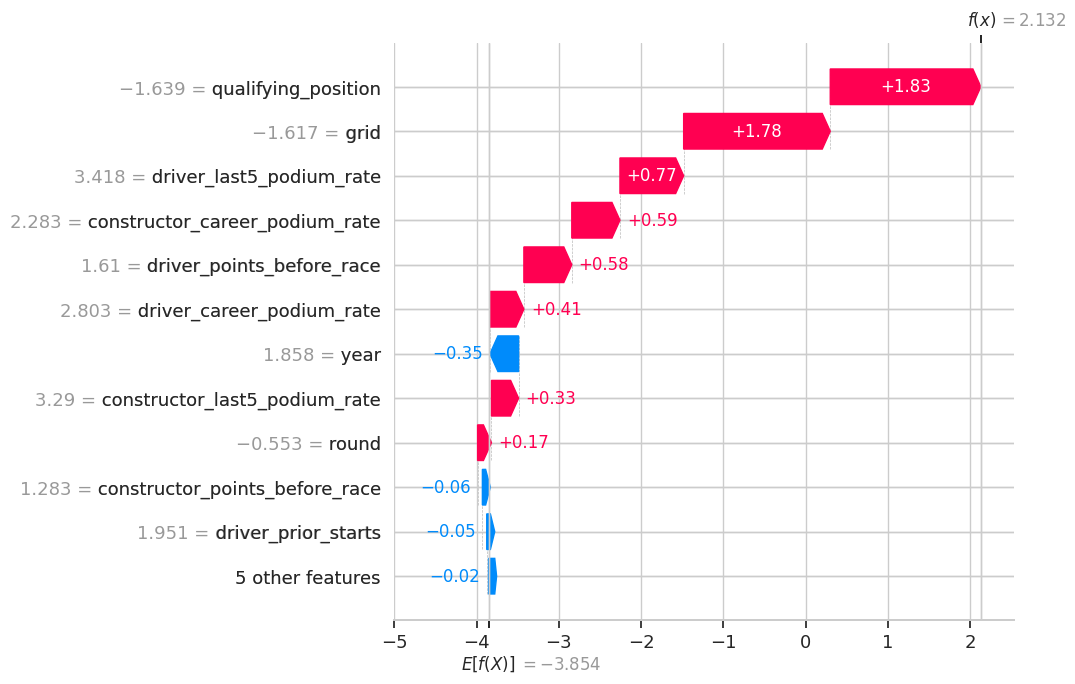

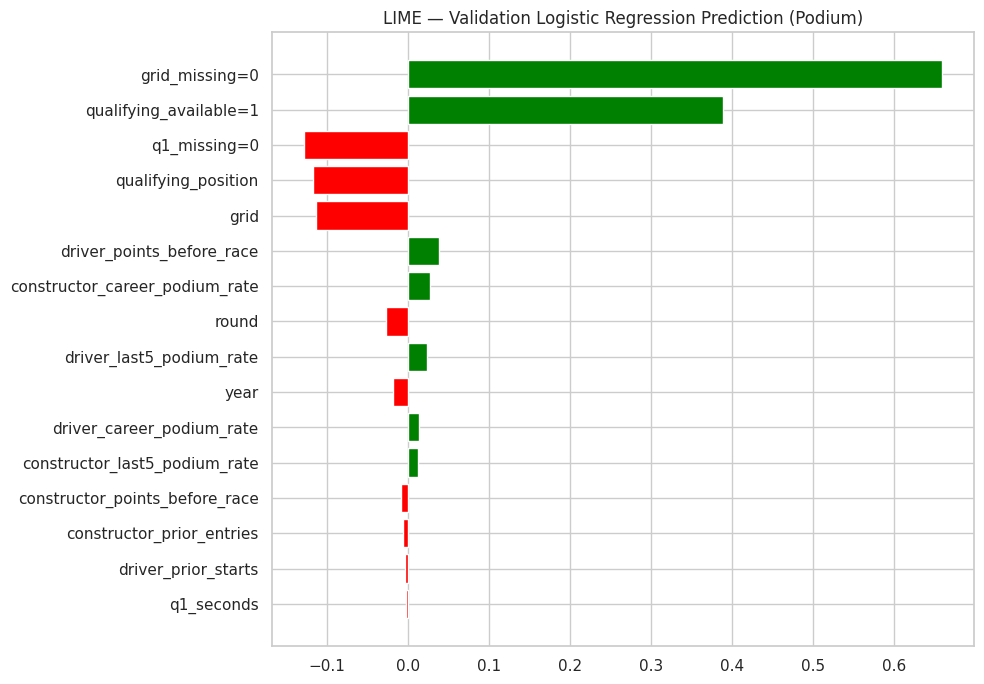

,Feature,LIME probability-surrogate weight,SHAP log-odds contribution,Same direction
0,grid,-0.112504,1.782608e+00,False
1,grid_missing,0.659719,3.002895e-17,True
2,qualifying_position,-0.116334,1.831271e+00,False
3,q1_seconds,-0.001504,1.003283e-02,False
4,qualifying_available,0.389334,-1.543622e-17,False
5,q1_missing,-0.128087,-4.408210e-02,True
6,driver_prior_starts,-0.002880,-5.294960e-02,True
7,driver_career_podium_rate,0.014405,4.127141e-01,True
8,driver_last5_podium_rate,0.023850,7.745639e-01,True
9,constructor_prior_entries,-0.005872,1.142194e-02,False


Top-five absolute-attribution overlap: ['grid', 'qualifying_position']
LIME local surrogate weighted R-squared: 0.8081682713347152
LIME weights describe local probability response slopes, whereas SHAP describes this record's log-odds displacement from a background; signs and sizes need not match.
Independent LIME perturbations may be unrealistic for correlated form/standings features. Both explanations describe model reliance, not causation.


In [120]:
# Select a high-probability validation example
local_probabilities = explain_model.predict_proba(
    explain_raw
)[:, 1]

local_idx = int(np.argmax(local_probabilities))

print("Selected validation record:")
print("Driver ID:",
      val_df.loc[explain_raw.index[local_idx], "driverId"])

print("Race ID:",
      val_df.loc[explain_raw.index[local_idx], "raceId"])

print("Predicted podium probability:",
      round(float(local_probabilities[local_idx]), 4))

print("Actual podium outcome:",
      int(y_val.loc[explain_raw.index[local_idx]]))

# SHAP waterfall for one prediction
shap.plots.waterfall(
    shap_values[local_idx],
    max_display=12,
    show=True
)

# Actual LIME plot for the SAME validation example and Logistic Regression.
try:
    from lime.lime_tabular import LimeTabularExplainer
except ImportError:
    import sys
    import subprocess
    subprocess.check_call([sys.executable, "-m", "pip", "install", "lime", "-q"])
    from lime.lime_tabular import LimeTabularExplainer

# Use the fitted imputer's representation; observed flags remain categorical.
lime_train = log_imputer.transform(X_train)
lime_record = log_imputer.transform(explain_raw.iloc[[local_idx]])[0]
lime_categorical = [feature_columns.index(c) for c in ["grid_missing", "qualifying_available", "q1_missing"]]
lime_explainer = LimeTabularExplainer(
    lime_train, feature_names=feature_columns,
    class_names=["Non-podium", "Podium"], mode="classification",
    categorical_features=lime_categorical, discretize_continuous=False,
    random_state=42, sample_around_instance=True
)
def lime_predict_proba(imputed_rows):
    return log_classifier.predict_proba(log_scaler.transform(imputed_rows))
assert np.allclose(lime_predict_proba(lime_record.reshape(1, -1))[0, 1], local_probabilities[local_idx])
lime_explanation = lime_explainer.explain_instance(
    lime_record, lime_predict_proba, labels=(1,),
    num_features=len(feature_columns), num_samples=1500
)
lime_figure = lime_explanation.as_pyplot_figure(label=1)
lime_figure.set_size_inches(10, 7)
plt.title("LIME — Validation Logistic Regression Prediction (Podium)")
plt.tight_layout()
plt.show()
lime_weights = dict(lime_explanation.as_map()[1])
local_xai_comparison = pd.DataFrame({
    "Feature": feature_columns,
    "LIME probability-surrogate weight": [lime_weights.get(j, 0.0) for j in range(len(feature_columns))],
    "SHAP log-odds contribution": shap_values.values[local_idx]
})
local_xai_comparison["Same direction"] = np.sign(local_xai_comparison["LIME probability-surrogate weight"]) == np.sign(local_xai_comparison["SHAP log-odds contribution"])
display(local_xai_comparison)
lime_top = set(local_xai_comparison.set_index("Feature")["LIME probability-surrogate weight"].abs().nlargest(5).index)
shap_top = set(local_xai_comparison.set_index("Feature")["SHAP log-odds contribution"].abs().nlargest(5).index)
print("Top-five absolute-attribution overlap:", sorted(lime_top & shap_top))
print("LIME local surrogate weighted R-squared:", lime_explanation.score)
print("LIME weights describe local probability response slopes, whereas SHAP describes this record's log-odds displacement from a background; signs and sizes need not match.")
print("Independent LIME perturbations may be unrealistic for correlated form/standings features. Both explanations describe model reliance, not causation.")


### Phase 9 — Explanation Findings and Inference

**Verification status:** Numerical statements were reconciled with the successful clean saved execution (Version 13, 16 October 2026). Audit results, statistical tables and plotted outputs provide the evidence; predictive associations do not establish causation.

Permutation importance identified **qualifying position and starting grid** as the strongest individual predictors of the Logistic Regression model's validation average precision. The SHAP ranking also prioritized **grid and qualifying position**, alongside **year**, pre-race driver points, and historical form. The difference between year’s SHAP attribution and small/negative permutation importance is a reminder that attribution and actual ranking sensitivity are different measurements.

A local SHAP waterfall demonstrates how qualifying/grid and historical performance shift one prediction relative to a background reference; the impacts shown are on **log-odds**, not causal effects.

The separate **neural-network** inference function accepts the 16 engineered pre-race features, applies the existing training-fitted preprocessing, and returns a podium probability, thresholded class, and missing-feature list. A complete validation example produced **0.7233** (class 1), and a partially missing example **0.4717** (class 1), using threshold **0.28**. The partially missing record omitted `q1_seconds`, `driver_last5_podium_rate`, and `constructor_last5_podium_rate`.

The two examples need not be the same original record and therefore do not measure the isolated effect of missingness. This is a **feature-level inference demo**: it does not fetch race-weekend information or construct historical form from driver IDs automatically.

The inference demonstration is deliberately **NN-only**, preserving the existing implementation and NN-specific validation threshold. It does not automatically dispatch through `best_model_name`. The current validation winner is printed by Phase 7 when executed; if another model wins on rerun, NN inference remains a separate model demonstration and must not be described as selected-model inference. LIME/SHAP explain the Logistic Regression baseline, so their attributions are not neural-network explanations. The same-record LIME figure, SHAP waterfall and comparison table executed successfully and are present in the saved output.


In [121]:
# Deliberately NN-only inference demonstration; validation selection is reported separately

def predict_podium(record):
    """
    Predict podium probability from a dictionary of
    pre-race engineered features.

    Missing numeric features are imputed using
    training-only preprocessing.
    """
    if not isinstance(record, dict):
        raise TypeError("record must be a dictionary")

    unknown = set(record) - set(feature_columns)
    if unknown:
        raise ValueError(
            f"Unknown feature names: {sorted(unknown)}"
        )

    input_df = pd.DataFrame(
        [{col: record.get(col, np.nan)
          for col in feature_columns}]
    )

    for col in feature_columns:
        input_df[col] = pd.to_numeric(
            input_df[col],
            errors="coerce"
        )

    # Update indicators from their corresponding inputs
    grid = input_df.at[0, "grid"]
    qpos = input_df.at[0, "qualifying_position"]
    q1 = input_df.at[0, "q1_seconds"]

    input_df["grid_missing"] = int(
        pd.isna(grid) or grid <= 0
    )
    input_df["qualifying_available"] = int(
        pd.notna(qpos)
    )
    input_df["q1_missing"] = int(pd.isna(q1))

    if "year" not in record or "round" not in record:
        raise ValueError(
            "year and round are required for race context"
        )

    processed = standard_preprocessor.transform(
        input_df[feature_columns]
    ).astype("float32")

    probability = float(
        neural_model.predict(
            processed,
            verbose=0
        ).ravel()[0]
    )

    threshold = best_thresholds["Neural Network"]

    return {
        "podium_probability": round(probability, 4),
        "predicted_class": int(probability >= threshold),
        "threshold": float(threshold),
        "missing_features": [
            col for col in feature_columns
            if pd.isna(input_df.at[0, col])
        ]
    }

print("Inference function ready.")


Inference function ready.


In [122]:

# Complete record: choose one with all 16 features available
complete_candidates = X_val.dropna()

if complete_candidates.empty:
    print("No entirely complete validation record available.")
else:
    complete_record = complete_candidates.iloc[0].to_dict()

    complete_prediction = predict_podium(
        complete_record
    )

    print("COMPLETE RECORD PREDICTION")
    print(complete_prediction)

# Partially missing record
partial_record = X_val.iloc[0].to_dict()

partial_record["q1_seconds"] = np.nan
partial_record["driver_last5_podium_rate"] = np.nan
partial_record["constructor_last5_podium_rate"] = np.nan

partial_prediction = predict_podium(partial_record)

print("\nPARTIALLY MISSING RECORD PREDICTION")
print(partial_prediction)


COMPLETE RECORD PREDICTION
{'podium_probability': 0.7233, 'predicted_class': 1, 'threshold': 0.28, 'missing_features': []}

PARTIALLY MISSING RECORD PREDICTION
{'podium_probability': 0.4717, 'predicted_class': 1, 'threshold': 0.28, 'missing_features': ['q1_seconds', 'driver_last5_podium_rate', 'constructor_last5_podium_rate']}


In [123]:

from pathlib import Path

xai_dir = Path("/kaggle/working/phase9_xai")
xai_dir.mkdir(parents=True, exist_ok=True)

permutation_df.to_csv(
    xai_dir / "permutation_importance.csv",
    index=False
)

shap_importance.to_csv(
    xai_dir / "shap_importance.csv",
    index=False
)

pd.DataFrame([
    {
        "Record": "Partially missing",
        **partial_prediction
    }
]).to_csv(
    xai_dir / "inference_results.csv",
    index=False
)

print("Phase 9 outputs saved successfully.")


Phase 9 outputs saved successfully.


## Phase 10 — Reproducibility, Final Audit, and Submission

The final structural audit verifies the presence of the 14 cleaned tables, unique driver–race rows, 16 numeric predictors, the three trained models, preprocessing/ablation experiments, XAI outputs, inference capability, forbidden-column exclusion, and chronological split integrity. Report tables are exported for the accompanying analytical PDF.

**Limitations:** Historical shared drives require deterministic deduplication; qualifying coverage changes by era; one anomalous Q1 value is flagged rather than invented; status-based mechanical-retirement classification cannot establish every exact cause or actual start; reconstructed season points may differ from official standings; historical competition and constructor identities change; and checking forbidden feature names alone cannot prove all temporal relationships are correct.

**Submission package:** one successfully executed Kaggle notebook with plots and Markdown answers, an analytical PDF report including the three data-engineering questions and figures, and an accessible GitHub repository. The final submission requires a successful complete execution with visible outputs. The authorized clean saved execution completed successfully and its outputs were inspected. This validation changes neither sharing nor GitHub and does not submit the assignment.


In [124]:
# PHASE 10 — Final notebook audit

from pathlib import Path
import pandas as pd
import numpy as np

checks = {}

checks["All 14 cleaned tables"] = len(clean_tables) == 14

checks["Unique driver-race records"] = (
    not modeling_table.duplicated(
        ["raceId", "driverId"]
    ).any()
)

checks["16 model predictors"] = len(feature_columns) == 16

checks["Three trained models"] = (
    len(trained_models) == 2
    and neural_model is not None
)

checks["Three preprocessing experiments"] = (
    len(preprocessing_results) == 3
)

checks["Seven ablation configurations"] = (
    len(ablation_results) == 7
)

checks["SHAP shape correct"] = (
    shap_values.values.shape[1] == len(feature_columns)
)

checks["Permutation importance shape correct"] = (
    len(permutation_df) == len(feature_columns)
)

checks["Inference function working"] = (
    0 <= partial_prediction["podium_probability"] <= 1
)

forbidden_features = {
    "podium", "positionOrder", "positionText",
    "statusId", "points", "laps",
    "milliseconds", "fastestLap",
    "fastestLapTime", "fastestLapSpeed",
    "time"
}

checks["No forbidden target columns"] = (
    not bool(set(feature_columns) & forbidden_features)
)

checks["Split years valid"] = (
    train_df["year"].max() < val_df["year"].min()
    and val_df["year"].max() < test_df["year"].min()
)

audit_results = pd.DataFrame([
    {"Check": name, "Status": "PASS" if passed else "FAIL"}
    for name, passed in checks.items()
])

display(audit_results)

assert all(checks.values()), "Final audit has failed checks."

print("Final structural notebook audit passed.")

# Additional corrections are execution checks, not a claim of a completed run.
assert len(primary_keys) == 14
assert pk_report[["Duplicate keys", "Rows with null key"]].eq(0).all().all()
assert fk_report["Status"].eq("PASS").all()
assert len(second_order_results) == 2
assert len(order_equivalence) == 2
assert len(local_xai_comparison) == len(feature_columns)
assert len(all_model_metrics) == 9
for record in source_manifest.to_dict("records"):
    source_file = next(p for p in csv_files if p.name == record["Table"] + ".csv")
    assert hashlib.sha256(source_file.read_bytes()).hexdigest() == record["SHA256"], "Raw CSV changed during pipeline"
print("Extended audit passed: complete key checks, two order experiments, LIME and all model/split metrics.")


,Check,Status
0,All 14 cleaned tables,PASS
1,Unique driver-race records,PASS
2,16 model predictors,PASS
3,Three trained models,PASS
4,Three preprocessing experiments,PASS
5,Seven ablation configurations,PASS
6,SHAP shape correct,PASS
7,Permutation importance shape correct,PASS
8,Inference function working,PASS
9,No forbidden target columns,PASS


Final structural notebook audit passed.
Extended audit passed: complete key checks, two order experiments, LIME and all model/split metrics.


In [125]:
from pathlib import Path

report_dir = Path("/kaggle/working/report_tables")
report_dir.mkdir(parents=True, exist_ok=True)

report_tables = {
    "phase4_q1_circuit_ranking": circuit_ranking,
    "phase4_q1_era_comparison": era_wide,
    "phase4_q2_robustness": robustness_results,
    "phase4_q3_era_summary": era_summary,
    "phase4_q3_constructors": top_constructors,
    "phase6_split_summary": split_summary,
    "phase7_model_comparison": model_comparison,
    "phase7_test_results": test_results,
    "phase8_preprocessing": preprocessing_results,
    "phase8_ablation": ablation_results,
    "phase9_permutation": permutation_df,
    "phase9_shap": shap_importance,
    "source_manifest": source_manifest,
    "primary_key_audit": pk_report,
    "foreign_key_audit": fk_report,
    "phase4_q1_sensitivity": q1_sensitivity,
    "phase4_q2_uncertainty": q2_uncertainty,
    "phase4_q3_status_mapping": q3_status_mapping,
    "phase4_q3_sensitivity": q3_sensitivity,
    "phase8_second_order": second_order_results,
    "phase8_order_distributions": order_distributions,
    "phase8_order_equivalence": order_equivalence,
    "phase9_local_lime_shap": local_xai_comparison
}

for name, df in report_tables.items():
    df.to_csv(
        report_dir / f"{name}.csv",
        index=True
    )

print("Exported", len(report_tables), "report tables.")


Exported 23 report tables.


## Final Conclusion

**Verification status:** Numerical statements were reconciled with the successful clean saved execution (Version 13, 16 October 2026). Audit results, statistical tables and plotted outputs provide the evidence; predictive associations do not establish causation.

This milestone demonstrates an end-to-end pipeline from 14 relational Formula 1 tables to validated driver–race observations and pre-race podium classification. The analysis identifies strong associations between starting/qualifying position and podium likelihood; answers the circuit, home-country, and mechanical-retirement questions using multi-table joins; compares two statistical models with a shallow neural network; and interprets model predictions globally and locally.

The **validation-selected neural network** and the stronger **retrospective Logistic Regression test performance** illustrate why model selection must be separated from held-out evaluation. Most importantly, estimated probabilities and explanations should be read as **predictive associations**, not guaranteed race outcomes or causal effects. Future work could strengthen official-standings reconstruction, race-start eligibility, time-specific feature auditing, calibration, and robustness across different modern seasons.

The clean saved execution passed the corrected key assertions, temporal checks, sensitivity analyses, both preprocessing-order experiments, plotted LIME/SHAP and all model/split metric checks. Both complete-record and partially missing-record inference demonstrations executed successfully. Numerical conclusions above were reconciled with the actual saved outputs. Historical-status ambiguity, retrospective source corrections, validation reuse and earlier test inspection remain methodological limitations, rather than evidence of a pristine untouched-test study.
